In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('/content/biomass_dataset_v2.csv')


In [3]:
df.shape

(5265, 37)

In [4]:
#DATA VALIDATION

In [5]:
df_clean = df.copy()

In [6]:
df_clean['calendar_date'] = pd.to_datetime(df_clean['calendar_date'])

In [7]:
df_clean['calendar_date'].dtype

dtype('<M8[ns]')

In [8]:
# Version 2 — Create working dataframe
df_clean = df.copy()

print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

Dataset shape: (5265, 37)
Missing values: 4080
Duplicate rows: 0


In [9]:
df_clean.shape

(5265, 37)

In [10]:
df_clean.isnull().sum().sum()

np.int64(4080)

In [11]:
df_clean.duplicated().sum()

np.int64(0)

In [12]:
df_clean.to_csv('/content/dssat_prosail_cleaned.csv', index=False)

In [13]:
# Exploratory Data Analysis (EDA)

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
df_clean['dssat_biomass_kg_ha'].describe()

,dssat_biomass_kg_ha
count,5265.000000
mean,2846.629250
std,2244.712892
min,5.000000
25%,415.000000
50%,2736.000000
75%,4632.000000
max,7264.000000


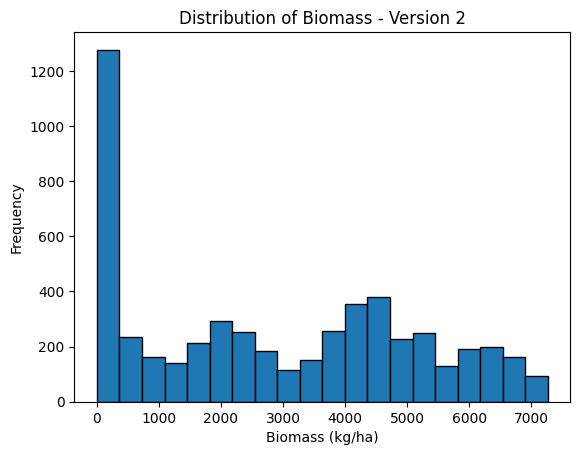

In [16]:
# Version 2 - Biomass Distribution

plt.hist(
    df_clean['dssat_biomass_kg_ha'],
    bins=20,
    edgecolor='black'
)

plt.xlabel('Biomass (kg/ha)')
plt.ylabel('Frequency')
plt.title('Distribution of Biomass - Version 2')
plt.show()

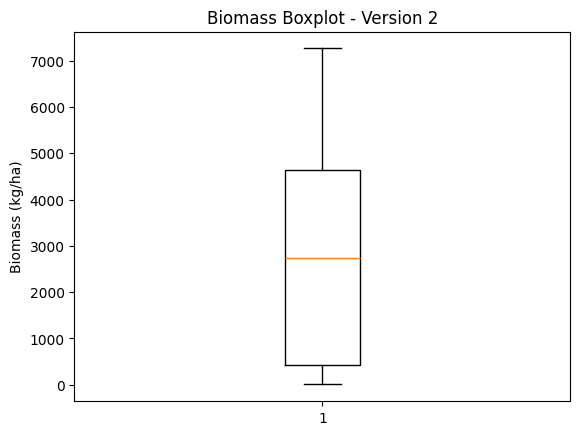

In [17]:
# Version 2 - Biomass Boxplot

plt.boxplot(df_clean['dssat_biomass_kg_ha'])

plt.ylabel('Biomass (kg/ha)')
plt.title('Biomass Boxplot - Version 2')
plt.show()

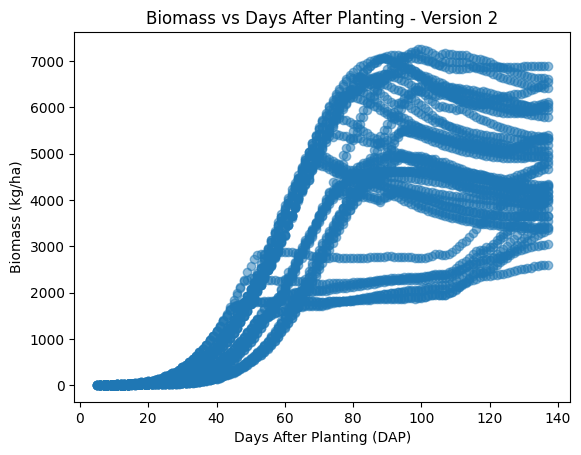

In [18]:
# Version 2 - Biomass vs Days After Planting

plt.scatter(
    df_clean['dap'],
    df_clean['dssat_biomass_kg_ha'],
    alpha=0.5
)

plt.xlabel('Days After Planting (DAP)')
plt.ylabel('Biomass (kg/ha)')
plt.title('Biomass vs Days After Planting - Version 2')
plt.show()

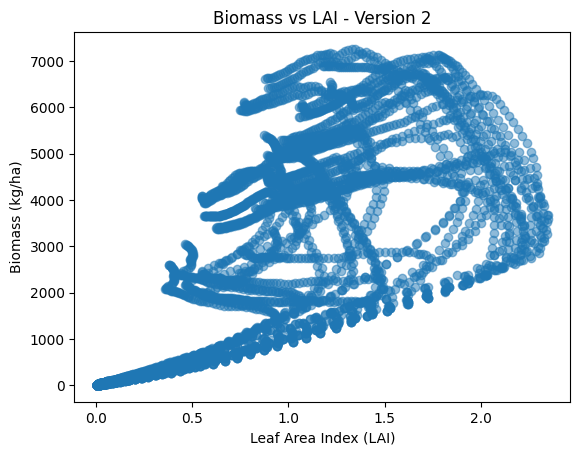

In [19]:
# Version 2 - Biomass vs Leaf Area Index (LAI)

plt.scatter(
    df_clean['dssat_lai'],
    df_clean['dssat_biomass_kg_ha'],
    alpha=0.5
)

plt.xlabel('Leaf Area Index (LAI)')
plt.ylabel('Biomass (kg/ha)')
plt.title('Biomass vs LAI - Version 2')
plt.show()

In [20]:
# Version 2 - Correlation: DAP, LAI, and Biomass

df_clean[
    ['dap', 'dssat_lai', 'dssat_biomass_kg_ha']
].corr()

,dap,dssat_lai,dssat_biomass_kg_ha
dap,1.000000,0.456269,0.811242
dssat_lai,0.456269,1.000000,0.724127
dssat_biomass_kg_ha,0.811242,0.724127,1.000000


In [21]:
hls = [
    'HLS_Blue',
    'HLS_Green',
    'HLS_Red',
    'HLS_NIR',
    'HLS_SWIR1',
    'HLS_SWIR2'
]

In [22]:
# Version 2 - HLS Bands Correlation with Biomass

hls_corr = df_clean[hls + ['dssat_biomass_kg_ha']].corr()

hls_corr

,HLS_Blue,HLS_Green,HLS_Red,HLS_NIR,HLS_SWIR1,HLS_SWIR2,dssat_biomass_kg_ha
HLS_Blue,1.000000,0.981119,0.998903,0.050254,0.951109,0.995838,-0.613664
HLS_Green,0.981119,1.000000,0.975704,0.195746,0.982109,0.983239,-0.502247
HLS_Red,0.998903,0.975704,1.000000,0.019872,0.943002,0.995241,-0.626074
HLS_NIR,0.050254,0.195746,0.019872,1.000000,0.312451,0.068234,0.467232
HLS_SWIR1,0.951109,0.982109,0.943002,0.312451,1.000000,0.964911,-0.456131
HLS_SWIR2,0.995838,0.983239,0.995241,0.068234,0.964911,1.000000,-0.609578
dssat_biomass_kg_ha,-0.613664,-0.502247,-0.626074,0.467232,-0.456131,-0.609578,1.000000


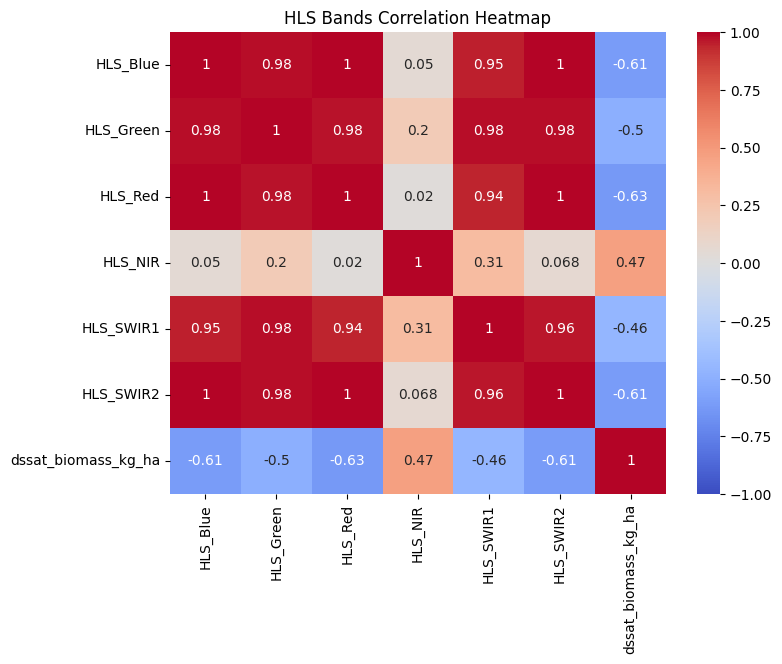

In [23]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    hls_corr,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('HLS Bands Correlation Heatmap')
plt.show()

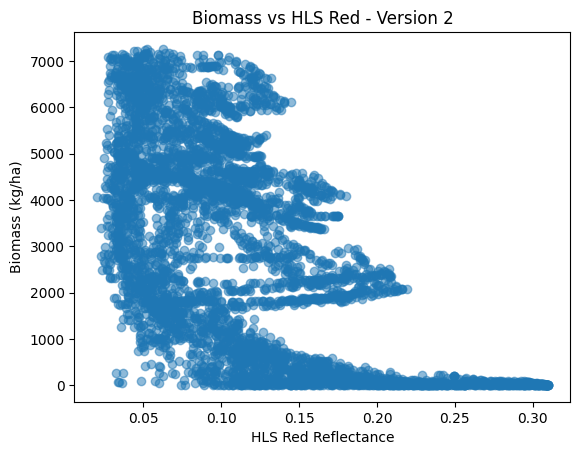

In [24]:
# Version 2 - Biomass vs HLS Red Reflectance

plt.scatter(
    df_clean['HLS_Red'],
    df_clean['dssat_biomass_kg_ha'],
    alpha=0.5
)

plt.xlabel('HLS Red Reflectance')
plt.ylabel('Biomass (kg/ha)')
plt.title('Biomass vs HLS Red - Version 2')
plt.show()

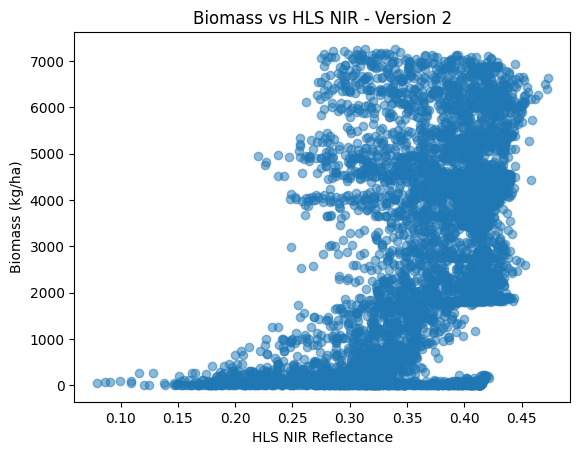

In [25]:
# Version 2 - Biomass vs HLS NIR Reflectance

plt.scatter(
    df_clean['HLS_NIR'],
    df_clean['dssat_biomass_kg_ha'],
    alpha=0.5
)

plt.xlabel('HLS NIR Reflectance')
plt.ylabel('Biomass (kg/ha)')
plt.title('Biomass vs HLS NIR - Version 2')
plt.show()

In [26]:
# Version 2 - HLS Bands Ranked by Biomass Correlation

hls_corr['dssat_biomass_kg_ha'].sort_values()

,dssat_biomass_kg_ha
HLS_Red,-0.626074
HLS_Blue,-0.613664
HLS_SWIR2,-0.609578
HLS_Green,-0.502247
HLS_SWIR1,-0.456131
HLS_NIR,0.467232
dssat_biomass_kg_ha,1.000000


In [27]:
s2 = [col for col in df_clean.columns if col.startswith('S2_')]
wg = [col for col in df_clean.columns if col.startswith('WG_')]

print('Sentinel-2 bands:', len(s2))
print('WeedsGalore bands:', len(wg))

Sentinel-2 bands: 12
WeedsGalore bands: 0


In [28]:
# Version 2 - Sentinel-2 Bands Ranked by Biomass Correlation

s2 = [col for col in df_clean.columns if col.startswith('S2_')]

s2_corr = df_clean[s2 + ['dssat_biomass_kg_ha']].corr()

s2_corr['dssat_biomass_kg_ha'].sort_values()

,dssat_biomass_kg_ha
S2_B4_Red,-0.633585
S2_B1_CoastalAerosol,-0.631889
S2_B12_SWIR2,-0.609079
S2_B2_Blue,-0.596505
S2_B3_Green,-0.495733
S2_B5_RedEdge1,-0.464552
S2_B11_SWIR1,-0.455170
S2_B6_RedEdge2,0.369511
S2_B9_WaterVapor,0.393864
S2_B8A_NIR_Narrow,0.467532


In [29]:
# Version 2 - Sentinel-2 Correlation with Biomass

s2_corr = df_clean[s2 + ['dssat_biomass_kg_ha']].corr()

s2_corr['dssat_biomass_kg_ha'].sort_values()

,dssat_biomass_kg_ha
S2_B4_Red,-0.633585
S2_B1_CoastalAerosol,-0.631889
S2_B12_SWIR2,-0.609079
S2_B2_Blue,-0.596505
S2_B3_Green,-0.495733
S2_B5_RedEdge1,-0.464552
S2_B11_SWIR1,-0.455170
S2_B6_RedEdge2,0.369511
S2_B9_WaterVapor,0.393864
S2_B8A_NIR_Narrow,0.467532


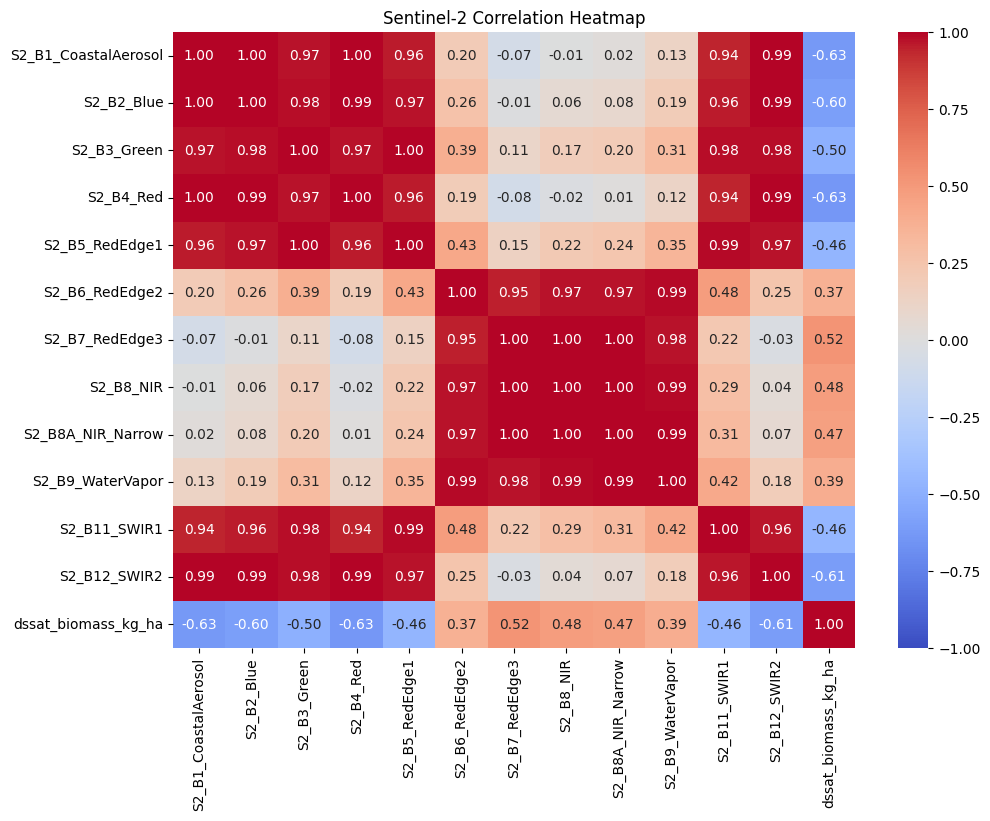

In [30]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    s2_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Sentinel-2 Correlation Heatmap')
plt.show()

In [31]:
reflectance = hls + s2 + wg

print('Total reflectance bands:', len(reflectance))

Total reflectance bands: 18


In [32]:
# Version 2 - All Reflectance Bands vs Biomass

# Include HLS and Sentinel-2 only (no WG bands)
reflectance = hls + s2

reflectance_corr = (
    df_clean[reflectance + ['dssat_biomass_kg_ha']]
    .corr()['dssat_biomass_kg_ha']
    .drop('dssat_biomass_kg_ha')
    .sort_values()
)

reflectance_corr

,dssat_biomass_kg_ha
S2_B4_Red,-0.633585
S2_B1_CoastalAerosol,-0.631889
HLS_Red,-0.626074
HLS_Blue,-0.613664
HLS_SWIR2,-0.609578
S2_B12_SWIR2,-0.609079
S2_B2_Blue,-0.596505
HLS_Green,-0.502247
S2_B3_Green,-0.495733
S2_B5_RedEdge1,-0.464552


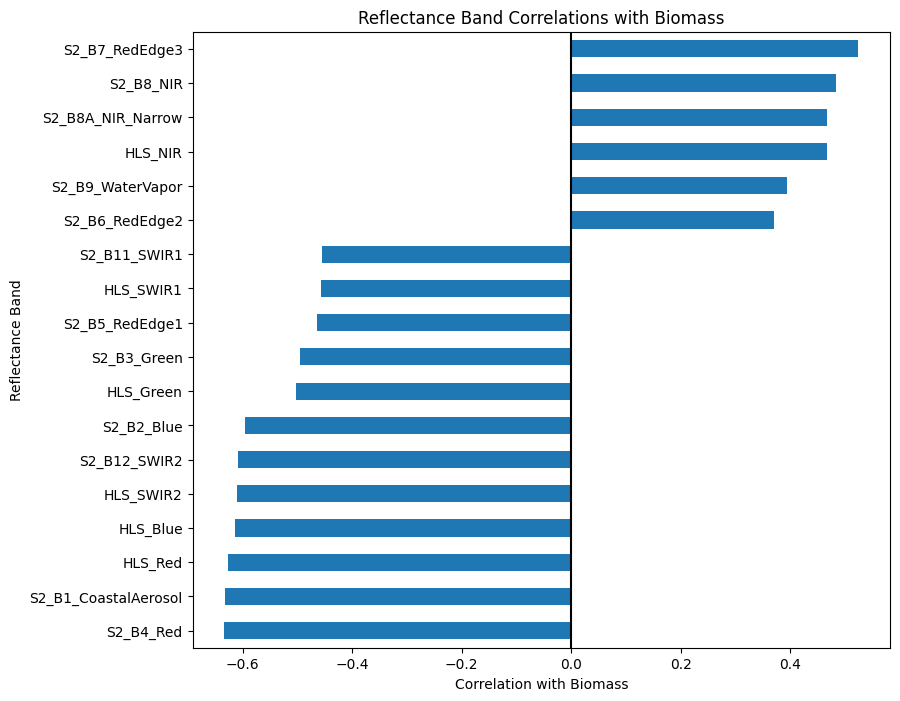

In [33]:
reflectance_corr.plot(kind='barh', figsize=(9, 8))
plt.xlabel('Correlation with Biomass')
plt.ylabel('Reflectance Band')
plt.title('Reflectance Band Correlations with Biomass')
plt.axvline(0, color='black')
plt.show()

In [34]:
# Version 2 - Average Biomass by Treatment

df_clean.groupby('treatment')['dssat_biomass_kg_ha'].mean()

,dssat_biomass_kg_ha
treatment,
1,2794.615502
2,2272.996960
3,3026.790274
4,2939.758359
5,2742.268997
6,2225.656535
7,3573.385432
8,3196.457447


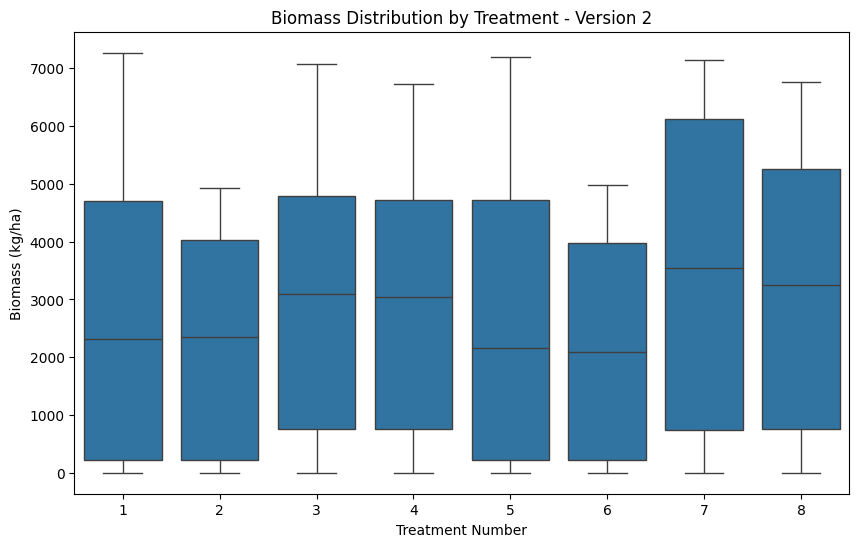

In [35]:
# Version 2 - Biomass Distribution by Treatment

plt.figure(figsize=(10, 6))

sns.boxplot(
    x='treatment',
    y='dssat_biomass_kg_ha',
    data=df_clean
)

plt.xlabel('Treatment Number')
plt.ylabel('Biomass (kg/ha)')
plt.title('Biomass Distribution by Treatment - Version 2')
plt.show()

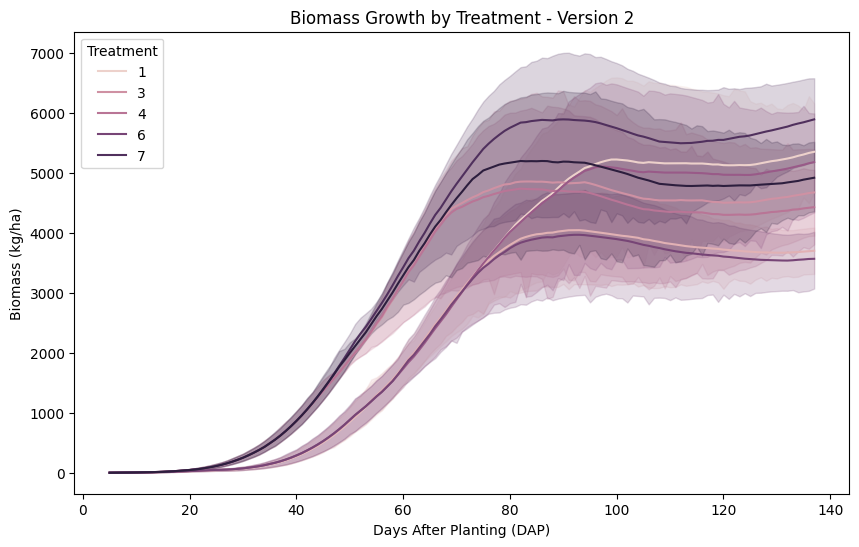

In [36]:
# Version 2 - Biomass Growth by Treatment

plt.figure(figsize=(10, 6))

sns.lineplot(
    x='dap',
    y='dssat_biomass_kg_ha',
    hue='treatment',
    data=df_clean
)

plt.xlabel('Days After Planting (DAP)')
plt.ylabel('Biomass (kg/ha)')
plt.title('Biomass Growth by Treatment - Version 2')
plt.legend(title='Treatment')
plt.show()

In [37]:
print('First date:', df_clean['calendar_date'].min())
print('Last date:', df_clean['calendar_date'].max())
print(df_clean['year'].value_counts().sort_index())

First date: 2019-05-09
Last date: 2023-09-16
year
2019    1048
2020    1049
2021    1048
2022    1064
2023    1056
Name: count, dtype: int64


In [38]:
# BASELINE REGRESSION MODEL
# This model uses the six HLS reflectance bands to predict
# DSSAT-simulated cotton biomass.
# Linear regression is used as a simple baseline model.

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [40]:
# Version 2 - Prepare HLS Features and Biomass Target

X = df_clean[hls]
y = df_clean['dssat_biomass_kg_ha']

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (5265, 6)
y shape: (5265,)


In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print('Training rows:', X_train.shape[0])
print('Testing rows:', X_test.shape[0])

Training rows: 4212
Testing rows: 1053


In [42]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

LinearRegression()

In [43]:
y_pred = linear_model.predict(X_test)

y_pred[:5]

array([2976.83345312, 2869.29945096,  251.99251647, 2891.96894108,
        987.16716017])

In [44]:
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print('Baseline RMSE:', round(rmse, 2))
print('Baseline R-squared:', round(r2, 3))

Baseline RMSE: 1238.2
Baseline R-squared: 0.694


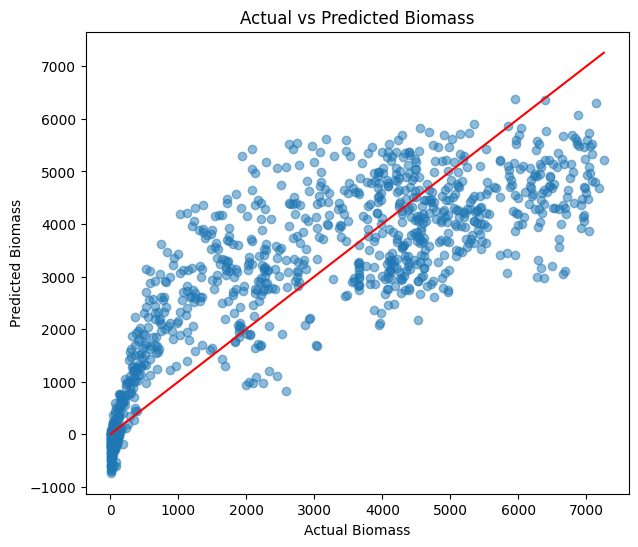

In [45]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel('Actual Biomass')
plt.ylabel('Predicted Biomass')
plt.title('Actual vs Predicted Biomass')

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.show()

In [46]:
# RANDOM FOREST MODEL
# This model can capture nonlinear relationships in the reflectance data.

from sklearn.ensemble import RandomForestRegressor

In [47]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [48]:
rf_rmse = mean_squared_error(y_test, rf_pred) ** 0.5
rf_r2 = r2_score(y_test, rf_pred)

print('Random Forest RMSE:', round(rf_rmse, 2))
print('Random Forest R-squared:', round(rf_r2, 3))

Random Forest RMSE: 1115.78
Random Forest R-squared: 0.752


In [49]:
model_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'RMSE': [rmse, rf_rmse],
    'R-squared': [r2, rf_r2]
})

model_results

,Model,RMSE,R-squared
0,Linear Regression,1238.204228,0.694183
1,Random Forest,1115.778239,0.751668


In [50]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=hls
).sort_values()

feature_importance

,0
HLS_SWIR1,0.043291
HLS_Blue,0.066440
HLS_Green,0.087138
HLS_SWIR2,0.128025
HLS_NIR,0.274979
HLS_Red,0.400127


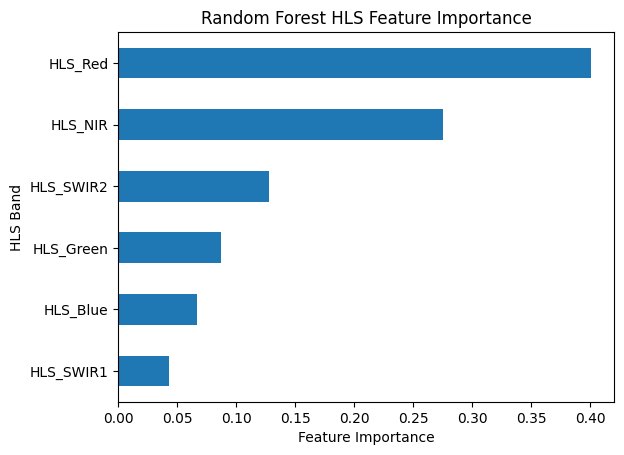

In [51]:
feature_importance.plot(kind='barh')

plt.xlabel('Feature Importance')
plt.ylabel('HLS Band')
plt.title('Random Forest HLS Feature Importance')
plt.show()

In [52]:
selected_hls = ['HLS_Red', 'HLS_NIR']

X_selected = df_clean[selected_hls]

In [53]:
X_train_selected, X_test_selected, y_train_selected, y_test_selected = train_test_split(
    X_selected,
    y,
    test_size=0.20,
    random_state=42
)

In [54]:
selected_rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

selected_rf_model.fit(X_train_selected, y_train_selected)

selected_pred = selected_rf_model.predict(X_test_selected)

selected_rmse = mean_squared_error(y_test_selected, selected_pred) ** 0.5
selected_r2 = r2_score(y_test_selected, selected_pred)

print('Selected Bands RMSE:', round(selected_rmse, 2))
print('Selected Bands R-squared:', round(selected_r2, 3))

Selected Bands RMSE: 1355.15
Selected Bands R-squared: 0.634


In [55]:
# Compare the three models tested so far

model_results = pd.DataFrame({
    'Model': [
        'Linear Regression - 6 HLS Bands',
        'Random Forest - 6 HLS Bands',
        'Random Forest - Red and NIR'
    ],
    'RMSE': [
        rmse,
        rf_rmse,
        selected_rmse
    ],
    'R-squared': [
        r2,
        rf_r2,
        selected_r2
    ]
})

model_results

,Model,RMSE,R-squared
0,Linear Regression - 6 HLS Bands,1238.204228,0.694183
1,Random Forest - 6 HLS Bands,1115.778239,0.751668
2,Random Forest - Red and NIR,1355.147685,0.633689


In [56]:
# Version 2 - YEAR-BASED VALIDATION
# Train on 2019-2022 and test on the unseen year 2023.

train_data = df_clean[df_clean['year'] < 2023]
test_data = df_clean[df_clean['year'] == 2023]

X_train_year = train_data[hls]
X_test_year = test_data[hls]

y_train_year = train_data['dssat_biomass_kg_ha']
y_test_year = test_data['dssat_biomass_kg_ha']

print('Training rows:', len(train_data))
print('Testing rows:', len(test_data))

Training rows: 4209
Testing rows: 1056


In [57]:
# YEAR-BASED LINEAR REGRESSION

year_linear_model = LinearRegression()
year_linear_model.fit(X_train_year, y_train_year)

year_linear_pred = year_linear_model.predict(X_test_year)

year_linear_rmse = mean_squared_error(
    y_test_year, year_linear_pred
) ** 0.5

year_linear_r2 = r2_score(
    y_test_year, year_linear_pred
)

print('Year-based Linear Regression RMSE:', round(year_linear_rmse, 2))
print('Year-based Linear Regression R-squared:', round(year_linear_r2, 3))

Year-based Linear Regression RMSE: 1095.63
Year-based Linear Regression R-squared: 0.695


In [58]:
# YEAR-BASED RANDOM FOREST

year_rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

year_rf_model.fit(X_train_year, y_train_year)

year_rf_pred = year_rf_model.predict(X_test_year)

year_rf_rmse = mean_squared_error(
    y_test_year, year_rf_pred
) ** 0.5

year_rf_r2 = r2_score(
    y_test_year, year_rf_pred
)

print('Year-based Random Forest RMSE:', round(year_rf_rmse, 2))
print('Year-based Random Forest R-squared:', round(year_rf_r2, 3))

Year-based Random Forest RMSE: 1100.14
Year-based Random Forest R-squared: 0.692


In [59]:
# FINAL MODEL COMPARISON

final_model_results = pd.DataFrame({
    'Validation Method': [
        'Random 80/20 Split',
        'Random 80/20 Split',
        'Random 80/20 Split',
        'Year Holdout: 2023',
        'Year Holdout: 2023'
    ],
    'Model': [
        'Linear Regression - 6 HLS Bands',
        'Random Forest - 6 HLS Bands',
        'Random Forest - Red and NIR',
        'Linear Regression - 6 HLS Bands',
        'Random Forest - 6 HLS Bands'
    ],
    'RMSE': [
        rmse,
        rf_rmse,
        selected_rmse,
        year_linear_rmse,
        year_rf_rmse
    ],
    'R-squared': [
        r2,
        rf_r2,
        selected_r2,
        year_linear_r2,
        year_rf_r2
    ]
})

final_model_results

,Validation Method,Model,RMSE,R-squared
0,Random 80/20 Split,Linear Regression - 6 HLS Bands,1238.204228,0.694183
1,Random 80/20 Split,Random Forest - 6 HLS Bands,1115.778239,0.751668
2,Random 80/20 Split,Random Forest - Red and NIR,1355.147685,0.633689
3,Year Holdout: 2023,Linear Regression - 6 HLS Bands,1095.633702,0.694515
4,Year Holdout: 2023,Random Forest - 6 HLS Bands,1100.140648,0.691997


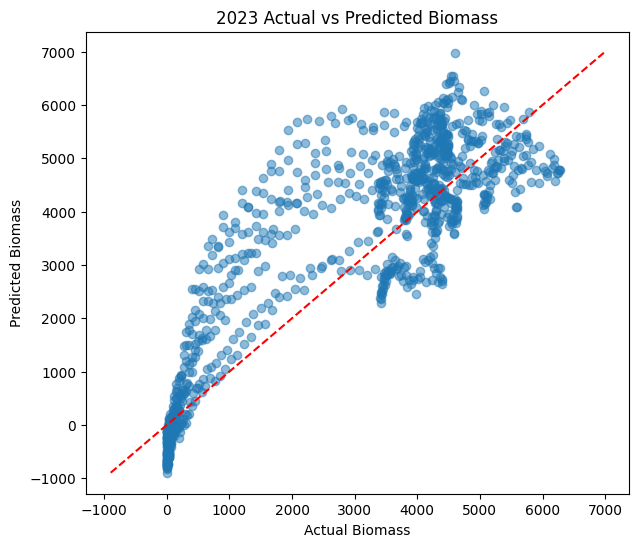

In [60]:
# ACTUAL VS PREDICTED FOR THE BEST YEAR-BASED MODEL

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test_year,
    year_linear_pred,
    alpha=0.5
)

minimum = min(y_test_year.min(), year_linear_pred.min())
maximum = max(y_test_year.max(), year_linear_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color='red',
    linestyle='--'
)

plt.xlabel('Actual Biomass')
plt.ylabel('Predicted Biomass')
plt.title('2023 Actual vs Predicted Biomass')
plt.show()

In [61]:
# TASK 1: RESIDUAL ANALYSIS

# Residual = Predicted - Actual
residuals = year_linear_pred - y_test_year

print("Mean residual:", residuals.mean())
print("Minimum residual:", residuals.min())
print("Maximum residual:", residuals.max())

Mean residual: 401.1389788946312
Minimum residual: -1749.3480238714737
Maximum residual: 3606.4221276118615


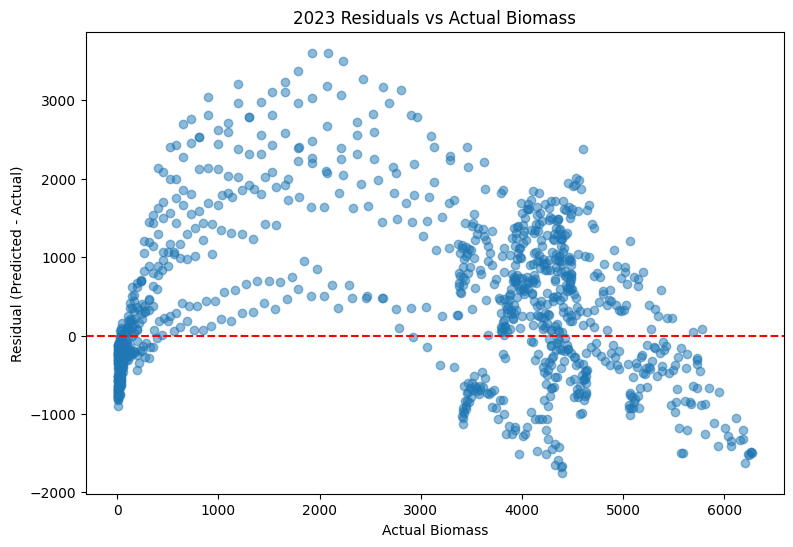

In [62]:
# Residual vs Actual Biomass

plt.figure(figsize=(9, 6))

plt.scatter(y_test_year, residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Actual Biomass')
plt.ylabel('Residual (Predicted - Actual)')
plt.title('2023 Residuals vs Actual Biomass')

plt.show()

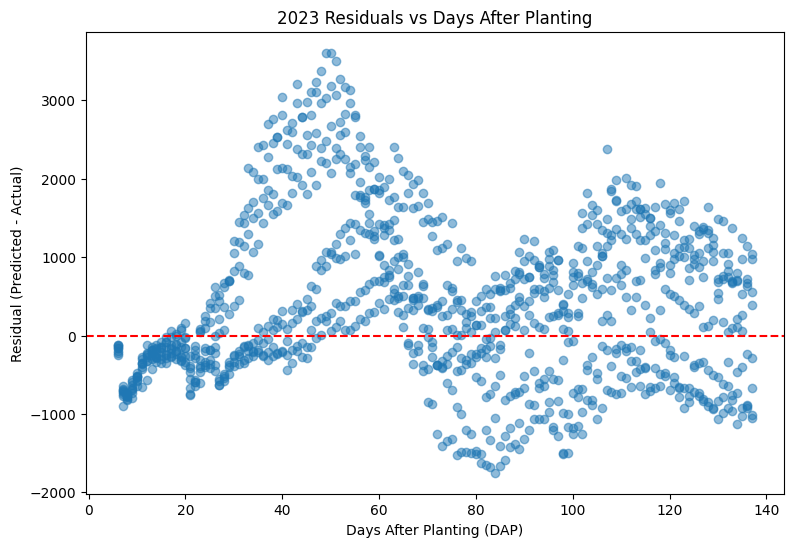

In [63]:
# Residual vs Days After Planting

plt.figure(figsize=(9, 6))

plt.scatter(
    test_data['dap'],
    residuals,
    alpha=0.5
)

plt.axhline(0, color='red', linestyle='--')

plt.xlabel('Days After Planting (DAP)')
plt.ylabel('Residual (Predicted - Actual)')
plt.title('2023 Residuals vs Days After Planting')

plt.show()

In [64]:
# Residual analysis by growth stage

stage_results = test_data[['dap']].copy()
stage_results['residual'] = residuals

stage_results['growth_stage'] = pd.cut(
    stage_results['dap'],
    bins=[0, 30, 70, 140],
    labels=['Early', 'Middle', 'Late'],
    include_lowest=True
)

stage_summary = stage_results.groupby(
    'growth_stage',
    observed=True
)['residual'].agg(
    Count='count',
    Mean_Residual='mean',
    RMSE=lambda x: (x**2).mean()**0.5
)

print(stage_summary.round(2))

              Count  Mean_Residual     RMSE
growth_stage                               
Early           200        -247.48   437.85
Middle          320        1155.32  1565.97
Late            536         192.90   910.73


In [65]:
# TASK 2: NEAR-ZERO BIOMASS ANALYSIS - VERSION 2

# Examine observations with biomass <= 500 kg/ha
near_zero = df_clean[
    df_clean['dssat_biomass_kg_ha'] <= 500
]

print("Total observations:", len(df_clean))
print("Near-zero observations:", len(near_zero))
print("Percentage:", round(len(near_zero) / len(df_clean) * 100, 2))

print("\nDAP statistics for near-zero biomass:")
print(near_zero['dap'].describe())

Total observations: 5265
Near-zero observations: 1372
Percentage: 26.06

DAP statistics for near-zero biomass:
count    1372.000000
mean       23.485423
std        10.724884
min         5.000000
25%        14.000000
50%        23.000000
75%        32.000000
max        50.000000
Name: dap, dtype: float64


In [66]:
# Near-zero biomass prediction errors (2023)

near_zero_results = pd.DataFrame({
    'Actual': y_test_year,
    'Predicted': year_linear_pred
})

near_zero_results['Residual'] = (
    near_zero_results['Predicted']
    - near_zero_results['Actual']
)

low_biomass = near_zero_results[
    near_zero_results['Actual'] <= 500
]

print("2023 near-zero observations:", len(low_biomass))

print(
    "Mean residual:",
    round(low_biomass['Residual'].mean(), 2)
)

print(
    "RMSE:",
    round((low_biomass['Residual']**2).mean()**0.5, 2)
)

2023 near-zero observations: 288
Mean residual: -99.89
RMSE: 513.65


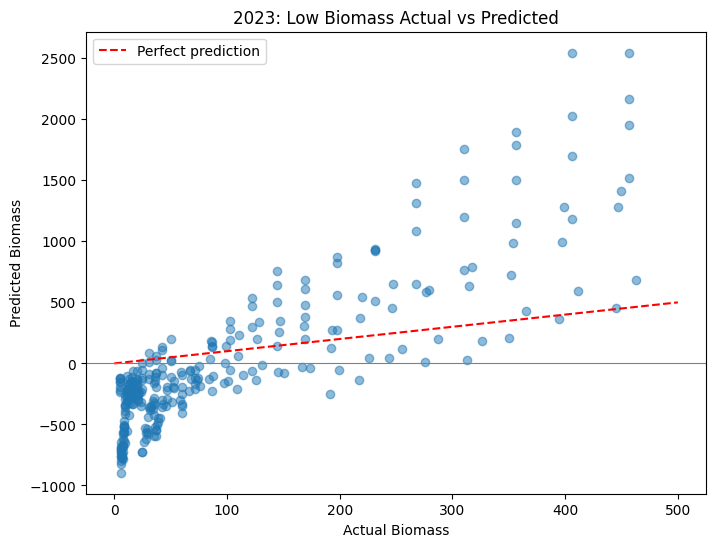

In [67]:
# Actual vs Predicted for Low Biomass (2023)

plt.figure(figsize=(8, 6))

plt.scatter(
    low_biomass['Actual'],
    low_biomass['Predicted'],
    alpha=0.5
)

plt.plot(
    [0, 500],
    [0, 500],
    'r--',
    label='Perfect prediction'
)

plt.axhline(0, color='gray', linewidth=0.8)   # NEW LINE

plt.xlabel('Actual Biomass')
plt.ylabel('Predicted Biomass')
plt.title('2023: Low Biomass Actual vs Predicted')
plt.legend()
plt.show()

In [68]:
# Split near-zero biomass into two size groups

low_biomass = low_biomass.copy()

low_biomass['size_group'] = pd.cut(
    low_biomass['Actual'],
    bins=[0, 100, 500],
    labels=['Under 100', '100–500']
)

print(low_biomass.groupby('size_group', observed=True)['Residual'].agg(
    Count='count',
    Mean_Residual='mean',
    RMSE=lambda x: (x**2).mean()**0.5
).round(2))

print('Negative predictions:', (low_biomass['Predicted'] < 0).sum())

            Count  Mean_Residual   RMSE
size_group                             
Under 100     195        -333.52  403.4
100–500        93         389.98  689.8
Negative predictions: 192


In [69]:
# TASK 3: HIGH-BIOMASS ERROR ANALYSIS (2023)

# Select observations with actual biomass >= 5000
high_mask = y_test_year >= 5000

high_actual = y_test_year[high_mask]
high_pred = year_linear_pred[high_mask]

# Calculate residuals
high_residuals = high_pred - high_actual

print("High-biomass observations:", len(high_actual))
print("Mean residual:", round(high_residuals.mean(), 2))
print("RMSE:", round(
    mean_squared_error(high_actual, high_pred) ** 0.5, 2
))

High-biomass observations: 100
Mean residual: -519.01
RMSE: 822.75


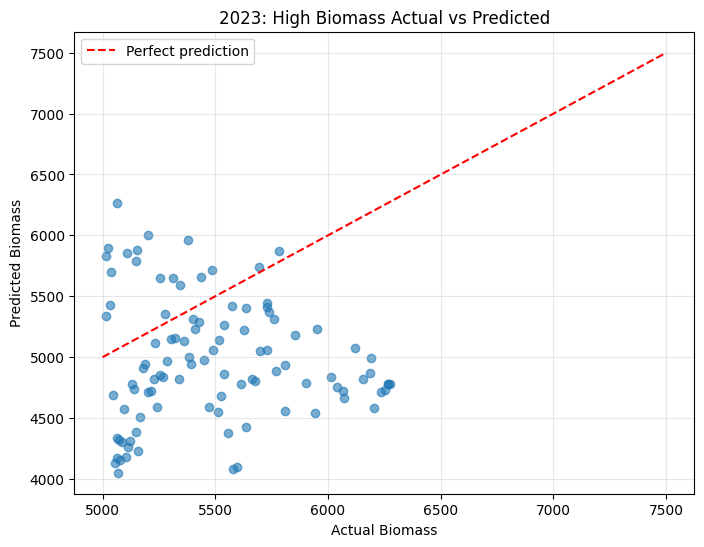

In [70]:
plt.figure(figsize=(8, 6))

plt.scatter(high_actual, high_pred, alpha=0.6)

plt.plot(
    [5000, 7500],
    [5000, 7500],
    'r--',
    label='Perfect prediction'
)

plt.xlabel('Actual Biomass')
plt.ylabel('Predicted Biomass')
plt.title('2023: High Biomass Actual vs Predicted')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

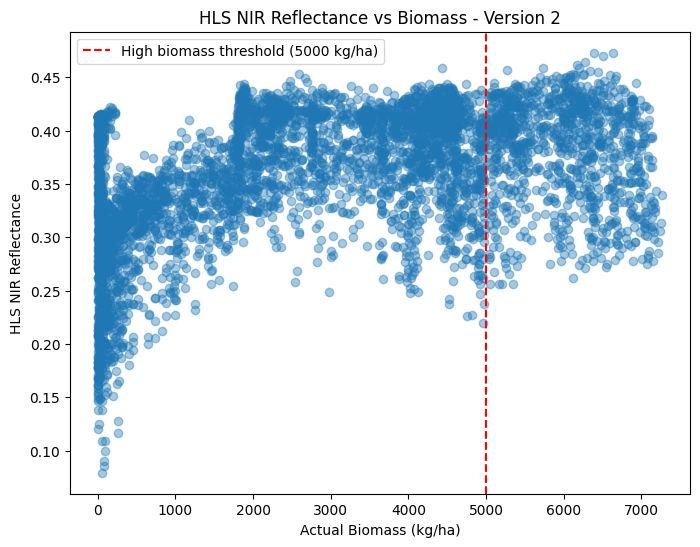

In [71]:
# Version 2 - HLS NIR Reflectance vs Biomass
# Investigating high-biomass reflectance behavior

plt.figure(figsize=(8, 6))

plt.scatter(
    df_clean['dssat_biomass_kg_ha'],
    df_clean['HLS_NIR'],
    alpha=0.4
)

plt.axvline(
    5000,
    color='red',
    linestyle='--',
    label='High biomass threshold (5000 kg/ha)'
)

plt.xlabel('Actual Biomass (kg/ha)')
plt.ylabel('HLS NIR Reflectance')
plt.title('HLS NIR Reflectance vs Biomass - Version 2')
plt.legend()
plt.show()

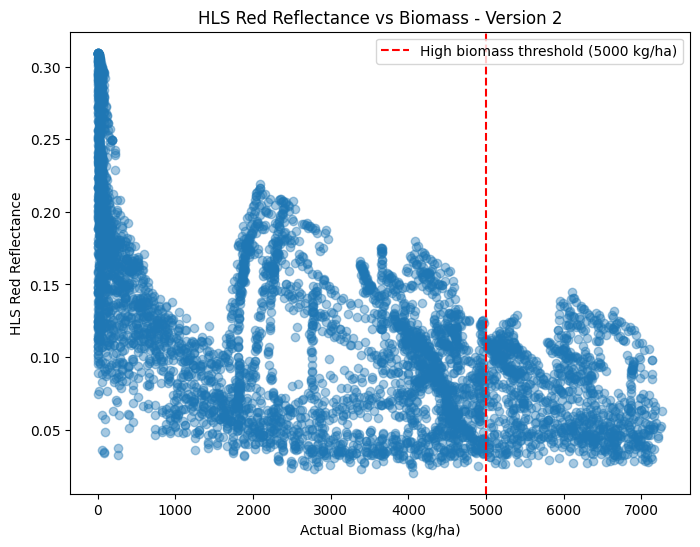

In [72]:
# Version 2 - HLS Red Reflectance vs Biomass
# Investigating high-biomass reflectance behavior

plt.figure(figsize=(8, 6))

plt.scatter(
    df_clean['dssat_biomass_kg_ha'],
    df_clean['HLS_Red'],
    alpha=0.4
)

plt.axvline(
    5000,
    color='red',
    linestyle='--',
    label='High biomass threshold (5000 kg/ha)'
)

plt.xlabel('Actual Biomass (kg/ha)')
plt.ylabel('HLS Red Reflectance')
plt.title('HLS Red Reflectance vs Biomass - Version 2')
plt.legend()
plt.show()

In [73]:
# Compare prediction errors across biomass ranges

error_df = pd.DataFrame({
    'actual': y_test_year.to_numpy(),
    'residual': year_linear_pred - y_test_year.to_numpy()
})

error_df['biomass_range'] = pd.cut(
    error_df['actual'],
    bins=[0, 500, 2000, 4000, 5000, float('inf')],
    labels=['0–500', '500–2000', '2000–4000',
            '4000–5000', '5000+'],
    include_lowest=True
)

error_summary = error_df.groupby(
    'biomass_range', observed=True
)['residual'].agg(
    Count='count',
    Mean_Residual='mean',
    RMSE=lambda x: (x**2).mean()**0.5
)

print(error_summary.round(2))

               Count  Mean_Residual     RMSE
biomass_range                               
0–500            288         -99.89   513.65
500–2000         124        1628.88  1870.15
2000–4000        234         745.46  1323.91
4000–5000        310         412.43   950.61
5000+            100        -519.01   822.75


In [74]:
# Version 2 - 2023 Prediction Errors by Treatment

treatment_errors = pd.DataFrame({
    'treatment': test_data['treatment'].to_numpy(),
    'actual': y_test_year.to_numpy(),
    'predicted': year_linear_pred
})

treatment_errors['residual'] = (
    treatment_errors['predicted']
    - treatment_errors['actual']
)

treatment_summary = treatment_errors.groupby(
    'treatment'
)['residual'].agg(
    Count='count',
    Mean_Residual='mean',
    RMSE=lambda x: (x**2).mean()**0.5
)

print(treatment_summary.round(2))

           Count  Mean_Residual     RMSE
treatment                               
1            132        -256.88   465.15
2            132        -506.65   799.50
3            132        1114.70  1463.34
4            132         527.69  1020.41
5            132         670.53   962.45
6            132         597.19   951.18
7            132         -90.35  1098.00
8            132        1152.87  1590.12


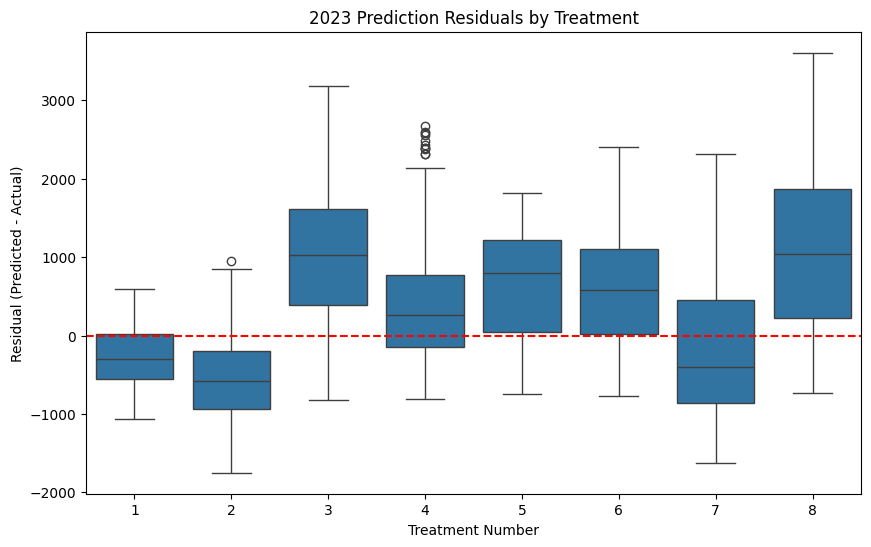

In [75]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=treatment_errors,
    x='treatment',
    y='residual'
)

plt.axhline(0, color='red', linestyle='--')

plt.xlabel('Treatment Number')
plt.ylabel('Residual (Predicted - Actual)')
plt.title('2023 Prediction Residuals by Treatment')
plt.show()

In [76]:
check = treatment_errors.groupby('treatment')['actual'].agg(
    Mean_Biomass='mean', Max_Biomass='max').round(0)
check['RMSE'] = treatment_summary['RMSE'].round(0)
print(check.sort_values('RMSE'))

           Mean_Biomass  Max_Biomass    RMSE
treatment                                   
1                2467.0         4634   465.0
2                2198.0         4401   799.0
6                2160.0         4300   951.0
5                2413.0         4491   962.0
4                2844.0         4964  1020.0
7                3581.0         6274  1098.0
3                2904.0         5038  1463.0
8                3213.0         5784  1590.0


In [77]:
# FEATURE SELECTION: RED + NIR + SWIR2
# Train on 2019–2022, test on 2023

selected_bands = ['HLS_Red', 'HLS_NIR', 'HLS_SWIR2']

X_train_3 = train_data[selected_bands]
X_test_3 = test_data[selected_bands]

# Linear Regression
lr_3 = LinearRegression()
lr_3.fit(X_train_3, y_train_year)

lr_3_pred = lr_3.predict(X_test_3)

# Random Forest
rf_3 = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_3.fit(X_train_3, y_train_year)
rf_3_pred = rf_3.predict(X_test_3)

# Compare performance
results_3 = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'RMSE': [
        mean_squared_error(y_test_year, lr_3_pred)**0.5,
        mean_squared_error(y_test_year, rf_3_pred)**0.5
    ],
    'R-squared': [
        r2_score(y_test_year, lr_3_pred),
        r2_score(y_test_year, rf_3_pred)
    ]
})

print(results_3.round(3))

               Model      RMSE  R-squared
0  Linear Regression  1001.592      0.745
1      Random Forest  1118.703      0.682


In [78]:
# Compare band subsets on the same 2023 holdout

band_sets = {
    'All 6 bands': hls,
    'Red + NIR': ['HLS_Red', 'HLS_NIR'],
    'Red + NIR + SWIR1': ['HLS_Red', 'HLS_NIR', 'HLS_SWIR1'],
    'Red + NIR + SWIR2': ['HLS_Red', 'HLS_NIR', 'HLS_SWIR2'],
}

rows = []
for name, bands in band_sets.items():
    lr = LinearRegression().fit(train_data[bands], y_train_year)
    pred = lr.predict(test_data[bands])
    rows.append({
        'Bands': name,
        'Num_Bands': len(bands),
        'RMSE': mean_squared_error(y_test_year, pred) ** 0.5,
        'R-squared': r2_score(y_test_year, pred)
    })

print(pd.DataFrame(rows).round(3))

               Bands  Num_Bands      RMSE  R-squared
0        All 6 bands          6  1095.634      0.695
1          Red + NIR          2   953.741      0.769
2  Red + NIR + SWIR1          3   981.872      0.755
3  Red + NIR + SWIR2          3  1001.592      0.745


In [79]:
# TASK 4: SENTINEL-2 FEATURE SELECTION

# Automatically retrieve the Sentinel-2 columns
s2_bands = [
    col for col in df_clean.columns
    if col.startswith('S2_')
]

print("Available Sentinel-2 bands:")
print(s2_bands)


Available Sentinel-2 bands:
['S2_B1_CoastalAerosol', 'S2_B2_Blue', 'S2_B3_Green', 'S2_B4_Red', 'S2_B5_RedEdge1', 'S2_B6_RedEdge2', 'S2_B7_RedEdge3', 'S2_B8_NIR', 'S2_B8A_NIR_Narrow', 'S2_B9_WaterVapor', 'S2_B11_SWIR1', 'S2_B12_SWIR2']


In [80]:
s2_sets = {
    'All 12 S2 bands': s2_bands,
    'Red + RedEdge1 (same group)': ['S2_B4_Red', 'S2_B5_RedEdge1'],
    'Red + NIR': ['S2_B4_Red', 'S2_B8_NIR'],
    'Red + RedEdge3': ['S2_B4_Red', 'S2_B7_RedEdge3'],
}

rows = []
for name, bands in s2_sets.items():
    lr = LinearRegression().fit(train_data[bands], y_train_year)
    pred = lr.predict(test_data[bands])
    rows.append({'Bands': name, 'Num_Bands': len(bands),
                 'RMSE': mean_squared_error(y_test_year, pred) ** 0.5,
                 'R-squared': r2_score(y_test_year, pred)})

print(pd.DataFrame(rows).round(3))

                         Bands  Num_Bands      RMSE  R-squared
0              All 12 S2 bands         12  1035.708      0.727
1  Red + RedEdge1 (same group)          2  1004.737      0.743
2                    Red + NIR          2   952.899      0.769
3               Red + RedEdge3          2   958.694      0.766


In [81]:
# Sentinel-2: Full 12 Bands vs Red + Red Edge 1

selected_s2 = ['S2_B4_Red', 'S2_B5_RedEdge1']

# Train and test using the same year-based split
X_train_full = train_data[s2_bands]
X_test_full = test_data[s2_bands]

X_train_reduced = train_data[selected_s2]
X_test_reduced = test_data[selected_s2]

# Full-band model
lr_s2_full = LinearRegression()
lr_s2_full.fit(X_train_full, y_train_year)
pred_s2_full = lr_s2_full.predict(X_test_full)

# Two-band model
lr_s2_reduced = LinearRegression()
lr_s2_reduced.fit(X_train_reduced, y_train_year)
pred_s2_reduced = lr_s2_reduced.predict(X_test_reduced)

# Compare results
s2_results = pd.DataFrame({
    'Model': ['All 12 S2 Bands', 'Red + Red Edge 1'],
    'RMSE': [
        mean_squared_error(y_test_year, pred_s2_full)**0.5,
        mean_squared_error(y_test_year, pred_s2_reduced)**0.5
    ],
    'R-squared': [
        r2_score(y_test_year, pred_s2_full),
        r2_score(y_test_year, pred_s2_reduced)
    ]
})

print(s2_results.round(3))

              Model      RMSE  R-squared
0   All 12 S2 Bands  1035.708      0.727
1  Red + Red Edge 1  1004.737      0.743


In [82]:
import numpy as np

In [83]:
# Version 2 - Sentinel-2 NIR Only
# Fair satellite-based feature experiment

feature_sets = {
    "NIR Only": ["S2_B8_NIR"]
}

results = []

for name, features in feature_sets.items():
    model = LinearRegression()

    model.fit(train_data[features], y_train_year)

    predictions = model.predict(test_data[features])
    predictions = np.maximum(predictions, 0)

    results.append({
        "Model": name,
        "RMSE": mean_squared_error(y_test_year, predictions) ** 0.5,
        "R-squared": r2_score(y_test_year, predictions)
    })

print(pd.DataFrame(results).round(3))

      Model      RMSE  R-squared
0  NIR Only  1286.787      0.579


In [84]:
# Meeting 6 - Task 1: Clip negative predictions to zero

# Keep the original predictions unchanged
year_linear_pred_clipped = year_linear_pred.copy()

# Count negative predictions before clipping
negative_count = (year_linear_pred_clipped < 0).sum()

# Replace all negative biomass predictions with 0
year_linear_pred_clipped[year_linear_pred_clipped < 0] = 0

print("Negative predictions before clipping:", negative_count)
print("Negative predictions after clipping:",
      (year_linear_pred_clipped < 0).sum())

Negative predictions before clipping: 192
Negative predictions after clipping: 0


In [85]:
# Compare model performance before vs after clipping

original_rmse = mean_squared_error(y_test_year, year_linear_pred) ** 0.5
original_r2 = r2_score(y_test_year, year_linear_pred)

clipped_rmse = mean_squared_error(y_test_year, year_linear_pred_clipped) ** 0.5
clipped_r2 = r2_score(y_test_year, year_linear_pred_clipped)

print("BEFORE CLIPPING")
print("RMSE:", round(original_rmse, 2))
print("R-squared:", round(original_r2, 3))

print("\nAFTER CLIPPING")
print("RMSE:", round(clipped_rmse, 2))
print("R-squared:", round(clipped_r2, 3))

BEFORE CLIPPING
RMSE: 1095.63
R-squared: 0.695

AFTER CLIPPING
RMSE: 1081.7
R-squared: 0.702


In [86]:
# Compare low-biomass performance before vs after clipping

low_mask = y_test_year <= 500

low_actual = y_test_year[low_mask]
low_pred_before = year_linear_pred[low_mask]
low_pred_after = year_linear_pred_clipped[low_mask]

low_rmse_before = mean_squared_error(
    low_actual, low_pred_before
) ** 0.5

low_rmse_after = mean_squared_error(
    low_actual, low_pred_after
) ** 0.5

low_residual_before = (low_pred_before - low_actual).mean()
low_residual_after = (low_pred_after - low_actual).mean()

print("LOW BIOMASS (0-500)")
print("Number of observations:", len(low_actual))

print("\nBEFORE CLIPPING")
print("RMSE:", round(low_rmse_before, 2))
print("Mean residual:", round(low_residual_before, 2))

print("\nAFTER CLIPPING")
print("RMSE:", round(low_rmse_after, 2))
print("Mean residual:", round(low_residual_after, 2))

LOW BIOMASS (0-500)
Number of observations: 288

BEFORE CLIPPING
RMSE: 513.65
Mean residual: -99.89

AFTER CLIPPING
RMSE: 390.64
Mean residual: 115.48


In [87]:
# Meeting 6 - Task 1
# Compare original vs clipped Linear Regression predictions

comparison_clipping = pd.DataFrame({
    'Version': ['Before Clipping', 'After Clipping'],
    'RMSE': [
        mean_squared_error(y_test_year, year_linear_pred) ** 0.5,
        mean_squared_error(y_test_year, year_linear_pred_clipped) ** 0.5
    ],
    'R-squared': [
        r2_score(y_test_year, year_linear_pred),
        r2_score(y_test_year, year_linear_pred_clipped)
    ]
})

print(comparison_clipping.round(3))

           Version      RMSE  R-squared
0  Before Clipping  1095.634      0.695
1   After Clipping  1081.701      0.702


In [88]:
# Version 2 - Treatment Distribution by Biomass Range
# Compare treatments within the same biomass ranges (2023)

# Get the 2023 test data
treatment_compare = df_clean[df_clean['year'] == 2023].copy()

# Create biomass ranges
bins = [0, 500, 2000, 4000, 5000, float('inf')]
labels = ['0-500', '500-2000', '2000-4000', '4000-5000', '5000+']

treatment_compare['biomass_range'] = pd.cut(
    treatment_compare['dssat_biomass_kg_ha'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Count observations by treatment and biomass range
treatment_range_counts = pd.crosstab(
    treatment_compare['treatment'],
    treatment_compare['biomass_range']
)

print(treatment_range_counts)
print("\nTotal observations counted:", treatment_range_counts.to_numpy().sum())

biomass_range  0-500  500-2000  2000-4000  4000-5000  5000+
treatment                                                  
1                 43        16         14         59      0
2                 43        16         54         19      0
3                 29        15         29         56      3
4                 29        15         43         45      0
5                 43        16         14         59      0
6                 43        16         57         16      0
7                 29        15         11          6     71
8                 29        15         12         50     26

Total observations counted: 1056


In [89]:
# Version 2 - Task 2, Step 2
# RMSE and Mean Residual by Treatment and Biomass Range
# Model: HLS 6 Bands + Linear Regression (2023 Test)

import numpy as np
from sklearn.linear_model import LinearRegression

# Train a fresh V2 model to avoid mixing V1 predictions
train_data = df_clean[df_clean['year'] < 2023]
test_data = df_clean[df_clean['year'] == 2023]

model = LinearRegression()

model.fit(
    train_data[hls],
    train_data['dssat_biomass_kg_ha']
)

predictions = model.predict(test_data[hls])
predictions = np.maximum(predictions, 0)

# Prepare 2023 results
treatment_compare = test_data.copy()

treatment_compare['prediction'] = predictions

treatment_compare['residual'] = (
    treatment_compare['prediction']
    - treatment_compare['dssat_biomass_kg_ha']
)

# Biomass ranges
bins = [0, 500, 2000, 4000, 5000, float('inf')]
labels = ['0-500', '500-2000', '2000-4000', '4000-5000', '5000+']

treatment_compare['biomass_range'] = pd.cut(
    treatment_compare['dssat_biomass_kg_ha'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate treatment errors within each biomass range
treatment_range_results = (
    treatment_compare
    .groupby(['treatment', 'biomass_range'], observed=True)
    .apply(
        lambda x: pd.Series({
            'Count': len(x),
            'Mean_Residual': x['residual'].mean(),
            'RMSE': (x['residual'] ** 2).mean() ** 0.5
        }),
        include_groups=False
    )
    .reset_index()
)

print(treatment_range_results.round(2).to_string(index=False))

 treatment biomass_range  Count  Mean_Residual    RMSE
         1         0-500   43.0         -65.99   98.91
         1      500-2000   16.0         256.81  303.53
         1     2000-4000   14.0         310.13  350.34
         1     4000-5000   59.0        -455.11  556.85
         2         0-500   43.0         -42.96   89.24
         2      500-2000   16.0         562.25  595.17
         2     2000-4000   54.0        -681.38  819.82
         2     4000-5000   19.0       -1366.50 1385.90
         3         0-500   29.0         338.42  637.00
         3      500-2000   15.0        2649.40 2673.31
         3     2000-4000   29.0        1639.02 1834.43
         3     4000-5000   56.0         941.92 1062.44
         3         5000+    3.0         457.88  480.14
         4         0-500   29.0         248.31  510.10
         4      500-2000   15.0        2152.92 2172.75
         4     2000-4000   43.0         769.73 1091.18
         4     4000-5000   45.0          46.58  342.36
         5

In [90]:
# Version 2 - Task 2, Step 3
# Compare Treatment 7 vs all other treatments
# within the SAME biomass ranges

treatment_compare['group'] = treatment_compare['treatment'].apply(
    lambda x: 'Treatment 7' if x == 7 else 'Other Treatments'
)

trt7_vs_others = (
    treatment_compare
    .groupby(['biomass_range', 'group'], observed=True)
    .apply(
        lambda x: pd.Series({
            'Count': len(x),
            'Mean_Residual': x['residual'].mean(),
            'RMSE': (x['residual'] ** 2).mean() ** 0.5
        }),
        include_groups=False
    )
    .reset_index()
)

print(trt7_vs_others.round(2).to_string(index=False))

biomass_range            group  Count  Mean_Residual    RMSE
        0-500 Other Treatments  259.0         116.41  398.40
        0-500      Treatment 7   29.0         107.25  312.83
     500-2000 Other Treatments  109.0        1607.36 1878.62
     500-2000      Treatment 7   15.0        1785.25 1807.36
    2000-4000 Other Treatments  223.0         688.83 1286.12
    2000-4000      Treatment 7   11.0        1893.58 1937.14
    4000-5000 Other Treatments  304.0         412.34  957.00
    4000-5000      Treatment 7    6.0         416.66  535.35
        5000+ Other Treatments   29.0         222.00  506.54
        5000+      Treatment 7   71.0        -821.68  921.19


In [91]:
# Meeting 6 - Task 3
# Confirm Linear Regression as baseline using 2023 year holdout

baseline_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression - 6 HLS Bands',
        'Random Forest - 6 HLS Bands'
    ],
    'RMSE': [
        mean_squared_error(y_test_year, year_linear_pred) ** 0.5,
        mean_squared_error(y_test_year, year_rf_pred) ** 0.5
    ],
    'R-squared': [
        r2_score(y_test_year, year_linear_pred),
        r2_score(y_test_year, year_rf_pred)
    ]
})

print(baseline_comparison.round(3))

                             Model      RMSE  R-squared
0  Linear Regression - 6 HLS Bands  1095.634      0.695
1      Random Forest - 6 HLS Bands  1100.141      0.692


In [92]:
# Meeting 6 - Task 3
# Final baseline comparison after clipping Linear Regression

baseline_final = pd.DataFrame({
    'Model': [
        'Linear Regression - Original',
        'Linear Regression - Clipped',
        'Random Forest - 6 HLS Bands'
    ],
    'RMSE': [
        mean_squared_error(y_test_year, year_linear_pred) ** 0.5,
        mean_squared_error(y_test_year, year_linear_pred_clipped) ** 0.5,
        mean_squared_error(y_test_year, year_rf_pred) ** 0.5
    ],
    'R-squared': [
        r2_score(y_test_year, year_linear_pred),
        r2_score(y_test_year, year_linear_pred_clipped),
        r2_score(y_test_year, year_rf_pred)
    ]
})

print(baseline_final.round(3))

                          Model      RMSE  R-squared
0  Linear Regression - Original  1095.634      0.695
1   Linear Regression - Clipped  1081.701      0.702
2   Random Forest - 6 HLS Bands  1100.141      0.692


In [93]:
# Check prediction variables currently available

prediction_vars = [
    name for name in globals()
    if 'pred' in name.lower()
]

print(prediction_vars)

['y_pred', 'rf_pred', 'selected_pred', 'year_linear_pred', 'year_rf_pred', 'high_pred', 'lr_3_pred', 'rf_3_pred', 'pred', 'pred_s2_full', 'pred_s2_reduced', 'predictions', 'year_linear_pred_clipped', 'low_pred_before', 'low_pred_after']


In [94]:
# Meeting 6 - Task 4
# Fair comparison: HLS full vs Sentinel-2 full

# Clip negative predictions to zero
hls_full_clipped = year_linear_pred.copy()
hls_full_clipped[hls_full_clipped < 0] = 0

s2_full_clipped = pred_s2_full.copy()
s2_full_clipped[s2_full_clipped < 0] = 0

# Compare both models
full_band_clipped_comparison = pd.DataFrame({
    'Model': [
        'HLS - All 6 Bands',
        'Sentinel-2 - All 12 Bands'
    ],

    'Negative Predictions Before Clipping': [
        (year_linear_pred < 0).sum(),
        (pred_s2_full < 0).sum()
    ],

    'Clipped RMSE': [
        mean_squared_error(y_test_year, hls_full_clipped) ** 0.5,
        mean_squared_error(y_test_year, s2_full_clipped) ** 0.5
    ],

    'Clipped R-squared': [
        r2_score(y_test_year, hls_full_clipped),
        r2_score(y_test_year, s2_full_clipped)
    ]
})

print(full_band_clipped_comparison.round(3).to_string(index=False))

                    Model  Negative Predictions Before Clipping  Clipped RMSE  Clipped R-squared
        HLS - All 6 Bands                                   192      1081.701              0.702
Sentinel-2 - All 12 Bands                                   165      1034.446              0.728


In [95]:
# Version 2 - Meeting 6 Task 4
# Compare all 8 band combinations fairly
# Same Linear Regression, same year split, same zero clipping

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

band_sets = {
    'HLS - All 6 Bands': [
        'HLS_Blue', 'HLS_Green', 'HLS_Red',
        'HLS_NIR', 'HLS_SWIR1', 'HLS_SWIR2'
    ],

    'HLS - Red + NIR': [
        'HLS_Red', 'HLS_NIR'
    ],

    'HLS - Red + NIR + SWIR1': [
        'HLS_Red', 'HLS_NIR', 'HLS_SWIR1'
    ],

    'HLS - Red + NIR + SWIR2': [
        'HLS_Red', 'HLS_NIR', 'HLS_SWIR2'
    ],

    'Sentinel-2 - All 12 Bands': [
        'S2_B1_CoastalAerosol',
        'S2_B2_Blue',
        'S2_B3_Green',
        'S2_B4_Red',
        'S2_B5_RedEdge1',
        'S2_B6_RedEdge2',
        'S2_B7_RedEdge3',
        'S2_B8_NIR',
        'S2_B8A_NIR_Narrow',
        'S2_B9_WaterVapor',
        'S2_B11_SWIR1',
        'S2_B12_SWIR2'
    ],

    'Sentinel-2 - Red + Red Edge 1': [
        'S2_B4_Red', 'S2_B5_RedEdge1'
    ],

    'Sentinel-2 - Red + NIR': [
        'S2_B4_Red', 'S2_B8_NIR'
    ],

    'Sentinel-2 - Red + Red Edge 3': [
        'S2_B4_Red', 'S2_B7_RedEdge3'
    ]
}

# Year-based validation
train_data = df_clean[df_clean['year'] < 2023]
test_data = df_clean[df_clean['year'] == 2023]

target = 'dssat_biomass_kg_ha'

results = []

for name, bands in band_sets.items():

    model = LinearRegression()

    model.fit(
        train_data[bands],
        train_data[target]
    )

    predictions = model.predict(test_data[bands])

    # Count negative predictions before clipping
    negative_count = (predictions < 0).sum()

    # Clip negative biomass predictions to zero
    predictions = np.maximum(predictions, 0)

    rmse = mean_squared_error(
        test_data[target],
        predictions
    ) ** 0.5

    r2 = r2_score(
        test_data[target],
        predictions
    )

    results.append([
        name,
        len(bands),
        negative_count,
        rmse,
        r2
    ])

band_comparison_clipped = pd.DataFrame(
    results,
    columns=[
        'Model',
        'Number of Bands',
        'Negatives Before Clipping',
        'Clipped RMSE',
        'Clipped R-squared'
    ]
)

band_comparison_clipped = band_comparison_clipped.sort_values(
    'Clipped RMSE'
)

print(band_comparison_clipped.round(3).to_string(index=False))

                        Model  Number of Bands  Negatives Before Clipping  Clipped RMSE  Clipped R-squared
       Sentinel-2 - Red + NIR                2                        164       948.653              0.771
              HLS - Red + NIR                2                        164       949.928              0.770
Sentinel-2 - Red + Red Edge 3                2                        162       954.637              0.768
      HLS - Red + NIR + SWIR1                3                        147       979.360              0.756
Sentinel-2 - Red + Red Edge 1                2                        149       987.699              0.752
      HLS - Red + NIR + SWIR2                3                        109       996.244              0.747
    Sentinel-2 - All 12 Bands               12                        165      1034.446              0.728
            HLS - All 6 Bands                6                        192      1081.701              0.702


In [96]:
# Version 2 - Improvement Test 1
# Sentinel-2 (12 Bands) + DAP
# Linear Regression with Zero Clipping

s2_bands = [
    'S2_B1_CoastalAerosol',
    'S2_B2_Blue',
    'S2_B3_Green',
    'S2_B4_Red',
    'S2_B5_RedEdge1',
    'S2_B6_RedEdge2',
    'S2_B7_RedEdge3',
    'S2_B8_NIR',
    'S2_B8A_NIR_Narrow',
    'S2_B9_WaterVapor',
    'S2_B11_SWIR1',
    'S2_B12_SWIR2'
]

features = s2_bands + ['dap']

# Year-based validation
train_data = df_clean[df_clean['year'] < 2023]
test_data = df_clean[df_clean['year'] == 2023]

target = 'dssat_biomass_kg_ha'

# Train Linear Regression
model_s2_dap = LinearRegression()

model_s2_dap.fit(
    train_data[features],
    train_data[target]
)

# Predict biomass
pred_s2_dap = model_s2_dap.predict(test_data[features])

# Count negative predictions
negative_before = (pred_s2_dap < 0).sum()

# Clip negative predictions to zero
pred_s2_dap_clipped = np.maximum(pred_s2_dap, 0)

# Evaluate model
rmse_s2_dap = mean_squared_error(
    test_data[target],
    pred_s2_dap_clipped
) ** 0.5

r2_s2_dap = r2_score(
    test_data[target],
    pred_s2_dap_clipped
)

print("Version 2 - S2 + DAP")
print("Negative predictions before clipping:", negative_before)
print("RMSE:", round(rmse_s2_dap, 3))
print("R-squared:", round(r2_s2_dap, 3))

Version 2 - S2 + DAP
Negative predictions before clipping: 153
RMSE: 694.235
R-squared: 0.877


In [97]:
# Version 2 - Improvement Test 4
# Check S2 + DAP prediction errors across biomass ranges
# 2023 Test Data

biomass_check = test_data.copy()

# Use predictions from V2 Improvement Test 1
biomass_check['prediction'] = pred_s2_dap_clipped

# Residual = Predicted - Actual
biomass_check['residual'] = (
    biomass_check['prediction']
    - biomass_check['dssat_biomass_kg_ha']
)

# Biomass ranges
biomass_check['biomass_range'] = pd.cut(
    biomass_check['dssat_biomass_kg_ha'],
    bins=[0, 500, 2000, 4000, 5000, float('inf')],
    labels=['0-500', '500-2000', '2000-4000', '4000-5000', '5000+'],
    include_lowest=True
)

results = []

for group, data in biomass_check.groupby(
    'biomass_range',
    observed=True
):
    rmse = (
        (data['residual'] ** 2).mean()
    ) ** 0.5

    results.append([
        group,
        len(data),
        data['residual'].mean(),
        rmse
    ])

biomass_error_s2_dap = pd.DataFrame(
    results,
    columns=[
        'Biomass Range',
        'Count',
        'Mean Residual',
        'RMSE'
    ]
)

print(biomass_error_s2_dap.round(2).to_string(index=False))
print("\nTotal observations:", biomass_error_s2_dap['Count'].sum())

Biomass Range  Count  Mean Residual   RMSE
        0-500    288         138.05 314.92
     500-2000    124         358.37 636.08
    2000-4000    234         639.67 802.65
    4000-5000    310         528.24 868.01
        5000+    100        -460.16 677.49

Total observations: 1056


In [98]:
# Version 2 - Improvement Test 5
# Check S2 + DAP prediction errors across actual DSSAT growth stages
# 2023 Test Data

growth_check = test_data.copy()

# Use predictions from V2 Improvement Test 1
growth_check['prediction'] = pred_s2_dap_clipped

# Residual = Predicted - Actual
growth_check['residual'] = (
    growth_check['prediction']
    - growth_check['dssat_biomass_kg_ha']
)

# Calculate errors using actual V2 growth stages
growth_error_s2_dap = (
    growth_check
    .groupby(
        ['dssat_stage_code', 'dssat_stage_name'],
        observed=True
    )['residual']
    .agg(
        Count='count',
        Mean_Residual='mean',
        RMSE=lambda x: (x**2).mean()**0.5
    )
    .reset_index()
    .sort_values('dssat_stage_code')
)

print(growth_error_s2_dap.round(2).to_string(index=False))

print("\nTotal observations:",
      growth_error_s2_dap['Count'].sum())

 dssat_stage_code                 dssat_stage_name  Count  Mean_Residual   RMSE
                0  Vegetative, before first flower    288          86.26 322.68
                1                  R1 first flower     48         530.81 628.17
                3                    R3 first boll     40         675.39 979.06
                5                  R5 boll filling    266         173.25 738.45
                7 R7 physiological maturity begins    120         156.99 607.98
                8              R8 harvest maturity    294         712.10 888.84

Total observations: 1056


In [99]:
# Version 2 - Improvement Test 6
# Compare S2 + DAP prediction errors by treatment
# 2023 Test Data

treatment_check = test_data.copy()

# Use predictions from V2 Improvement Test 1
treatment_check['prediction'] = pred_s2_dap_clipped

# Residual = Predicted - Actual
treatment_check['residual'] = (
    treatment_check['prediction']
    - treatment_check['dssat_biomass_kg_ha']
)

results = []

for treatment, data in treatment_check.groupby('treatment'):

    rmse = (data['residual'] ** 2).mean() ** 0.5

    results.append([
        treatment,
        len(data),
        data['residual'].mean(),
        rmse
    ])

treatment_error_s2_dap = pd.DataFrame(
    results,
    columns=[
        'Treatment',
        'Count',
        'Mean Residual',
        'RMSE'
    ]
)

print(
    treatment_error_s2_dap
    .round(2)
    .to_string(index=False)
)

print("\nTotal observations:",
      treatment_error_s2_dap['Count'].sum())

print("Overall RMSE check:",
      round((treatment_check['residual'] ** 2).mean() ** 0.5, 3))

 Treatment  Count  Mean Residual   RMSE
         1    132         601.29 690.46
         2    132          57.74 460.55
         3    132         516.19 751.73
         4    132         186.79 538.82
         5    132         827.79 995.10
         6    132         297.70 504.42
         7    132        -242.27 644.67
         8    132         418.54 806.94

Total observations: 1056
Overall RMSE check: 694.235


In [100]:
# Version 2 - Improvement Test 7
# Treatment 7 vs Other Treatments Within SAME Biomass Ranges
# Model: Sentinel-2 + DAP
# Test Year: 2023

treatment_range_new = test_data.copy()

# Use predictions from V2 Improvement Test 1
treatment_range_new['prediction'] = pred_s2_dap_clipped

# Residual = Predicted - Actual
treatment_range_new['residual'] = (
    treatment_range_new['prediction']
    - treatment_range_new['dssat_biomass_kg_ha']
)

# Define biomass ranges
treatment_range_new['biomass_range'] = pd.cut(
    treatment_range_new['dssat_biomass_kg_ha'],
    bins=[0, 500, 2000, 4000, 5000, float('inf')],
    labels=[
        '0-500',
        '500-2000',
        '2000-4000',
        '4000-5000',
        '5000+'
    ],
    include_lowest=True
)

# Group Treatment 7 vs all other treatments
treatment_range_new['group'] = treatment_range_new['treatment'].apply(
    lambda x: 'Treatment 7'
    if x == 7
    else 'Other Treatments'
)

results = []

for (biomass_range, group), data in treatment_range_new.groupby(
    ['biomass_range', 'group'],
    observed=True
):

    rmse = (data['residual'] ** 2).mean() ** 0.5

    results.append([
        biomass_range,
        group,
        len(data),
        data['residual'].mean(),
        rmse
    ])

trt7_new_comparison = pd.DataFrame(
    results,
    columns=[
        'Biomass Range',
        'Group',
        'Count',
        'Mean Residual',
        'RMSE'
    ]
)

print(
    trt7_new_comparison
    .round(2)
    .to_string(index=False)
)

print("\nTotal observations:", trt7_new_comparison['Count'].sum())

print("Overall RMSE check:",
      round((treatment_range_new['residual'] ** 2).mean() ** 0.5, 3))

Biomass Range            Group  Count  Mean Residual   RMSE
        0-500 Other Treatments    259         166.15 327.05
        0-500      Treatment 7     29        -112.83 172.26
     500-2000 Other Treatments    109         381.46 634.99
     500-2000      Treatment 7     15         190.55 643.88
    2000-4000 Other Treatments    223         634.33 800.64
    2000-4000      Treatment 7     11         747.81 842.27
    4000-5000 Other Treatments    304         544.95 874.88
    4000-5000      Treatment 7      6        -318.31 382.76
        5000+ Other Treatments     29        -280.49 484.28
        5000+      Treatment 7     71        -533.55 742.07

Total observations: 1056
Overall RMSE check: 694.235


In [101]:
# =====================================================
# MEETING 8 - TASK 1
# Investigating the 2022 Prediction Problem
# Version 2 Dataset
# =====================================================

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Model features and target
features_2022 = s2_bands + ['dap']
target_2022 = 'dssat_biomass_kg_ha'

# Train on 2019-2021, test on 2022
train_2022 = df_clean[df_clean['year'] < 2022].copy()
test_2022 = df_clean[df_clean['year'] == 2022].copy()

# Train Linear Regression
model_2022 = LinearRegression()

model_2022.fit(
    train_2022[features_2022],
    train_2022[target_2022]
)

# Make predictions
pred_2022 = model_2022.predict(
    test_2022[features_2022]
)

# Clip negative predictions to zero
pred_2022_clipped = np.maximum(pred_2022, 0)

# Calculate residuals
residual_2022 = (
    pred_2022_clipped
    - test_2022[target_2022].to_numpy()
)

# Calculate performance
rmse_2022 = mean_squared_error(
    test_2022[target_2022],
    pred_2022_clipped
) ** 0.5

r2_2022 = r2_score(
    test_2022[target_2022],
    pred_2022_clipped
)

# Display results
print("MEETING 8 - TASK 1: 2022 BASELINE")
print("----------------------------------")
print("Training observations:", len(train_2022))
print("Testing observations:", len(test_2022))
print("RMSE:", round(rmse_2022, 3))
print("R-squared:", round(r2_2022, 3))
print("Actual mean:", round(test_2022[target_2022].mean(), 2))
print("Predicted mean:", round(pred_2022_clipped.mean(), 2))
print("Mean residual:", round(residual_2022.mean(), 2))
print("Overpredictions:", (residual_2022 > 0).sum())
print("Underpredictions:", (residual_2022 < 0).sum())

MEETING 8 - TASK 1: 2022 BASELINE
----------------------------------
Training observations: 3145
Testing observations: 1064
RMSE: 1099.498
R-squared: 0.022
Actual mean: 1713.51
Predicted mean: 2357.1
Mean residual: 643.59
Overpredictions: 765
Underpredictions: 299


In [102]:
# Meeting 8 - Task 2
# Investigate 2022 prediction errors by biomass range

error_check_2022 = test_2022.copy()

error_check_2022['prediction'] = pred_2022_clipped

error_check_2022['residual'] = (
    error_check_2022['prediction']
    - error_check_2022['dssat_biomass_kg_ha']
)

error_check_2022['biomass_range'] = pd.cut(
    error_check_2022['dssat_biomass_kg_ha'],
    bins=[0, 500, 2000, 4000, 5000, float('inf')],
    labels=['0-500', '500-2000', '2000-4000', '4000-5000', '5000+'],
    include_lowest=True
)

results_2022 = []

for group, data in error_check_2022.groupby(
    'biomass_range', observed=True
):
    rmse = (data['residual'] ** 2).mean() ** 0.5

    results_2022.append([
        group,
        len(data),
        data['residual'].mean(),
        rmse
    ])

biomass_errors_2022 = pd.DataFrame(
    results_2022,
    columns=['Biomass Range', 'Count', 'Mean Residual', 'RMSE']
)

print(biomass_errors_2022.round(2).to_string(index=False))
print("\nTotal observations:", biomass_errors_2022['Count'].sum())

Biomass Range  Count  Mean Residual    RMSE
        0-500    256         -67.67  167.91
     500-2000    328         418.39  669.51
    2000-4000    461        1118.35 1475.63
    4000-5000     19        2595.51 2597.61

Total observations: 1064


In [103]:
# Meeting 8 - Task 3
# Investigate 2022 prediction errors by treatment

treatment_errors_2022 = (
    error_check_2022
    .groupby('treatment')['residual']
    .agg(
        Count='count',
        Mean_Residual='mean',
        RMSE=lambda x: (x**2).mean()**0.5,
        Overpredictions=lambda x: (x > 0).sum(),
        Underpredictions=lambda x: (x < 0).sum()
    )
    .reset_index()
)

print("2022 Prediction Errors by Treatment")
print("-----------------------------------")
print(treatment_errors_2022.round(2).to_string(index=False))

print("\nTotal observations:",
      treatment_errors_2022['Count'].sum())

2022 Prediction Errors by Treatment
-----------------------------------
 treatment  Count  Mean_Residual    RMSE  Overpredictions  Underpredictions
         1    133         575.40  960.23              104                29
         2    133         225.42  660.40               76                57
         3    133        1048.78 1514.26               99                34
         4    133         880.28 1300.07               98                35
         5    133         761.97 1201.28              104                29
         6    133         450.86  871.24               94                39
         7    133         665.51 1080.03               98                35
         8    133         540.52  980.44               92                41

Total observations: 1064


In [104]:
# Meeting 8 - Task 4
# Investigate 2022 prediction errors by actual DSSAT growth stage
# Baseline: Sentinel-2 + DAP
# Train: 2019-2021 | Test: 2022

stage_errors_2022 = (
    error_check_2022
    .groupby(
        ['dssat_stage_code', 'dssat_stage_name'],
        observed=True
    )
    .agg(
        Count=('residual', 'count'),
        Mean_DAP=('dap', 'mean'),
        Actual_Mean=('dssat_biomass_kg_ha', 'mean'),
        Predicted_Mean=('prediction', 'mean'),
        Mean_Residual=('residual', 'mean'),
        RMSE=('residual', lambda x: (x**2).mean()**0.5)
    )
    .reset_index()
    .sort_values('dssat_stage_code')
)

print("2022 Prediction Errors by Growth Stage")
print("--------------------------------------")

print(
    stage_errors_2022
    .round(2)
    .to_string(index=False)
)

print("\nTotal observations:",
      stage_errors_2022['Count'].sum())

print("Overall RMSE check:",
      round((error_check_2022['residual']**2).mean()**0.5, 3))

2022 Prediction Errors by Growth Stage
--------------------------------------
 dssat_stage_code                 dssat_stage_name  Count  Mean_DAP  Actual_Mean  Predicted_Mean  Mean_Residual    RMSE
                0  Vegetative, before first flower    272     21.50       165.31           77.12         -88.18  202.02
                1                  R1 first flower     48     41.50       944.67          865.29         -79.38  420.92
                3                    R3 first boll     40     47.00      1441.30         1601.04         159.74  471.45
                5                  R5 boll filling    256     65.51      1980.24         2407.35         427.11  502.56
                7 R7 physiological maturity begins    120     89.00      2150.59         2583.00         432.41  599.48
                8              R8 harvest maturity    328    116.99      2775.00         4436.47        1661.47 1872.45

Total observations: 1064
Overall RMSE check: 1099.498


In [105]:
# =====================================================
# MEETING 8 - TASK 5
# Test whether Growth Stage improves 2022 predictions
# Version 2 Dataset
# =====================================================

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# Baseline features
baseline_features = s2_bands + ['dap']

# Add actual DSSAT growth stage
stage_features = baseline_features + ['dssat_stage_name']

target = 'dssat_biomass_kg_ha'

# Use SAME train/test split as Task 1
train_stage = train_2022.copy()
test_stage = test_2022.copy()

# Check missing growth-stage values
print("Missing growth stages in training:",
      train_stage['dssat_stage_name'].isna().sum())

print("Missing growth stages in testing:",
      test_stage['dssat_stage_name'].isna().sum())

# Ensure that all required features are available
assert train_stage[stage_features + [target]].notna().all().all()
assert test_stage[stage_features + [target]].notna().all().all()

# Encode growth stage as a categorical feature
preprocessor = ColumnTransformer(
    transformers=[
        (
            'growth_stage',
            OneHotEncoder(
                drop='first',
                handle_unknown='ignore'
            ),
            ['dssat_stage_name']
        ),
        (
            'numeric',
            'passthrough',
            baseline_features
        )
    ]
)

# Linear Regression with growth-stage encoding
model_stage_2022 = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', LinearRegression())
])

# Train
model_stage_2022.fit(
    train_stage[stage_features],
    train_stage[target]
)

# Predict
pred_stage_2022 = model_stage_2022.predict(
    test_stage[stage_features]
)

# Clip negative predictions
pred_stage_2022_clipped = np.maximum(pred_stage_2022, 0)

# Evaluate
rmse_stage_2022 = mean_squared_error(
    test_stage[target],
    pred_stage_2022_clipped
) ** 0.5

r2_stage_2022 = r2_score(
    test_stage[target],
    pred_stage_2022_clipped
)

residual_stage_2022 = (
    pred_stage_2022_clipped
    - test_stage[target].to_numpy()
)

# Compare against Task 1 baseline
comparison_stage_2022 = pd.DataFrame({
    'Model': [
        'S2 + DAP (Baseline)',
        'S2 + DAP + Growth Stage'
    ],
    'RMSE': [
        rmse_2022,
        rmse_stage_2022
    ],
    'R-squared': [
        r2_2022,
        r2_stage_2022
    ],
    'Mean Residual': [
        residual_2022.mean(),
        residual_stage_2022.mean()
    ]
})

print("\n2022 MODEL COMPARISON")
print(comparison_stage_2022.round(3).to_string(index=False))

print("\nRMSE improvement:",
      round(rmse_2022 - rmse_stage_2022, 3))

print("R-squared change:",
      round(r2_stage_2022 - r2_2022, 3))

Missing growth stages in training: 0
Missing growth stages in testing: 0

2022 MODEL COMPARISON
                  Model     RMSE  R-squared  Mean Residual
    S2 + DAP (Baseline) 1099.498      0.022        643.593
S2 + DAP + Growth Stage 1073.917      0.067        637.316

RMSE improvement: 25.582
R-squared change: 0.045


In [106]:
# =====================================================
# MEETING 8 - TASK 6
# Topsoil Water Exploratory Analysis
# Version 2 Dataset
# =====================================================

soil_col = 'dssat_soil_water_layer1'
target = 'dssat_biomass_kg_ha'

# Check missing values
print("TOPSOIL WATER - DATA QUALITY")
print("--------------------------------")
print("Total missing values:",
      df_clean[soil_col].isna().sum())

print("\nMissing values by year:")
print(
    df_clean.groupby('year')[soil_col]
    .apply(lambda x: x.isna().sum())
)

# Distribution by year
print("\nTOPSOIL WATER STATISTICS BY YEAR")
print("--------------------------------")

soil_summary = (
    df_clean.groupby('year')[soil_col]
    .agg(['count', 'mean', 'min', 'max'])
)

print(soil_summary.round(3).to_string())

# Focus on 2022
soil_check_2022 = error_check_2022[
    [soil_col, target, 'dap', 'residual']
].copy()

print("\n2022 TOPSOIL WATER STATISTICS")
print("--------------------------------")
print(soil_check_2022[soil_col].describe().round(3))

# Correlations with biomass and baseline prediction errors
soil_correlations = soil_check_2022[
    [soil_col, target, 'dap', 'residual']
].corr()

print("\n2022 TOPSOIL WATER CORRELATIONS")
print("--------------------------------")

print(
    soil_correlations.loc[
        soil_col,
        [target, 'dap', 'residual']
    ].round(3)
)

TOPSOIL WATER - DATA QUALITY
--------------------------------
Total missing values: 0

Missing values by year:
year
2019    0
2020    0
2021    0
2022    0
2023    0
Name: dssat_soil_water_layer1, dtype: int64

TOPSOIL WATER STATISTICS BY YEAR
--------------------------------
      count   mean    min    max
year                            
2019   1048  0.249  0.141  0.454
2020   1049  0.252  0.141  0.427
2021   1048  0.265  0.141  0.502
2022   1064  0.195  0.140  0.514
2023   1056  0.240  0.140  0.454

2022 TOPSOIL WATER STATISTICS
--------------------------------
count    1064.000
mean        0.195
std         0.070
min         0.140
25%         0.141
50%         0.149
75%         0.244
max         0.514
Name: dssat_soil_water_layer1, dtype: float64

2022 TOPSOIL WATER CORRELATIONS
--------------------------------
dssat_biomass_kg_ha   -0.087
dap                   -0.230
residual              -0.090
Name: dssat_soil_water_layer1, dtype: float64


In [107]:
# =====================================================
# MEETING 8 - TASK 7
# Test whether Topsoil Water improves 2022 predictions
# Version 2 Dataset
# =====================================================

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Baseline features + topsoil water
soil_features = s2_bands + ['dap', 'dssat_soil_water_layer1']

target = 'dssat_biomass_kg_ha'

# Use SAME training/testing data as Task 1
train_soil = train_2022.copy()
test_soil = test_2022.copy()

# Check missing values
print("Missing training values:",
      train_soil[soil_features + [target]].isna().sum().sum())

print("Missing testing values:",
      test_soil[soil_features + [target]].isna().sum().sum())

# Confirm fair comparison
assert train_soil[soil_features + [target]].notna().all().all()
assert test_soil[soil_features + [target]].notna().all().all()

# Train Linear Regression
model_soil_2022 = LinearRegression()

model_soil_2022.fit(
    train_soil[soil_features],
    train_soil[target]
)

# Predict biomass
pred_soil_2022 = model_soil_2022.predict(
    test_soil[soil_features]
)

# Clip negative predictions to zero
pred_soil_2022_clipped = np.maximum(
    pred_soil_2022, 0
)

# Calculate residuals
residual_soil_2022 = (
    pred_soil_2022_clipped
    - test_soil[target].to_numpy()
)

# Calculate performance
rmse_soil_2022 = mean_squared_error(
    test_soil[target],
    pred_soil_2022_clipped
) ** 0.5

r2_soil_2022 = r2_score(
    test_soil[target],
    pred_soil_2022_clipped
)

# Compare against original Task 1 baseline
comparison_soil_2022 = pd.DataFrame({
    'Model': [
        'S2 + DAP (Baseline)',
        'S2 + DAP + Topsoil Water'
    ],
    'RMSE': [
        rmse_2022,
        rmse_soil_2022
    ],
    'R-squared': [
        r2_2022,
        r2_soil_2022
    ],
    'Mean Residual': [
        residual_2022.mean(),
        residual_soil_2022.mean()
    ]
})

print("\n2022 MODEL COMPARISON")
print("-------------------------------")
print(comparison_soil_2022.round(3).to_string(index=False))

print("\nRMSE improvement:",
      round(rmse_2022 - rmse_soil_2022, 3))

print("RMSE improvement percentage:",
      round(
          (rmse_2022 - rmse_soil_2022)
          / rmse_2022 * 100, 2
      ), "%")

print("R-squared change:",
      round(r2_soil_2022 - r2_2022, 3))

Missing training values: 0
Missing testing values: 0

2022 MODEL COMPARISON
-------------------------------
                   Model     RMSE  R-squared  Mean Residual
     S2 + DAP (Baseline) 1099.498      0.022        643.593
S2 + DAP + Topsoil Water 1097.904      0.024        642.540

RMSE improvement: 1.594
RMSE improvement percentage: 0.14 %
R-squared change: 0.003


In [108]:
# =====================================================
# MEETING 8 - TASK 8
# Compare all three models on identical 2022 test rows
# Include overall and R8 harvest-maturity performance
# =====================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score

actual_2022 = test_2022['dssat_biomass_kg_ha'].to_numpy()

# Identify R8 harvest maturity observations
r8_mask = (
    test_2022['dssat_stage_code'].to_numpy() == 8
)

# Predictions from our completed experiments
models_2022 = {
    'S2 + DAP (Baseline)': pred_2022_clipped,
    'S2 + DAP + Growth Stage': pred_stage_2022_clipped,
    'S2 + DAP + Topsoil Water': pred_soil_2022_clipped
}

results = []

for name, predictions in models_2022.items():

    predictions = np.asarray(predictions)

    assert len(predictions) == len(actual_2022)

    residuals = predictions - actual_2022

    overall_rmse = mean_squared_error(
        actual_2022, predictions
    ) ** 0.5

    overall_r2 = r2_score(
        actual_2022, predictions
    )

    r8_rmse = mean_squared_error(
        actual_2022[r8_mask],
        predictions[r8_mask]
    ) ** 0.5

    r8_mean_residual = residuals[r8_mask].mean()

    results.append([
        name,
        overall_rmse,
        overall_r2,
        residuals.mean(),
        r8_rmse,
        r8_mean_residual
    ])

comparison_2022 = pd.DataFrame(
    results,
    columns=[
        'Model',
        'Overall RMSE',
        'R-squared',
        'Mean Residual',
        'R8 RMSE',
        'R8 Mean Residual'
    ]
)

print("2022 - FINAL THREE-MODEL COMPARISON")
print("-----------------------------------")
print(comparison_2022.round(3).to_string(index=False))

print("\nTotal test observations:", len(actual_2022))
print("R8 observations:", r8_mask.sum())

2022 - FINAL THREE-MODEL COMPARISON
-----------------------------------
                   Model  Overall RMSE  R-squared  Mean Residual  R8 RMSE  R8 Mean Residual
     S2 + DAP (Baseline)      1099.498      0.022        643.593 1872.449          1661.468
 S2 + DAP + Growth Stage      1073.917      0.067        637.316 1681.988          1422.841
S2 + DAP + Topsoil Water      1097.904      0.024        642.540 1870.600          1661.331

Total test observations: 1064
R8 observations: 328


In [109]:
# =====================================================
# MEETING 8 - TASK 9
# Compare Model Errors at Every DSSAT Growth Stage
# Train: 2019-2021 | Test: 2022
# =====================================================

import numpy as np
import pandas as pd

actual = test_2022['dssat_biomass_kg_ha'].to_numpy()

stage_codes = test_2022['dssat_stage_code'].to_numpy()
stage_names = test_2022['dssat_stage_name'].to_numpy()

# Predictions from our three models
baseline_pred = np.asarray(pred_2022_clipped)
stage_pred = np.asarray(pred_stage_2022_clipped)
soil_pred = np.asarray(pred_soil_2022_clipped)

assert len(actual) == len(baseline_pred) == len(stage_pred) == len(soil_pred)

results = []

for code in sorted(np.unique(stage_codes)):

    mask = stage_codes == code

    y_actual = actual[mask]

    baseline_rmse = np.sqrt(
        np.mean((baseline_pred[mask] - y_actual) ** 2)
    )

    stage_rmse = np.sqrt(
        np.mean((stage_pred[mask] - y_actual) ** 2)
    )

    soil_rmse = np.sqrt(
        np.mean((soil_pred[mask] - y_actual) ** 2)
    )

    results.append({
        'Stage': str(code) + ' - ' + stage_names[mask][0],
        'Count': mask.sum(),
        'Baseline RMSE': baseline_rmse,
        'Growth Stage RMSE': stage_rmse,
        'Topsoil Water RMSE': soil_rmse,
        'Growth Improvement': baseline_rmse - stage_rmse,
        'Water Improvement': baseline_rmse - soil_rmse
    })

stage_model_comparison = pd.DataFrame(results)

print("2022 - MODEL PERFORMANCE BY GROWTH STAGE")
print("----------------------------------------")

print(
    stage_model_comparison
    .round(2)
    .to_string(index=False)
)

print("\nPositive improvement = Lower RMSE (Better)")
print("Negative improvement = Higher RMSE (Worse)")

# Compare all stages except R8
non_r8 = stage_codes != 8

print("\nCOMBINED NON-R8 RMSE")
print("-------------------")

for name, predictions in {
    'Baseline': baseline_pred,
    'Growth Stage': stage_pred,
    'Topsoil Water': soil_pred
}.items():

    rmse = np.sqrt(
        np.mean(
            (predictions[non_r8] - actual[non_r8]) ** 2
        )
    )

    print(name, ":", round(rmse, 3))

print("\nTotal observations:",
      stage_model_comparison['Count'].sum())

2022 - MODEL PERFORMANCE BY GROWTH STAGE
----------------------------------------
                               Stage  Count  Baseline RMSE  Growth Stage RMSE  Topsoil Water RMSE  Growth Improvement  Water Improvement
 0 - Vegetative, before first flower    272         202.02             176.66              202.22               25.36              -0.20
                 1 - R1 first flower     48         420.92             437.20              420.66              -16.27               0.26
                   3 - R3 first boll     40         471.45             686.96              471.60             -215.51              -0.15
                 5 - R5 boll filling    256         502.56             515.72              501.08              -13.16               1.48
7 - R7 physiological maturity begins    120         599.48            1273.25              591.81             -673.77               7.66
             8 - R8 harvest maturity    328        1872.45            1681.99             1870.6

In [110]:
# =====================================================
# MEETING 8 - TASK 10
# Validate all three models on unseen year 2023
# =====================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

target = 'dssat_biomass_kg_ha'

baseline_features = s2_bands + ['dap']
stage_features = baseline_features + ['dssat_stage_name']
soil_features = baseline_features + ['dssat_soil_water_layer1']

# Same training and testing observations for all models
train_2023 = df_clean[df_clean['year'] < 2023].copy()
test_2023 = df_clean[df_clean['year'] == 2023].copy()

all_features = stage_features + ['dssat_soil_water_layer1']

assert train_2023[all_features + [target]].notna().all().all()
assert test_2023[all_features + [target]].notna().all().all()

actual_2023 = test_2023[target].to_numpy()

# ----------------------------------
# Model 1: S2 + DAP baseline
# ----------------------------------

model_base_2023 = LinearRegression()

model_base_2023.fit(
    train_2023[baseline_features],
    train_2023[target]
)

pred_base_2023 = np.maximum(
    model_base_2023.predict(test_2023[baseline_features]),
    0
)

# ----------------------------------
# Model 2: S2 + DAP + Growth Stage
# ----------------------------------

stage_preprocessor_2023 = ColumnTransformer([
    (
        'stage',
        OneHotEncoder(drop='first', handle_unknown='ignore'),
        ['dssat_stage_name']
    ),
    (
        'numeric',
        'passthrough',
        baseline_features
    )
])

model_stage_2023 = Pipeline([
    ('preprocessor', stage_preprocessor_2023),
    ('regression', LinearRegression())
])

model_stage_2023.fit(
    train_2023[stage_features],
    train_2023[target]
)

pred_stage_2023 = np.maximum(
    model_stage_2023.predict(test_2023[stage_features]),
    0
)

# ----------------------------------
# Model 3: S2 + DAP + Topsoil Water
# ----------------------------------

model_soil_2023 = LinearRegression()

model_soil_2023.fit(
    train_2023[soil_features],
    train_2023[target]
)

pred_soil_2023 = np.maximum(
    model_soil_2023.predict(test_2023[soil_features]),
    0
)

# ----------------------------------
# Evaluate all three models
# ----------------------------------

r8_mask = test_2023['dssat_stage_code'].to_numpy() == 8

results_2023 = []

models_2023 = {
    'S2 + DAP (Baseline)': pred_base_2023,
    'S2 + DAP + Growth Stage': pred_stage_2023,
    'S2 + DAP + Topsoil Water': pred_soil_2023
}

for name, predictions in models_2023.items():

    residuals = predictions - actual_2023

    overall_rmse = np.sqrt(np.mean(residuals ** 2))

    r2 = r2_score(actual_2023, predictions)

    r8_rmse = np.sqrt(np.mean(residuals[r8_mask] ** 2))

    non_r8_rmse = np.sqrt(np.mean(residuals[~r8_mask] ** 2))

    results_2023.append([
        name,
        overall_rmse,
        r2,
        residuals.mean(),
        r8_rmse,
        non_r8_rmse
    ])

comparison_2023 = pd.DataFrame(
    results_2023,
    columns=[
        'Model',
        'Overall RMSE',
        'R-squared',
        'Mean Residual',
        'R8 RMSE',
        'Non-R8 RMSE'
    ]
)

print("2023 - THREE-MODEL COMPARISON")
print("--------------------------------")

print(comparison_2023.round(3).to_string(index=False))

print("\nTraining observations:", len(train_2023))
print("Testing observations:", len(test_2023))
print("R8 observations:", r8_mask.sum())

print("\nBASELINE VERIFICATION")
print("Expected previous RMSE: 694.235")
print("Current baseline RMSE:",
      round(comparison_2023.iloc[0]['Overall RMSE'], 3))

2023 - THREE-MODEL COMPARISON
--------------------------------
                   Model  Overall RMSE  R-squared  Mean Residual  R8 RMSE  Non-R8 RMSE
     S2 + DAP (Baseline)       694.235      0.877        332.972  888.845      602.574
 S2 + DAP + Growth Stage       689.766      0.879        352.521  829.102      627.792
S2 + DAP + Topsoil Water       692.154      0.878        325.839  877.255      605.800

Training observations: 4209
Testing observations: 1056
R8 observations: 294

BASELINE VERIFICATION
Expected previous RMSE: 694.235
Current baseline RMSE: 694.235


BIOMASS DISTRIBUTION BY YEAR
--------------------------------
      Count     Mean  Median      Std  Min   Max  Skewness
year                                                      
2019   1048  3242.79  3987.0  2496.84    5  7070     -0.11
2020   1049  3006.39  3732.0  2146.30    5  6851     -0.22
2021   1048  3565.98  4264.0  2692.24    5  7264     -0.14
2022   1064  1713.51  1890.5  1112.08    5  4853     -0.08
2023   1056  2722.58  3515.5  1983.24    5  6274     -0.23

BIOMASS RANGE DISTRIBUTION BY YEAR
--------------------------------
      Below_500  Between_2000_4000  Above_4000
year                                          
2019        290                112         522
2020        264                177         483
2021        274                105         553
2022        256                461          19
2023        288                234         410


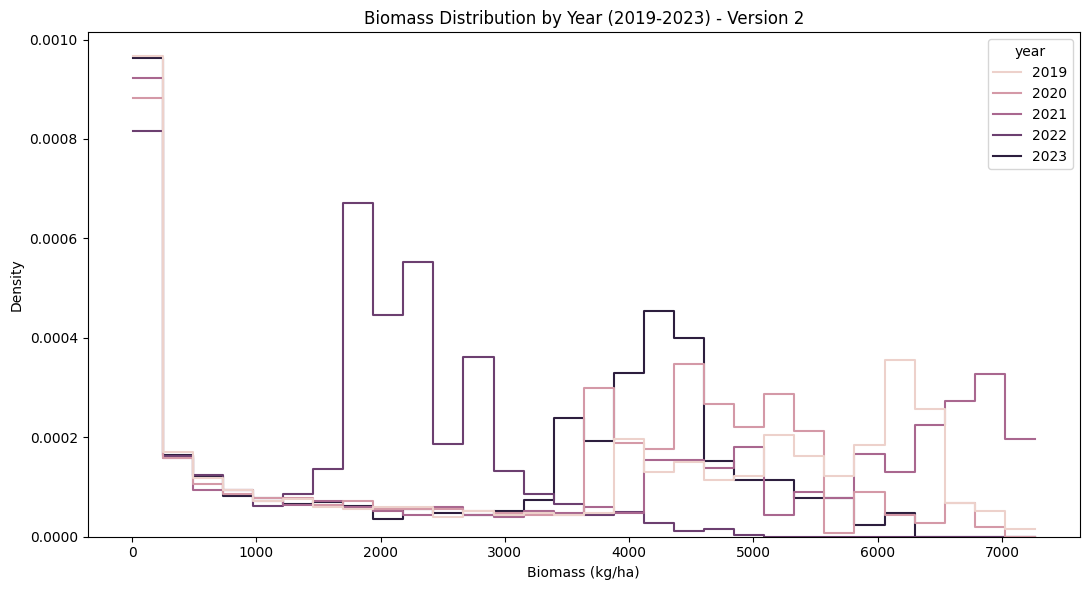

In [111]:
# =====================================================
# MEETING 8 - ADDITIONAL ANALYSIS - STEP 1
# Comparing Biomass Distributions Across Years
# Focus: Understanding the 2022 Prediction Problem
# Dataset: Version 2
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

target = 'dssat_biomass_kg_ha'

# 1. Compare descriptive statistics by year

year_distribution = (
    df_clean.groupby('year')[target]
    .agg(
        Count='count',
        Mean='mean',
        Median='median',
        Std='std',
        Min='min',
        Max='max',
        Skewness='skew'
    )
)

print("BIOMASS DISTRIBUTION BY YEAR")
print("--------------------------------")
print(year_distribution.round(2).to_string())


# 2. Compare low and high biomass frequencies

range_summary = (
    df_clean.groupby('year')[target]
    .agg(
        Below_500=lambda x: (x <= 500).sum(),
        Between_2000_4000=lambda x: (
            (x > 2000) & (x <= 4000)
        ).sum(),
        Above_4000=lambda x: (x > 4000).sum()
    )
)

print("\nBIOMASS RANGE DISTRIBUTION BY YEAR")
print("--------------------------------")
print(range_summary.to_string())


# 3. Visual comparison of all five years

plt.figure(figsize=(11, 6))

sns.histplot(
    data=df_clean,
    x=target,
    hue='year',
    bins=30,
    stat='density',
    common_norm=False,
    element='step',
    fill=False
)

plt.xlabel('Biomass (kg/ha)')
plt.ylabel('Density')
plt.title('Biomass Distribution by Year (2019-2023) - Version 2')

plt.tight_layout()
plt.show()

MEAN BIOMASS BY GROWTH STAGE AND YEAR
--------------------------------------
year                 2019     2020     2021     2022     2023
dssat_stage_code                                             
0                  141.26   177.65   153.30   165.31   141.72
1                  857.50  1146.02   995.25   944.67   835.17
3                 1343.78  1742.88  1600.55  1441.30  1324.38
5                 4025.87  3952.35  4558.91  1980.24  3636.56
7                 5772.72  5076.47  6348.75  2150.59  4578.56
8                 5333.55  4755.91  5911.21  2775.00  4164.66

R8 HARVEST MATURITY - BIOMASS BY YEAR
--------------------------------------
      Count     Mean  Median     Std   Min   Max
year                                            
2019    266  5333.55  5340.0  795.98  3937  6540
2020    274  4755.91  4787.5  744.38  3649  6493
2021    250  5911.21  6158.0  961.18  4159  7178
2022    328  2775.00  2628.5  655.65  1872  4853
2023    294  4164.66  4129.0  532.55  3371  5537


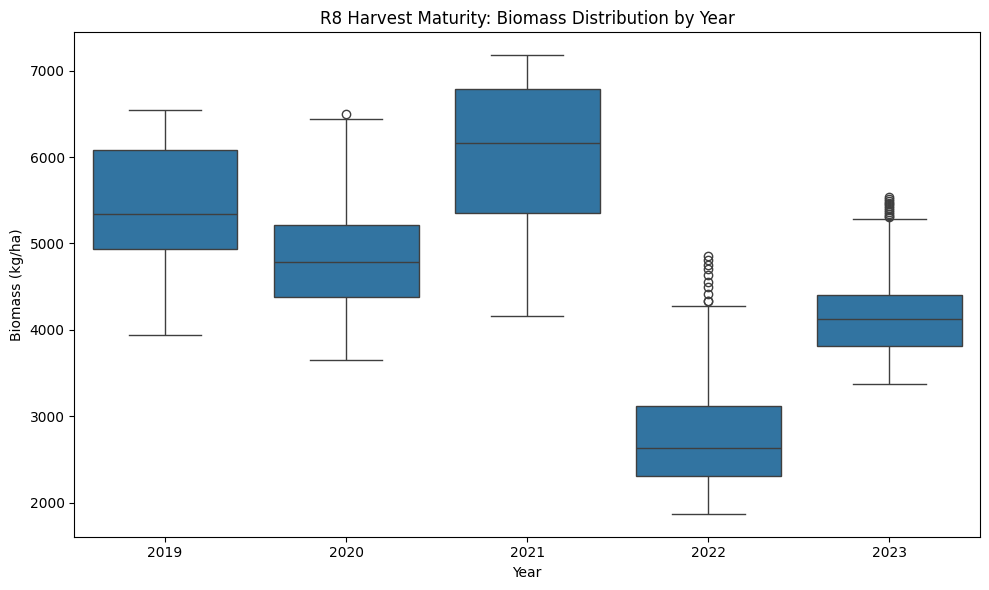

In [112]:
# =====================================================
# MEETING 8 - ADDITIONAL ANALYSIS - STEP 2
# Compare Biomass by Growth Stage Across Years
# Focus: Is R8 Biomass Different in 2022?
# Version 2 Dataset
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target = 'dssat_biomass_kg_ha'

# 1. Mean biomass at each growth stage by year

stage_year_comparison = (
    df_clean
    .groupby(['dssat_stage_code', 'year'])[target]
    .mean()
    .unstack('year')
    .sort_index()
)

print("MEAN BIOMASS BY GROWTH STAGE AND YEAR")
print("--------------------------------------")
print(stage_year_comparison.round(2).to_string())


# 2. Focus specifically on R8 harvest maturity

r8_data = df_clean[
    df_clean['dssat_stage_code'] == 8
].copy()

r8_summary = (
    r8_data.groupby('year')[target]
    .agg(
        Count='count',
        Mean='mean',
        Median='median',
        Std='std',
        Min='min',
        Max='max'
    )
)

print("\nR8 HARVEST MATURITY - BIOMASS BY YEAR")
print("--------------------------------------")
print(r8_summary.round(2).to_string())


# 3. Visual comparison of R8 biomass distributions

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=r8_data,
    x='year',
    y=target
)

plt.xlabel('Year')
plt.ylabel('Biomass (kg/ha)')
plt.title('R8 Harvest Maturity: Biomass Distribution by Year')

plt.tight_layout()
plt.show()

In [113]:
# =====================================================
# MEETING 8 - ADDITIONAL ANALYSIS - STEP 3
# Distribution Normality and Positive Biomass Prediction
# No Neural Networks
# =====================================================

import numpy as np
import pandas as pd

from scipy.stats import normaltest
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

target = 'dssat_biomass_kg_ha'
features = s2_bands + ['dap']

# -----------------------------------------------------
# PART 1: Test biomass normality across all years
# -----------------------------------------------------

print("BIOMASS NORMALITY TEST BY YEAR")
print("--------------------------------")

normality_results = []

for year, data in df_clean.groupby('year'):

    values = data[target].dropna()

    statistic, p_value = normaltest(values)

    normality_results.append({
        'Year': year,
        'Count': len(values),
        'Skewness': values.skew(),
        'Normality p-value': p_value,
        'Reject Normality (p<0.05)': p_value < 0.05
    })

normality_table = pd.DataFrame(normality_results)

print(normality_table.to_string(
    index=False,
    float_format=lambda x: f"{x:.5g}"
))

# -----------------------------------------------------
# PART 2: Compare models on unseen 2022 and 2023
# -----------------------------------------------------

assert df_clean[target].min() > 0, (
    "Log and Gamma models require positive target values."
)

all_results = []

for test_year in [2022, 2023]:

    train = df_clean[df_clean['year'] < test_year]
    test = df_clean[df_clean['year'] == test_year]

    X_train = train[features]
    X_test = test[features]
    y_train = train[target]
    y_test = test[target].to_numpy()

    # Model 1: Original Linear Regression
    baseline = LinearRegression()
    baseline.fit(X_train, y_train)

    raw_predictions = baseline.predict(X_test)
    negative_count = int((raw_predictions < 0).sum())

    clipped_predictions = np.maximum(raw_predictions, 0)

    # Model 2: Log-transformed target + Linear Regression
    # np.exp ensures predictions are strictly positive

    log_model = TransformedTargetRegressor(
        regressor=LinearRegression(),
        func=np.log,
        inverse_func=np.exp
    )

    log_model.fit(X_train, y_train)
    log_predictions = log_model.predict(X_test)

    # Model 3: Gamma Gradient Boosting
    # Nonlinear, positive predictions, NOT a neural network

    gamma_model = HistGradientBoostingRegressor(
        loss='gamma',
        max_iter=150,
        learning_rate=0.05,
        random_state=42
    )

    gamma_model.fit(X_train, y_train)
    gamma_predictions = gamma_model.predict(X_test)

    models = {
        'Linear Regression (Clipped)': clipped_predictions,
        'Log-Transformed Regression': log_predictions,
        'Gamma Gradient Boosting': gamma_predictions
    }

    for name, predictions in models.items():

        residuals = predictions - y_test

        all_results.append({
            'Year': test_year,
            'Model': name,
            'RMSE': np.sqrt(np.mean(residuals ** 2)),
            'R-squared': r2_score(y_test, predictions),
            'Mean Residual': residuals.mean(),
            'Negative Predictions': (
                negative_count
                if name == 'Linear Regression (Clipped)'
                else int((predictions < 0).sum())
            )
        })

# -----------------------------------------------------
# PART 3: Display results
# -----------------------------------------------------

final_model_comparison = pd.DataFrame(all_results)

print("\nPOSITIVE BIOMASS MODEL COMPARISON")
print("--------------------------------")
print(
    final_model_comparison
    .round(3)
    .to_string(index=False)
)

print("\nNOTE: Linear Regression negative counts are")
print("measured BEFORE clipping.")
print("No neural networks were used.")

BIOMASS NORMALITY TEST BY YEAR
--------------------------------
 Year  Count  Skewness  Normality p-value  Reject Normality (p<0.05)
 2019   1048  -0.11488                  0                       True
 2020   1049  -0.22021                  0                       True
 2021   1048  -0.13796                  0                       True
 2022   1064 -0.077506          7.764e-11                       True
 2023   1056  -0.23155                  0                       True

POSITIVE BIOMASS MODEL COMPARISON
--------------------------------
 Year                       Model     RMSE  R-squared  Mean Residual  Negative Predictions
 2022 Linear Regression (Clipped) 1099.498      0.022        643.593                   184
 2022  Log-Transformed Regression 1546.378     -0.935        341.820                     0
 2022     Gamma Gradient Boosting 1330.166     -0.432        861.163                     0
 2023 Linear Regression (Clipped)  694.235      0.877        332.972                   153

In [114]:
# =====================================================
# MEETING 8 - ADDITIONAL ANALYSIS - STEP 4
# Neural Network vs Linear Regression
# Dataset: Version 2
# =====================================================

import numpy as np
import pandas as pd

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

target = 'dssat_biomass_kg_ha'
features = s2_bands + ['dap']

results = []

for test_year in [2022, 2023]:

    # Same year-based validation
    train = df_clean[df_clean['year'] < test_year]
    test = df_clean[df_clean['year'] == test_year]

    X_train = train[features]
    X_test = test[features]

    y_train = train[target]
    y_test = test[target].to_numpy()

    # -----------------------------------
    # Model 1: Linear Regression Baseline
    # -----------------------------------

    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)

    lr_predictions = np.maximum(
        lr_model.predict(X_test), 0
    )

    # -----------------------------------
    # Model 2: Neural Network (MLP)
    # -----------------------------------

    # Scale input features and target
    nn_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('neural_network', MLPRegressor(
            hidden_layer_sizes=(32, 16),
            activation='relu',
            solver='adam',
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=600,
            early_stopping=True,
            n_iter_no_change=20,
            random_state=42
        ))
    ])

    nn_model = TransformedTargetRegressor(
        regressor=nn_pipeline,
        transformer=StandardScaler()
    )

    nn_model.fit(X_train, y_train)

    nn_raw_predictions = nn_model.predict(X_test)

    # Check negative predictions
    nn_negative_count = (nn_raw_predictions < 0).sum()

    # Apply same clipping rule
    nn_predictions = np.maximum(nn_raw_predictions, 0)

    # -----------------------------------
    # Evaluate both models
    # -----------------------------------

    models = {
        'Linear Regression': lr_predictions,
        'Neural Network (MLP)': nn_predictions
    }

    for name, predictions in models.items():

        residuals = predictions - y_test

        rmse = np.sqrt(np.mean(residuals ** 2))

        r2 = r2_score(y_test, predictions)

        results.append({
            'Year': test_year,
            'Model': name,
            'RMSE': rmse,
            'R-squared': r2,
            'Mean Residual': residuals.mean()
        })

    print(f"\n{test_year} - Neural Network negative predictions:",
          nn_negative_count)

# -----------------------------------
# Final Comparison
# -----------------------------------

nn_comparison = pd.DataFrame(results)

print("\nNEURAL NETWORK VS LINEAR REGRESSION")
print("----------------------------------")

print(
    nn_comparison
    .round(3)
    .to_string(index=False)
)

print("\nLower RMSE = Better")
print("Higher R-squared = Better")


2022 - Neural Network negative predictions: 154

2023 - Neural Network negative predictions: 38

NEURAL NETWORK VS LINEAR REGRESSION
----------------------------------
 Year                Model     RMSE  R-squared  Mean Residual
 2022    Linear Regression 1099.498      0.022        643.593
 2022 Neural Network (MLP)  917.639      0.318        383.777
 2023    Linear Regression  694.235      0.877        332.972
 2023 Neural Network (MLP)  871.562      0.807        491.935

Lower RMSE = Better
Higher R-squared = Better


In [115]:
# Meeting 8 - Additional Analysis - Step 5
# Compare Neural Network vs Linear Regression at R8 in 2022

from sklearn.base import clone
import numpy as np
import pandas as pd

target = 'dssat_biomass_kg_ha'
features = s2_bands + ['dap']

# Recreate the same Neural Network configuration
# from Step 4 and train it on 2019-2021
nn_2022_check = clone(nn_model)

nn_2022_check.fit(
    train_2022[features],
    train_2022[target]
)

nn_pred_2022_check = np.maximum(
    nn_2022_check.predict(test_2022[features]), 0
)

actual = test_2022[target].to_numpy()
baseline = np.asarray(pred_2022_clipped)

r8_mask = test_2022['dssat_stage_code'].to_numpy() == 8

results = []

for name, predictions in {
    'Linear Regression': baseline,
    'Neural Network': nn_pred_2022_check
}.items():

    for group, mask in {
        'R8': r8_mask,
        'Non-R8': ~r8_mask
    }.items():

        residual = predictions[mask] - actual[mask]

        results.append({
            'Model': name,
            'Stage Group': group,
            'Count': mask.sum(),
            'RMSE': np.sqrt(np.mean(residual ** 2)),
            'Mean Residual': residual.mean()
        })

comparison_nn_stage = pd.DataFrame(results)

print("2022 - NEURAL NETWORK VS LINEAR REGRESSION")
print(comparison_nn_stage.round(2).to_string(index=False))

print("\nNeural Network Overall RMSE:",
      round(np.sqrt(np.mean(
          (nn_pred_2022_check - actual) ** 2
      )), 3))

2022 - NEURAL NETWORK VS LINEAR REGRESSION
            Model Stage Group  Count    RMSE  Mean Residual
Linear Regression          R8    328 1872.45        1661.47
Linear Regression      Non-R8    736  430.30         189.98
   Neural Network          R8    328 1568.87        1402.12
   Neural Network      Non-R8    736  347.02         -70.05

Neural Network Overall RMSE: 917.639


In [116]:
# Meeting 8 - Additional Analysis - Step 6
# Neural Network vs Linear Regression: 2023 R8 and Non-R8

import numpy as np
import pandas as pd

target = 'dssat_biomass_kg_ha'
features_nn = s2_bands + ['dap']

# nn_model is the 2023-trained model from Step 4
actual = test_2023[target].to_numpy()

nn_predictions = np.maximum(
    nn_model.predict(test_2023[features_nn]), 0
)

baseline_predictions = np.asarray(pred_base_2023)

r8_mask = test_2023['dssat_stage_code'].to_numpy() == 8

results = []

for name, predictions in {
    'Linear Regression': baseline_predictions,
    'Neural Network': nn_predictions
}.items():

    for group, mask in {
        'R8': r8_mask,
        'Non-R8': ~r8_mask
    }.items():

        residual = predictions[mask] - actual[mask]

        results.append({
            'Model': name,
            'Stage Group': group,
            'Count': mask.sum(),
            'RMSE': np.sqrt(np.mean(residual ** 2)),
            'Mean Residual': residual.mean()
        })

comparison_nn_2023 = pd.DataFrame(results)

print("2023 - NEURAL NETWORK VS LINEAR REGRESSION")
print(comparison_nn_2023.round(2).to_string(index=False))

print("\nNeural Network Overall RMSE:",
      round(np.sqrt(np.mean(
          (nn_predictions - actual) ** 2
      )), 3))

2023 - NEURAL NETWORK VS LINEAR REGRESSION
            Model Stage Group  Count    RMSE  Mean Residual
Linear Regression          R8    294  888.84         712.10
Linear Regression      Non-R8    762  602.57         186.69
   Neural Network          R8    294 1221.79        1027.90
   Neural Network      Non-R8    762  690.47         285.14

Neural Network Overall RMSE: 871.562


In [117]:
# Meeting 9 - Step 1
# Verify the data and reproduce the known 2023 baseline
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score

TARGET = 'dssat_biomass_kg_ha'
print("MEETING 9 - STEP 1: DATA VERIFICATION")

print("\n2023 test set shape:", test_2023.shape)
print("Treatment columns:", [c for c in test_2023.columns
                             if 'trt' in c.lower() or 'treat' in c.lower()])
print("Treatment values:", sorted(test_2023['treatment'].unique()))
print("Years in test set:", test_2023['year'].unique())

# Put predictions in a Series aligned to test_2023
if isinstance(pred_base_2023, pd.Series):
    pred = pred_base_2023
    index_ok = pred.index.equals(test_2023.index)
else:
    pred = pd.Series(np.asarray(pred_base_2023).ravel(), index=test_2023.index)
    index_ok = None  # plain array: only the length can be checked

print("\nCounts: predictions =", len(pred), "| actual =", len(test_2023))
print("Length match:", len(pred) == len(test_2023))
print("Index match:", index_ok if index_ok is not None else "N/A (array input)")
print("NaNs in predictions:", int(pred.isna().sum()))
print("NaNs in target:", int(test_2023[TARGET].isna().sum()))
print("Minimum prediction (should be >= 0):", round(float(pred.min()), 3))

# Reproduce the recorded 2023 baseline
rmse = np.sqrt(mean_squared_error(test_2023[TARGET], pred))
r2 = r2_score(test_2023[TARGET], pred)
mean_resid = (pred - test_2023[TARGET]).mean()
print(f"\nRMSE          = {rmse:.3f}   (expected 694.235)")
print(f"R2            = {r2:.3f}   (expected 0.877)")
print(f"Mean residual = {mean_resid:+.3f}   (expected +332.972)")
print("BASELINE REPRODUCED" if abs(rmse - 694.235) < 0.01
      else "MISMATCH - CHECK BEFORE CONTINUING")

MEETING 9 - STEP 1: DATA VERIFICATION

2023 test set shape: (1056, 37)
Treatment columns: ['treatment']
Treatment values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Years in test set: [2023]

Counts: predictions = 1056 | actual = 1056
Length match: True
Index match: N/A (array input)
NaNs in predictions: 0
NaNs in target: 0
Minimum prediction (should be >= 0): 0.0

RMSE          = 694.235   (expected 694.235)
R2            = 0.877   (expected 0.877)
Mean residual = +332.972   (expected +332.972)
BASELINE REPRODUCED


In [118]:
# Meeting 9 - Step 2
# Baseline performance by treatment, 2023
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

target = 'dssat_biomass_kg_ha'

# Build one evaluation table with every column needed later
eval_2023 = test_2023[['treatment', 'dap', 'dssat_stage_code', target]].reset_index(drop=True).copy()
pred = np.asarray(pred_base_2023).reshape(-1)
assert len(pred) == len(eval_2023), "prediction length mismatch"

eval_2023['Predicted'] = pred
eval_2023['Residual'] = eval_2023['Predicted'] - eval_2023[target]   # predicted minus actual
eval_2023['trt_num'] = eval_2023['treatment'].astype(str).str.extract(r'(\d+)$')[0].astype(int)
eval_2023['Group'] = np.select(
    [eval_2023['trt_num'] == 5, eval_2023['trt_num'] == 7],
    ['T5', 'T7'],
    default='Other 6'
)

total_sse = (eval_2023['Residual'] ** 2).sum()

def summarize(g):
    r = g['Residual'].to_numpy()
    return pd.Series({
        'Count': len(g),
        'RMSE': np.sqrt((r ** 2).mean()),
        'R2': r2_score(g[target], g['Predicted']),
        'Mean Residual': r.mean(),
        '% Overpredicted': 100 * (r > 0).mean(),
        '% of Total Sq. Error': 100 * (r ** 2).sum() / total_sse
    })

def by(col):
    return pd.DataFrame({k: summarize(g) for k, g in eval_2023.groupby(col)}).T.round(3)

overall_rmse = np.sqrt((eval_2023['Residual'] ** 2).mean())
print(f"Overall RMSE {overall_rmse:.3f} (expected 694.235)")
assert abs(overall_rmse - 694.235) < 0.01, "Baseline not reproduced"

print("\nBY TREATMENT:\n", by('trt_num'))
print("\nT5 vs T7 vs OTHER 6:\n", by('Group'))

Overall RMSE 694.235 (expected 694.235)

BY TREATMENT:
    Count     RMSE     R2  Mean Residual  % Overpredicted  % of Total Sq. Error
1  132.0  690.458  0.878        601.292           93.182                12.364
2  132.0  460.553  0.927         57.738           58.333                 5.501
3  132.0  751.725  0.829        516.193           71.970                14.656
4  132.0  538.824  0.908        186.792           54.545                 7.530
5  132.0  995.105  0.731        827.788           93.182                25.682
6  132.0  504.422  0.910        297.698           75.000                 6.599
7  132.0  644.673  0.926       -242.272           18.939                10.779
8  132.0  806.942  0.849        418.543           56.818                16.888

T5 vs T7 vs OTHER 6:
          Count     RMSE     R2  Mean Residual  % Overpredicted  \
Other 6  792.0  638.991  0.885        346.376           68.308   
T5       132.0  995.105  0.731        827.788           93.182   
T7       132

In [119]:
# Meeting 9 - Step 3
# Treatments 5 and 7 vs the other six, by growth stage, 2023
# Requires eval_2023 from Step 2
import numpy as np
import pandas as pd

target = 'dssat_biomass_kg_ha'
stage_names = {0: 'Veg', 1: 'R1', 3: 'R3', 5: 'R5', 7: 'R7', 8: 'R8'}  # confirm against dssat_stage_name

rows = []
for (group_name, stage), g in eval_2023.groupby(['Group', 'dssat_stage_code']):
    r = g['Residual'].to_numpy()
    rows.append({
        'Group': group_name,
        'Stage': stage_names.get(stage, stage),
        'Count': len(g),
        'Mean DAP': g['dap'].mean(),
        'Actual Mean': g[target].mean(),
        'Predicted Mean': g['Predicted'].mean(),
        'Mean Residual': r.mean(),
        'RMSE': np.sqrt((r ** 2).mean()),
        'Small n (<10)': 'yes' if len(g) < 10 else ''
    })

tbl = pd.DataFrame(rows).round(1)
order = list(stage_names.values())
tbl['Stage'] = pd.Categorical(tbl['Stage'], categories=order, ordered=True)
tbl = tbl.sort_values(['Stage', 'Group'])

print("BY GROWTH STAGE (2023):")
print(tbl.to_string(index=False))

print("\nMEAN RESIDUAL by stage (rows) and group (columns):")
print(tbl.pivot(index='Stage', columns='Group', values='Mean Residual').to_string())

BY GROWTH STAGE (2023):
  Group Stage  Count  Mean DAP  Actual Mean  Predicted Mean  Mean Residual   RMSE Small n (<10)
Other 6   Veg    216      23.5        141.7           230.2           88.4  316.5              
     T5   Veg     36      23.5         48.1           376.1          328.0  407.9              
     T7   Veg     36      23.5        235.2            66.6         -168.6  255.9              
Other 6    R1     36      44.5        835.6          1386.4          550.8  661.5              
     T5    R1      6      44.5        300.8           664.3          363.4  378.8           yes
     T7    R1      6      44.5       1367.0          1945.0          578.0  622.7           yes
Other 6    R3     30      50.0       1325.9          2032.6          706.7 1034.3              
     T5    R3      5      50.0        564.0           612.0           48.0   63.9           yes
     T7    R3      5      50.0       2075.6          3190.8         1115.2 1116.0           yes
Other 6    R5   

In [120]:

# Meeting 9 - Step 4
# Normal-Weather Model: Exclude 2022 From Training
# Compare Against Existing 2023 Linear Regression Baseline

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

target = 'dssat_biomass_kg_ha'
features = s2_bands + ['dap']

# Existing training data contains years 2019-2022
# Remove drought-affected 2022 from training
normal_train = train_2023[
    train_2023['year'].isin([2019, 2020, 2021])
].copy()

# Keep the same 2023 test dataset
normal_test = test_2023.copy()

print("NORMAL-WEATHER MODEL")
print("Training years:", sorted(normal_train['year'].unique()))
print("Training rows:", len(normal_train))
print("Testing years:", sorted(normal_test['year'].unique()))
print("Testing rows:", len(normal_test))

# Fit new Linear Regression model
normal_model = LinearRegression()

normal_model.fit(
    normal_train[features],
    normal_train[target]
)

# Predict 2023 biomass and clip negative predictions
pred_normal_2023 = np.maximum(
    normal_model.predict(normal_test[features]), 0
)

# Existing baseline predictions
pred_existing_2023 = np.asarray(pred_base_2023).reshape(-1)

actual = normal_test[target].to_numpy()

# Compare the two models on identical test observations
results = []

for name, predictions in {
    'Existing LR (2019-2022 Training)': pred_existing_2023,
    'Normal LR (2019-2021 Training)': pred_normal_2023
}.items():

    residual = predictions - actual

    results.append({
        'Model': name,
        'RMSE': np.sqrt(np.mean(residual ** 2)),
        'R-squared': r2_score(actual, predictions),
        'Mean Residual': residual.mean()
    })

normal_weather_comparison = pd.DataFrame(results)

print("\n2023 - MODEL COMPARISON")
print(normal_weather_comparison.round(3).to_string(index=False))

# Compare Treatments 5 and 7 separately
print("\nTREATMENTS 5 AND 7 - MODEL COMPARISON")

for treatment in [5, 7]:

    mask = normal_test['treatment'].astype(str) == str(treatment)

    actual_group = actual[mask]

    print(f"\nTreatment {treatment}")

    for name, predictions in {
        'Existing LR': pred_existing_2023,
        'Normal LR': pred_normal_2023
    }.items():

        residual = predictions[mask] - actual_group

        print(
            name,
            "| RMSE:", round(np.sqrt(np.mean(residual ** 2)), 3),
            "| R2:", round(r2_score(actual_group, predictions[mask]), 3),
            "| Mean Residual:", round(residual.mean(), 3)
        )


NORMAL-WEATHER MODEL
Training years: [np.int64(2019), np.int64(2020), np.int64(2021)]
Training rows: 3145
Testing years: [np.int64(2023)]
Testing rows: 1056

2023 - MODEL COMPARISON
                           Model    RMSE  R-squared  Mean Residual
Existing LR (2019-2022 Training) 694.235      0.877        332.972
  Normal LR (2019-2021 Training) 818.875      0.829        467.555

TREATMENTS 5 AND 7 - MODEL COMPARISON

Treatment 5
Existing LR | RMSE: 995.105 | R2: 0.731 | Mean Residual: 827.788
Normal LR | RMSE: 1196.523 | R2: 0.611 | Mean Residual: 981.675

Treatment 7
Existing LR | RMSE: 644.673 | R2: 0.926 | Mean Residual: -242.272
Normal LR | RMSE: 609.817 | R2: 0.933 | Mean Residual: -124.41


In [121]:
# Meeting 9 - Step 4B
# Treatment performance across several held-out normal years
# Two setups: 2022 excluded from training, and 2022 kept in training
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

target = 'dssat_biomass_kg_ha'
features = s2_bands + ['dap']

# Build the all-years table if Step 8 has not been run
if 'all_years' not in globals():
    all_years = pd.concat([train_2023, test_2023], ignore_index=True)

d = all_years.copy()
d['trt_num'] = d['treatment'].astype(str).str.extract(r'(\d+)$')[0].astype(int)

def run(train_pool, label):
    out = []
    for test_year in [2019, 2020, 2021, 2023]:      # 2022 is never a test year
        tr = d[d['year'].isin(train_pool) & (d['year'] != test_year)]
        te = d[d['year'] == test_year].copy()
        model = LinearRegression().fit(tr[features], tr[target])
        te['res'] = np.maximum(model.predict(te[features]), 0) - te[target]
        te['setup'] = label
        te['test_year'] = test_year
        out.append(te)
    return pd.concat(out)

res = pd.concat([
    run([2019, 2020, 2021, 2023], 'A: 2022 excluded from training'),
    run([2019, 2020, 2021, 2022, 2023], 'B: 2022 kept in training')
])
res['group'] = np.select([res.trt_num == 5, res.trt_num == 7], ['T5', 'T7'], 'Other 6')

rmse = lambda r: np.sqrt((r ** 2).mean())

print("RMSE by setup, test year and group:")
print(res.groupby(['setup', 'test_year', 'group'])['res'].apply(rmse).unstack().round(1).to_string())

print("\nMean residual (predicted minus actual):")
print(res.groupby(['setup', 'test_year', 'group'])['res'].mean().unstack().round(1).to_string())

# Setup B on 2023 trains on 2019-2022, so it should match the baseline
chk = res[(res.setup.str.startswith('B')) & (res.test_year == 2023)]['res']
print("\nSetup B / 2023 overall RMSE:", round(rmse(chk), 3), "(expected 694.235)")

RMSE by setup, test year and group:
group                                     Other 6      T5      T7
setup                          test_year                         
A: 2022 excluded from training 2019         799.4   942.6  1100.0
                               2020         596.4   588.4   785.0
                               2021         845.0   965.4  1040.4
                               2023         770.4  1196.5   609.8
B: 2022 kept in training       2019         844.1  1074.4  1265.5
                               2020         557.2   609.6   749.9
                               2021         967.6  1194.5  1124.6
                               2023         639.0   995.1   644.7

Mean residual (predicted minus actual):
group                                     Other 6     T5     T7
setup                          test_year                       
A: 2022 excluded from training 2019         -85.9 -329.1 -518.1
                               2020         135.2  173.7  207.2
       

In [122]:

# Meeting 9 - Step 5
# Existing LR vs Normal-Weather LR
# Treatments 5 and 7 by Growth Stage - 2023

import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

comparison_data = test_2023[
    ['treatment', 'dssat_stage_code', 'dssat_biomass_kg_ha']
].reset_index(drop=True).copy()

comparison_data['Existing LR'] = np.asarray(
    pred_existing_2023
).reshape(-1)

comparison_data['Normal-Weather LR'] = np.asarray(
    pred_normal_2023
).reshape(-1)

comparison_data = comparison_data[
    comparison_data['treatment'].astype(str).isin(['5', '7'])
].copy()

results = []

for (treatment, stage), group in comparison_data.groupby(
    ['treatment', 'dssat_stage_code']
):

    actual = group['dssat_biomass_kg_ha'].to_numpy()

    for model_name in ['Existing LR', 'Normal-Weather LR']:

        predictions = group[model_name].to_numpy()
        residual = predictions - actual

        results.append({
            'Treatment': treatment,
            'Stage': stage,
            'Model': model_name,
            'Count': len(group),
            'RMSE': np.sqrt(np.mean(residual ** 2)),
            'Mean Residual': residual.mean()
        })

stage_model_comparison = pd.DataFrame(results)

print("MEETING 9 - STEP 5")
print("TREATMENTS 5 AND 7: MODEL COMPARISON BY STAGE")

print(
    stage_model_comparison
    .round(2)
    .to_string(index=False)
)


MEETING 9 - STEP 5
TREATMENTS 5 AND 7: MODEL COMPARISON BY STAGE
 Treatment  Stage             Model  Count    RMSE  Mean Residual
         5      0       Existing LR     36  407.87         327.98
         5      0 Normal-Weather LR     36  451.89         353.83
         5      1       Existing LR      6  378.82         363.42
         5      1 Normal-Weather LR      6  464.20         452.70
         5      3       Existing LR      5   63.95          47.98
         5      3 Normal-Weather LR      5  147.93         141.52
         5      5       Existing LR     34  759.68         705.81
         5      5 Normal-Weather LR     34  839.91         795.74
         5      7       Existing LR     15  949.28         941.21
         5      7 Normal-Weather LR     15 1100.73        1092.08
         5      8       Existing LR     36 1587.29        1581.24
         5      8 Normal-Weather LR     36 1958.37        1943.97
         7      0       Existing LR     36  255.86        -168.63
         7 

In [123]:
# Meeting 9 - Step 6
# Share of squared error by growth stage for Treatments 5 and 7
# Requires eval_2023 from Step 2
import numpy as np
import pandas as pd

e = eval_2023.copy()
e['Sq'] = e['Residual'] ** 2
focus = e[e['trt_num'].isin([5, 7])]

t = (focus.groupby(['trt_num', 'dssat_stage_code'])
          .agg(Count=('Sq', 'size'), SSE=('Sq', 'sum'), MeanRes=('Residual', 'mean'))
          .reset_index())
t['Row share %']   = 100 * t['Count'] / t.groupby('trt_num')['Count'].transform('sum')
t['Error share %'] = 100 * t['SSE']   / t.groupby('trt_num')['SSE'].transform('sum')

print("MEETING 9 - STEP 6")
print("ERROR CONTRIBUTION BY GROWTH STAGE")
print(t.drop(columns='SSE').round(1).to_string(index=False))

print("\nSHARE OF TOTAL 2023 SQUARED ERROR BY TREATMENT")
share = (e.groupby('trt_num')['Sq'].sum() / e['Sq'].sum() * 100).round(2)
print(share.to_string())

MEETING 9 - STEP 6
ERROR CONTRIBUTION BY GROWTH STAGE
 trt_num  dssat_stage_code  Count  MeanRes  Row share %  Error share %
       5                 0     36    328.0         27.3            4.6
       5                 1      6    363.4          4.5            0.7
       5                 3      5     48.0          3.8            0.0
       5                 5     34    705.8         25.8           15.0
       5                 7     15    941.2         11.4           10.3
       5                 8     36   1581.2         27.3           69.4
       7                 0     36   -168.6         27.3            4.3
       7                 1      6    578.0          4.5            4.2
       7                 3      5   1115.2          3.8           11.4
       7                 5     33   -637.4         25.0           65.9
       7                 7     15   -631.8         11.4           12.6
       7                 8     37   -120.1         28.0            1.6

SHARE OF TOTAL 2023 SQ

In [124]:

# Meeting 9 - Step 7
# Separate Linear Regression Models for Treatments 5 and 7
# Train: 2019-2022 | Test: 2023

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

target = 'dssat_biomass_kg_ha'
features = s2_bands + ['dap']

results = []
stage_results = []

for treatment in [5, 7]:

    # Training data for this treatment only
    train_t = train_2023[
        train_2023['treatment'].astype(str) == str(treatment)
    ].copy()

    # Test data for this treatment only
    mask = (
        test_2023['treatment'].astype(str) == str(treatment)
    ).to_numpy()

    test_t = test_2023.loc[mask].copy()

    # Train treatment-specific Linear Regression
    model_t = LinearRegression()
    model_t.fit(train_t[features], train_t[target])

    specific_pred = np.maximum(
        model_t.predict(test_t[features]), 0
    )

    # Existing pooled Linear Regression predictions
    baseline_pred = np.asarray(pred_base_2023)[mask]

    actual = test_t[target].to_numpy()

    print(f"\nTREATMENT {treatment}")
    print("Training rows:", len(train_t))
    print("Testing rows:", len(test_t))

    for name, pred in {
        'Existing Pooled LR': baseline_pred,
        'Treatment-Specific LR': specific_pred
    }.items():

        residual = pred - actual

        results.append({
            'Treatment': treatment,
            'Model': name,
            'RMSE': np.sqrt(np.mean(residual ** 2)),
            'R-squared': r2_score(actual, pred),
            'Mean Residual': residual.mean()
        })

        # Stage-level performance
        for stage in sorted(test_t['dssat_stage_code'].unique()):

            stage_mask = (
                test_t['dssat_stage_code'].to_numpy() == stage
            )

            stage_residual = residual[stage_mask]

            stage_results.append({
                'Treatment': treatment,
                'Stage': stage,
                'Model': name,
                'Count': stage_mask.sum(),
                'RMSE': np.sqrt(np.mean(stage_residual ** 2)),
                'Mean Residual': stage_residual.mean()
            })

comparison_step7 = pd.DataFrame(results)
stage_comparison_step7 = pd.DataFrame(stage_results)

print("\nMEETING 9 - STEP 7")
print("OVERALL TREATMENT-SPECIFIC MODEL COMPARISON")
print(comparison_step7.round(3).to_string(index=False))

print("\nIMPORTANT GROWTH STAGES: T5-R8 AND T7-R5")

priority_stages = stage_comparison_step7[
    (
        (stage_comparison_step7['Treatment'] == 5) &
        (stage_comparison_step7['Stage'] == 8)
    ) |
    (
        (stage_comparison_step7['Treatment'] == 7) &
        (stage_comparison_step7['Stage'] == 5)
    )
]

print(priority_stages.round(3).to_string(index=False))



TREATMENT 5
Training rows: 526
Testing rows: 132

TREATMENT 7
Training rows: 527
Testing rows: 132

MEETING 9 - STEP 7
OVERALL TREATMENT-SPECIFIC MODEL COMPARISON
 Treatment                 Model     RMSE  R-squared  Mean Residual
         5    Existing Pooled LR  995.105      0.731        827.788
         5 Treatment-Specific LR 1378.380      0.484       1021.727
         7    Existing Pooled LR  644.673      0.926       -242.272
         7 Treatment-Specific LR 2165.032      0.161      -1781.927

IMPORTANT GROWTH STAGES: T5-R8 AND T7-R5
 Treatment  Stage                 Model  Count     RMSE  Mean Residual
         5      8    Existing Pooled LR     36 1587.290       1581.239
         5      8 Treatment-Specific LR     36 2263.080       2259.145
         7      5    Existing Pooled LR     33 1046.696       -637.357
         7      5 Treatment-Specific LR     33 3077.976      -3036.405


In [125]:

# Meeting 9 - Step 8
# Biomass Distribution by Year - Treatments 5 and 7

import pandas as pd
import numpy as np

target = 'dssat_biomass_kg_ha'

# Combine historical training and 2023 testing data
all_years = pd.concat(
    [train_2023, test_2023],
    ignore_index=True
)

# Focus on Treatments 5 and 7
focus_years = all_years[
    all_years['treatment'].astype(str).isin(['5', '7'])
].copy()

# Summarize biomass distribution
distribution_results = (
    focus_years
    .groupby(['treatment', 'year'])[target]
    .agg(
        Count='count',
        Mean='mean',
        Median='median',
        Std='std',
        Min='min',
        Max='max'
    )
    .reset_index()
)

print("MEETING 9 - STEP 8")
print("BIOMASS DISTRIBUTION BY YEAR - TREATMENTS 5 AND 7")

print(
    distribution_results
    .round(2)
    .to_string(index=False)
)

# Compare 2022 and 2023 against the earlier years
print("\nANNUAL MEAN BIOMASS COMPARISON")

mean_table = distribution_results.pivot(
    index='year',
    columns='treatment',
    values='Mean'
)

print(mean_table.round(2).to_string())


MEETING 9 - STEP 8
BIOMASS DISTRIBUTION BY YEAR - TREATMENTS 5 AND 7
 treatment  year  Count    Mean  Median     Std  Min  Max
         5  2019    131 3084.40  2889.0 2663.49    5 6357
         5  2020    131 2980.32  4023.0 2222.86    5 5480
         5  2021    131 3702.76  3972.0 2953.87    5 7187
         5  2022    133 1551.35  1735.0 1090.79    5 3991
         5  2023    132 2413.21  2987.0 1925.30    5 4491
         7  2019    131 4051.50  5880.0 2780.47    5 7070
         7  2020    132 3846.09  5353.5 2696.97    5 6851
         7  2021    131 4123.34  5408.0 2950.79    5 7135
         7  2022    133 2282.77  2760.0 1376.85    5 4853
         7  2023    132 3580.79  5070.0 2372.25    5 6274

ANNUAL MEAN BIOMASS COMPARISON
treatment        5        7
year                       
2019       3084.40  4051.50
2020       2980.32  3846.09
2021       3702.76  4123.34
2022       1551.35  2282.77
2023       2413.21  3580.79


In [126]:
# Meeting 9 - Step 9
# Historical biomass at Treatment 5 - R8 and Treatment 7 - R5
import numpy as np
import pandas as pd

target = 'dssat_biomass_kg_ha'

if 'all_years' not in globals():
    all_years = pd.concat([train_2023, test_2023], ignore_index=True)

h = all_years.copy()
h['Treatment_Num'] = h['treatment'].astype(str).str.extract(r'(\d+)$')[0].astype(int)

focus_mask = (
    ((h['Treatment_Num'] == 5) & (h['dssat_stage_code'] == 8)) |
    ((h['Treatment_Num'] == 7) & (h['dssat_stage_code'] == 5))
)
focus_history = h.loc[focus_mask].copy()

summary = (
    focus_history
    .groupby(['Treatment_Num', 'dssat_stage_code', 'year'])[target]
    .agg(Count='count', Mean='mean', Median='median', Std='std', Min='min', Max='max')
    .reset_index()
)

print("MEETING 9 - STEP 9")
print("HISTORICAL BIOMASS AT PROBLEM GROWTH STAGES")
print(summary.round(2).to_string(index=False))

print("\n2023 VS EARLIER YEARS")
for treatment, stage in [(5, 8), (7, 5)]:
    group = focus_history[
        (focus_history['Treatment_Num'] == treatment) &
        (focus_history['dssat_stage_code'] == stage)
    ]
    testing = group[group['year'] == 2023][target]

    print(f"\nTreatment {treatment} - Stage R{stage}")
    print("2023 count:", len(testing), "| 2023 mean:", round(testing.mean(), 2))

    for label, years in [('2019-2021', [2019, 2020, 2021]),
                         ('2019-2022', [2019, 2020, 2021, 2022])]:
        tr = group[group['year'].isin(years)][target]
        print(f"  Training {label}: count {len(tr)}, mean {tr.mean():.2f}, "
              f"2023 minus training = {testing.mean() - tr.mean():+.2f}")

MEETING 9 - STEP 9
HISTORICAL BIOMASS AT PROBLEM GROWTH STAGES
 Treatment_Num  dssat_stage_code  year  Count    Mean  Median     Std  Min  Max
             5                 8  2019     33 6065.79  6054.0  118.36 5922 6295
             5                 8  2020     34 5185.03  5181.5   98.51 5033 5345
             5                 8  2021     31 6708.94  6696.0  208.76 6414 6995
             5                 8  2022     41 2742.17  2631.0  610.94 2051 3991
             5                 8  2023     36 4235.53  4221.0   96.54 4100 4413
             7                 5  2019     36 5428.17  5806.0 1474.06 2544 7070
             7                 5  2020     34 5066.12  5353.5 1418.86 2526 6667
             7                 5  2021     37 5295.76  5563.0 1497.35 2492 7135
             7                 5  2022     32 2796.84  2796.0   66.71 2575 2885
             7                 5  2023     33 5014.42  5390.0 1232.28 2541 6274

2023 VS EARLIER YEARS

Treatment 5 - Stage R8
2023 count

In [127]:

# Meeting 9 - Step 10
# Compare Model Inputs: Training Years vs 2023
# Focus: Treatment 5-R8 and Treatment 7-R5

import numpy as np
import pandas as pd

features = ['dap'] + s2_bands

results = []

for treatment, stage in [(5, 8), (7, 5)]:

    group = all_years[
        (all_years['treatment'].astype(str) == str(treatment)) &
        (all_years['dssat_stage_code'] == stage)
    ].copy()

    training = group[group['year'].isin([2019, 2020, 2021, 2022])]
    testing = group[group['year'] == 2023]

    for feature in features:

        train_mean = training[feature].mean()
        test_mean = testing[feature].mean()
        train_std = training[feature].std()

        difference = test_mean - train_mean

        standardized_difference = (
            difference / train_std
            if pd.notna(train_std) and train_std > 0
            else np.nan
        )

        results.append({
            'Treatment': treatment,
            'Stage': stage,
            'Feature': feature,
            'Training Mean': train_mean,
            '2023 Mean': test_mean,
            'Difference': difference,
            'Standardized Shift': standardized_difference
        })

feature_shift_results = pd.DataFrame(results)

print("MEETING 9 - STEP 10")
print("MODEL INPUT DISTRIBUTION COMPARISON")

for treatment, stage in [(5, 8), (7, 5)]:

    subset = feature_shift_results[
        (feature_shift_results['Treatment'] == treatment) &
        (feature_shift_results['Stage'] == stage)
    ].copy()

    subset['Absolute Shift'] = (
        subset['Standardized Shift'].abs()
    )

    subset = subset.sort_values(
        'Absolute Shift',
        ascending=False
    )

    print(f"\nTREATMENT {treatment} - R{stage}")
    print("Top 6 Features With Largest Standardized Mean Shifts")

    print(
        subset[
            ['Feature', 'Training Mean',
             '2023 Mean', 'Standardized Shift']
        ]
        .head(6)
        .round(4)
        .to_string(index=False)
    )

    print("\nDAP Comparison")

    print(
        subset[subset['Feature'] == 'dap'][
            ['Training Mean', '2023 Mean', 'Difference']
        ]
        .round(2)
        .to_string(index=False)
    )


MEETING 9 - STEP 10
MODEL INPUT DISTRIBUTION COMPARISON

TREATMENT 5 - R8
Top 6 Features With Largest Standardized Mean Shifts
             Feature  Training Mean  2023 Mean  Standardized Shift
        S2_B12_SWIR2         0.2439     0.2080             -0.7168
           S2_B4_Red         0.1231     0.0982             -0.7129
S2_B1_CoastalAerosol         0.0874     0.0706             -0.7058
          S2_B2_Blue         0.1003     0.0838             -0.6827
         S2_B3_Green         0.1424     0.1267             -0.5553
      S2_B5_RedEdge1         0.1945     0.1754             -0.5307

DAP Comparison
 Training Mean  2023 Mean  Difference
        119.92      119.5       -0.42

TREATMENT 7 - R5
Top 6 Features With Largest Standardized Mean Shifts
             Feature  Training Mean  2023 Mean  Standardized Shift
           S2_B4_Red         0.0455     0.0361             -0.4673
        S2_B12_SWIR2         0.1307     0.1154             -0.4624
S2_B1_CoastalAerosol         0.0360     

In [128]:
# Meeting 9 - Step 10B
# Effect of each input shift on predicted biomass (coefficient x shift)
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

target = 'dssat_biomass_kg_ha'
features = s2_bands + ['dap']

if 'all_years' not in globals():
    all_years = pd.concat([train_2023, test_2023], ignore_index=True)

lr = LinearRegression().fit(train_2023[features], train_2023[target])

# Confirm this refit matches the saved baseline predictions
same = np.allclose(np.maximum(lr.predict(test_2023[features]), 0),
                   np.asarray(pred_base_2023).reshape(-1))
print("Refit reproduces pred_base_2023:", same)

coef = pd.Series(lr.coef_, index=features)

for trt, stg in [(5, 8), (7, 5)]:
    g = all_years[(all_years['treatment'].astype(str) == str(trt)) &
                  (all_years['dssat_stage_code'] == stg)]
    tr, te = g[g['year'] < 2023], g[g['year'] == 2023]

    shift = te[features].mean() - tr[features].mean()
    contrib = (coef * shift).sort_values(key=abs, ascending=False)

    print(f"\nT{trt} R{stg}: predicted shift from input changes = {contrib.sum():+.0f}"
          f" | actual biomass shift = {te[target].mean() - tr[target].mean():+.0f}")
    print("Top contributors (coefficient x input shift):")
    print(contrib.head(5).round(0).to_string())

Refit reproduces pred_base_2023: True

T5 R8: predicted shift from input changes = +852 | actual biomass shift = -778
Top contributors (coefficient x input shift):
S2_B8_NIR            2159908.0
S2_B8A_NIR_Narrow   -1626877.0
S2_B7_RedEdge3       -588984.0
S2_B9_WaterVapor       47885.0
S2_B11_SWIR1           11232.0

T7 R5: predicted shift from input changes = +146 | actual biomass shift = +316
Top contributors (coefficient x input shift):
S2_B8_NIR            2279225.0
S2_B8A_NIR_Narrow   -1758175.0
S2_B7_RedEdge3       -584590.0
S2_B9_WaterVapor       55359.0
S2_B6_RedEdge2          6123.0


In [129]:
# Meeting 9 - Step 11
# Ridge regression with alpha chosen by leave-one-year-out on 2019-2022
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

target = 'dssat_biomass_kg_ha'
features = s2_bands + ['dap']
alphas = [0.01, 0.1, 1, 10, 100, 1000]   # 0.01 behaves almost like plain Linear Regression

# Choose alpha using only 2019-2022
rows = []
for a in alphas:
    for ty in [2019, 2020, 2021, 2022]:
        tr = train_2023[train_2023['year'] != ty]
        te = train_2023[train_2023['year'] == ty]
        m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(tr[features], tr[target])
        p = np.maximum(m.predict(te[features]), 0)
        rows.append((a, ty, np.sqrt(np.mean((p - te[target]) ** 2))))

cv = (pd.DataFrame(rows, columns=['alpha', 'year', 'RMSE'])
        .pivot(index='alpha', columns='year', values='RMSE'))
cv['mean_2019_21'] = cv[[2019, 2020, 2021]].mean(axis=1)
print("Leave-one-year-out RMSE by alpha:")
print(cv.round(1).to_string())

best = cv['mean_2019_21'].idxmin()
print("Chosen alpha:", best)

# Evaluate once on 2023
m = make_pipeline(StandardScaler(), Ridge(alpha=best)).fit(train_2023[features], train_2023[target])
ridge_pred = np.maximum(m.predict(test_2023[features]), 0)

base = np.asarray(pred_base_2023).reshape(-1)
y = test_2023[target].to_numpy()
trt = test_2023['treatment'].astype(str).str.extract(r'(\d+)$')[0].to_numpy()
stg = test_2023['dssat_stage_code'].to_numpy()

masks = {
    'Overall': np.ones(len(y), dtype=bool),
    'T5': trt == '5',
    'T7': trt == '7',
    'T5-R8': (trt == '5') & (stg == 8),
    'T7-R5': (trt == '7') & (stg == 5)
}

out = pd.DataFrame({
    name: {
        'n': int(mask.sum()),
        'LR RMSE': np.sqrt(np.mean((base[mask] - y[mask]) ** 2)),
        'Ridge RMSE': np.sqrt(np.mean((ridge_pred[mask] - y[mask]) ** 2)),
        'LR mean residual': (base[mask] - y[mask]).mean(),
        'Ridge mean residual': (ridge_pred[mask] - y[mask]).mean()
    } for name, mask in masks.items()
}).T

print("\n2023 comparison:")
print(out.round(1).to_string())

Leave-one-year-out RMSE by alpha:
year       2019   2020    2021    2022  mean_2019_21
alpha                                               
0.01      939.8  611.8   975.7  1130.7         842.4
0.10      925.9  642.2  1026.4  1172.7         864.8
1.00      941.8  699.8  1102.1  1232.1         914.6
10.00     949.7  712.5  1165.9  1263.5         942.7
100.00   1019.6  713.1  1287.8  1383.0        1006.8
1000.00  1198.9  852.4  1495.2  1374.7        1182.2
Chosen alpha: 0.01

2023 comparison:
              n  LR RMSE  Ridge RMSE  LR mean residual  Ridge mean residual
Overall  1056.0    694.2       694.5             333.0                361.4
T5        132.0    995.1       973.6             827.8                810.3
T7        132.0    644.7       571.6            -242.3               -100.6
T5-R8      36.0   1587.3      1533.3            1581.2               1520.9
T7-R5      33.0   1046.7       917.7            -637.4               -282.5


In [130]:
# Meeting 9 - Step 12
# Compact band subsets, leave-one-year-out on normal test years (2022 stays in training)
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

target = 'dssat_biomass_kg_ha'

if 'all_years' not in globals():
    all_years = pd.concat([train_2023, test_2023], ignore_index=True)

d = all_years.copy()
d['trt_num'] = d['treatment'].astype(str).str.extract(r'(\d+)$')[0].astype(int)
d['group'] = np.select([d.trt_num == 5, d.trt_num == 7], ['T5', 'T7'], 'Other 6')

subsets = {
    'All 12 bands + DAP': s2_bands + ['dap'],
    'Drop B8A + DAP': [b for b in s2_bands if b != 'S2_B8A_NIR_Narrow'] + ['dap'],
    'Red, NIR, SWIR2 + DAP': ['S2_B4_Red', 'S2_B8_NIR', 'S2_B12_SWIR2', 'dap'],
    'Red, RedEdge1, NIR, SWIR1, SWIR2 + DAP': ['S2_B4_Red', 'S2_B5_RedEdge1', 'S2_B8_NIR',
                                              'S2_B11_SWIR1', 'S2_B12_SWIR2', 'dap'],
}

parts = []
for name, feats in subsets.items():
    for ty in [2019, 2020, 2021, 2023]:
        tr = d[d['year'] != ty]
        te = d[d['year'] == ty].copy()
        model = LinearRegression().fit(tr[feats], tr[target])
        te['res'] = np.maximum(model.predict(te[feats]), 0) - te[target]
        te['subset'] = name
        te['test_year'] = ty
        parts.append(te[['subset', 'test_year', 'group', 'res']])

r = pd.concat(parts)
rmse = lambda x: np.sqrt((x ** 2).mean())

print("RMSE pooled over test years 2019, 2020, 2021, 2023:")
print(r.groupby(['subset', 'group'])['res'].apply(rmse).unstack().round(1).to_string())

print("\nRMSE by test year:")
print(r.groupby(['subset', 'test_year', 'group'])['res'].apply(rmse).unstack().round(1).to_string())

print("\nMean residual (predicted minus actual) by test year:")
print(r.groupby(['subset', 'test_year', 'group'])['res'].mean().unstack().round(1).to_string())

RMSE pooled over test years 2019, 2020, 2021, 2023:
group                                   Other 6      T5      T7
subset                                                         
All 12 bands + DAP                        769.1   992.8   979.4
Drop B8A + DAP                            781.5  1005.0  1018.7
Red, NIR, SWIR2 + DAP                     891.8  1178.9  1276.6
Red, RedEdge1, NIR, SWIR1, SWIR2 + DAP    848.7  1069.3  1065.0

RMSE by test year:
group                                             Other 6      T5      T7
subset                                 test_year                         
All 12 bands + DAP                     2019         844.1  1074.4  1265.5
                                       2020         557.2   609.6   749.9
                                       2021         967.6  1194.5  1124.6
                                       2023         639.0   995.1   644.7
Drop B8A + DAP                         2019         858.7  1066.1  1373.4
                          

In [131]:
# Meeting 9 - Setup for Steps 14-16
# Leave-one-year-out predictions for normal test years (2022 stays in training)
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

target = 'dssat_biomass_kg_ha'
features = s2_bands + ['dap']

if 'all_years' not in globals():
    all_years = pd.concat([train_2023, test_2023], ignore_index=True)

d = all_years.copy()
d['trt_num'] = d['treatment'].astype(str).str.extract(r'(\d+)$')[0].astype(int)
d['group'] = np.select([d.trt_num == 5, d.trt_num == 7], ['T5', 'T7'], 'Other 6')

parts = []
for ty in [2019, 2020, 2021, 2023]:
    tr = d[d['year'] != ty]
    te = d[d['year'] == ty].copy()
    model = LinearRegression().fit(tr[features], tr[target])
    te['pred'] = np.maximum(model.predict(te[features]), 0)
    te['res'] = te['pred'] - te[target]          # predicted minus actual
    te['test_year'] = ty
    parts.append(te)

loyo = pd.concat(parts, ignore_index=True)

chk = loyo[loyo.test_year == 2023]['res']
print("2023 RMSE:", round(np.sqrt((chk ** 2).mean()), 3), "(expected 694.235)")
print("Rows:", len(loyo), "| treatment-year blocks:", loyo.groupby(['trt_num', 'test_year']).ngroups)

2023 RMSE: 694.235 (expected 694.235)
Rows: 4201 | treatment-year blocks: 32


In [132]:
# Meeting 9 - Step 14
# Bootstrap confidence range for the RMSE gap between T5/T7 and the other six
# Resampling unit: one treatment-year (about one simulated season)
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

blocks = (loyo.assign(sq=loyo['res'] ** 2)
              .groupby(['trt_num', 'test_year', 'group'])
              .agg(n=('sq', 'size'), sse=('sq', 'sum'))
              .reset_index())

def rmse_from(b_n, b_sse):
    return np.sqrt(b_sse.sum() / b_n.sum())

def boot_gap(focus_groups, n_boot=5000):
    f = blocks[blocks['group'].isin(focus_groups)]
    o = blocks[blocks['group'] == 'Other 6']
    fn, fs = f['n'].to_numpy(), f['sse'].to_numpy()
    on, os_ = o['n'].to_numpy(), o['sse'].to_numpy()

    point = rmse_from(fn, fs) - rmse_from(on, os_)
    gaps = np.empty(n_boot)
    for i in range(n_boot):
        fi = rng.integers(0, len(f), len(f))
        oi = rng.integers(0, len(o), len(o))
        gaps[i] = rmse_from(fn[fi], fs[fi]) - rmse_from(on[oi], os_[oi])
    return point, np.percentile(gaps, 2.5), np.percentile(gaps, 97.5), (gaps > 0).mean()

rows = []
for label, grp in [('T5', ['T5']), ('T7', ['T7']), ('T5 + T7', ['T5', 'T7'])]:
    point, lo, hi, p_pos = boot_gap(grp)
    rows.append({'Focus group': label,
                 'RMSE gap vs Other 6': point,
                 '95% low': lo, '95% high': hi,
                 'Share of resamples with gap > 0': p_pos})

print("BLOCK BOOTSTRAP: RMSE(focus) minus RMSE(Other 6), kg/ha")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# Simple consistency count across test years
yr = (loyo.assign(sq=loyo['res'] ** 2)
          .groupby(['test_year', 'group'])['sq'].mean() ** 0.5).unstack()
print("\nRMSE by test year:")
print(yr.round(1).to_string())
print("\nYears (of 4) where T5 is worse than Other 6:", int((yr['T5'] > yr['Other 6']).sum()))
print("Years (of 4) where T7 is worse than Other 6:", int((yr['T7'] > yr['Other 6']).sum()))

BLOCK BOOTSTRAP: RMSE(focus) minus RMSE(Other 6), kg/ha
Focus group  RMSE gap vs Other 6  95% low  95% high  Share of resamples with gap > 0
         T5              223.718  -12.796   404.622                            0.971
         T7              210.301  -78.284   445.798                            0.926
    T5 + T7              217.026   18.249   389.413                            0.984

RMSE by test year:
group      Other 6      T5      T7
test_year                         
2019         844.1  1074.4  1265.5
2020         557.2   609.6   749.9
2021         967.6  1194.5  1124.6
2023         639.0   995.1   644.7

Years (of 4) where T5 is worse than Other 6: 4
Years (of 4) where T7 is worse than Other 6: 4


In [133]:
# Meeting 9 - Step 15
# Split squared error into a season-level offset and within-season shape
# For each treatment-year: SSE = n * mean_residual^2 (offset) + remainder (shape)
import numpy as np
import pandas as pd

g = (loyo.assign(sq=loyo['res'] ** 2)
         .groupby(['trt_num', 'test_year', 'group'])
         .agg(n=('res', 'size'), mean_res=('res', 'mean'), sse=('sq', 'sum'))
         .reset_index())

g['offset_sse'] = g['n'] * g['mean_res'] ** 2
g['shape_sse'] = g['sse'] - g['offset_sse']

def summarize(df):
    return pd.Series({
        'Blocks': len(df),
        'RMSE': np.sqrt(df['sse'].sum() / df['n'].sum()),
        'Offset RMSE': np.sqrt(df['offset_sse'].sum() / df['n'].sum()),
        'Shape RMSE': np.sqrt(df['shape_sse'].sum() / df['n'].sum()),
        'Offset share of error %': 100 * df['offset_sse'].sum() / df['sse'].sum()
    })

print("BY GROUP (all four test years pooled):")
print(pd.DataFrame({k: summarize(v) for k, v in g.groupby('group')}).T.round(1).to_string())

print("\nBY TEST YEAR:")
print(pd.DataFrame({k: summarize(v) for k, v in g.groupby('test_year')}).T.round(1).to_string())

print("\nBY TREATMENT-YEAR (mean residual in kg/ha):")
print(g.pivot(index='trt_num', columns='test_year', values='mean_res').round(0).to_string())

BY GROUP (all four test years pooled):
         Blocks   RMSE  Offset RMSE  Shape RMSE  Offset share of error %
Other 6    24.0  769.1        323.1       698.0                     17.6
T5          4.0  992.8        561.3       818.9                     32.0
T7          4.0  979.4        478.5       854.6                     23.9

BY TEST YEAR:
      Blocks    RMSE  Offset RMSE  Shape RMSE  Offset share of error %
2019     8.0   937.5        376.3       858.7                     16.1
2020     8.0   591.4         74.3       586.7                      1.6
2021     8.0  1019.1        478.1       900.0                     22.0
2023     8.0   694.2        457.4       522.2                     43.4

BY TREATMENT-YEAR (mean residual in kg/ha):
test_year   2019   2020   2021   2023
trt_num                              
1         -365.0  -67.0 -580.0  601.0
2           86.0  -65.0 -367.0   58.0
3         -327.0    5.0 -386.0  516.0
4         -112.0  107.0 -365.0  187.0
5         -479.0   66.0 -5

In [134]:
# Meeting 9 - Step 16
# Accuracy metrics side by side: R2, RMSE, and share of predictions within +/-10%
# Within-10% is computed on observations with actual biomass above 500 kg/ha
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

def metrics(df):
    big = df[df[target] > 500]
    within = (np.abs(big['pred'] - big[target]) / big[target] <= 0.10).mean() * 100
    return pd.Series({
        'n': len(df),
        'n (>500)': len(big),
        'R2': r2_score(df[target], df['pred']),
        'RMSE': np.sqrt((df['res'] ** 2).mean()),
        '% within +/-10% (>500)': within
    })

print("BY GROUP (pooled over 2019, 2020, 2021, 2023):")
print(pd.DataFrame({k: metrics(v) for k, v in loyo.groupby('group')}).T.round(2).to_string())

print("\nALL ROWS:")
print(metrics(loyo).round(2).to_string())

print("\nBY TEST YEAR (all treatments):")
print(pd.DataFrame({k: metrics(v) for k, v in loyo.groupby('test_year')}).T.round(2).to_string())

BY GROUP (pooled over 2019, 2020, 2021, 2023):
              n  n (>500)    R2    RMSE  % within +/-10% (>500)
Other 6  3150.0    2312.0  0.88  769.12                   29.02
T5        525.0     366.0  0.84  992.84                   15.03
T7        526.0     407.0  0.87  979.42                   31.94

ALL ROWS:
n                         4201.00
n (>500)                  3085.00
R2                           0.88
RMSE                       828.76
% within +/-10% (>500)      27.75

BY TEST YEAR (all treatments):
           n  n (>500)    R2     RMSE  % within +/-10% (>500)
2019  1048.0     758.0  0.86   937.50                   24.80
2020  1049.0     785.0  0.92   591.44                   42.93
2021  1048.0     774.0  0.86  1019.12                   14.34
2023  1056.0     768.0  0.88   694.23                   28.65


In [135]:

# Meeting 9 - Step 17
# Final Model Comparison Table - 2023
# Linear Regression vs Cross-Validated Ridge

import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

target = 'dssat_biomass_kg_ha'

actual = test_2023[target].to_numpy()
treatments = test_2023['treatment'].astype(str).to_numpy()

models = {
    'Linear Regression (Baseline)': np.asarray(pred_base_2023).reshape(-1),
    'Ridge Regression (CV-Tuned)': np.asarray(ridge_pred).reshape(-1)
}

groups = {
    'All 8 Treatments': np.ones(len(actual), dtype=bool),
    'Other 6 Treatments': ~np.isin(treatments, ['5', '7']),
    'Treatment 5': treatments == '5',
    'Treatment 7': treatments == '7'
}

results = []

for group_name, mask in groups.items():

    y_true = actual[mask]

    for model_name, predictions in models.items():

        y_pred = predictions[mask]
        residual = y_pred - y_true

        above_500 = y_true > 500

        within_10 = (
            100 * np.mean(
                np.abs(residual[above_500])
                / y_true[above_500] <= 0.10
            )
            if above_500.any() else np.nan
        )

        results.append({
            'Group': group_name,
            'Model': model_name,
            'Count': len(y_true),
            'RMSE': np.sqrt(np.mean(residual ** 2)),
            'R-squared': r2_score(y_true, y_pred),
            'Mean Residual': residual.mean(),
            'Within 10% (>500)': within_10
        })

final_model_comparison = pd.DataFrame(results)

print("MEETING 9 - STEP 17")
print("FINAL MODEL COMPARISON - 2023")

print(
    final_model_comparison
    .round(3)
    .to_string(index=False)
)

print("\nNOTE:")
print("Ridge alpha was selected using pre-2023 validation.")
print("2023 results are exploratory because this year")
print("has been examined during multiple experiments.")


MEETING 9 - STEP 17
FINAL MODEL COMPARISON - 2023
             Group                        Model  Count    RMSE  R-squared  Mean Residual  Within 10% (>500)
  All 8 Treatments Linear Regression (Baseline)   1056 694.235      0.877        332.972             28.646
  All 8 Treatments  Ridge Regression (CV-Tuned)   1056 694.549      0.877        361.356             27.474
Other 6 Treatments Linear Regression (Baseline)    792 638.991      0.885        346.376             29.167
Other 6 Treatments  Ridge Regression (CV-Tuned)    792 656.319      0.879        363.517             25.868
       Treatment 5 Linear Regression (Baseline)    132 995.105      0.731        827.788              4.494
       Treatment 5  Ridge Regression (CV-Tuned)    132 973.592      0.742        810.309              2.247
       Treatment 7 Linear Regression (Baseline)    132 644.673      0.926       -242.272             46.602
       Treatment 7  Ridge Regression (CV-Tuned)    132 571.650      0.941       -100.5

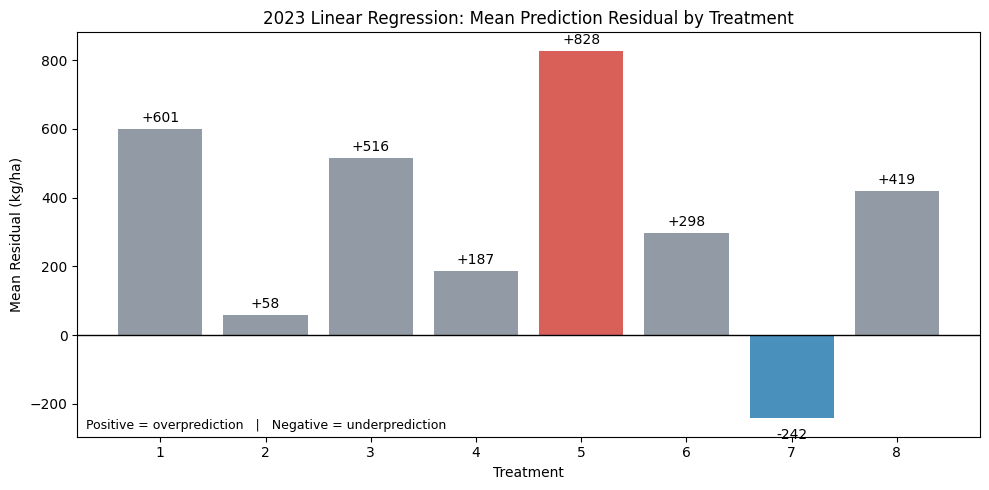

Graph saved: Meeting9_Treatment_Bias_2023.png


In [136]:

# Meeting 9 - Step 18
# Final Presentation Graph: Prediction Bias by Treatment

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

summary = (
    eval_2023.groupby('trt_num')['Residual']
    .mean()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(10, 5))

colors = [
    '#d95f59' if t == 5 else
    '#4a90bd' if t == 7 else
    '#929ba5'
    for t in summary.index
]

ax.bar(
    summary.index.astype(str),
    summary.values,
    color=colors
)

ax.axhline(0, color='black', linewidth=1)

ax.set_title('2023 Linear Regression: Mean Prediction Residual by Treatment')
ax.set_xlabel('Treatment')
ax.set_ylabel('Mean Residual (kg/ha)')

for i, value in enumerate(summary.values):
    ax.annotate(
        f'{value:+.0f}',
        (i, value),
        xytext=(0, 5 if value >= 0 else -15),
        textcoords='offset points',
        ha='center'
    )

ax.text(
    0.01, 0.02,
    'Positive = overprediction   |   Negative = underprediction',
    transform=ax.transAxes,
    fontsize=9
)

plt.tight_layout()
plt.savefig('Meeting9_Treatment_Bias_2023.png', dpi=300, bbox_inches='tight')
plt.show()

print("Graph saved: Meeting9_Treatment_Bias_2023.png")


In [137]:
# Meeting 9 - Step 17B
# Residuals by tillage and fertilizer type (treatment mapping from Karthik's email)
# Requires loyo from the setup cell
import numpy as np
import pandas as pd

mapping = pd.DataFrame({
    'trt_num': [1, 2, 3, 4, 5, 6, 7, 8],
    'fert': ['100%UAN', '50%UAN', 'M-CC', 'M-NCC'] * 2,
    'tillage': ['Conventional'] * 4 + ['Minimum'] * 4
})

m = loyo.merge(mapping, on='trt_num', how='left')
assert m['fert'].notna().all(), "unmapped treatments"

def summ(df):
    return pd.Series({
        'n': len(df),
        'RMSE': np.sqrt((df['res'] ** 2).mean()),
        'Mean residual': df['res'].mean()
    })

print("BY TILLAGE (pooled over 2019, 2020, 2021, 2023):")
print(pd.DataFrame({k: summ(v) for k, v in m.groupby('tillage')}).T.round(1).to_string())

print("\nBY FERTILIZER:")
print(pd.DataFrame({k: summ(v) for k, v in m.groupby('fert')}).T.round(1).to_string())

print("\nRMSE: FERTILIZER x TILLAGE (the 8 treatments):")
print(m.groupby(['fert', 'tillage'])['res'].apply(lambda x: np.sqrt((x ** 2).mean()))
        .unstack().round(1).to_string())

print("\nRMSE by test year, tillage x fertilizer:")
print(m.groupby(['fert', 'tillage', 'test_year'])['res']
        .apply(lambda x: np.sqrt((x ** 2).mean())).unstack().round(0).to_string())

BY TILLAGE (pooled over 2019, 2020, 2021, 2023):
                   n   RMSE  Mean residual
Conventional  2100.0  767.7          -66.2
Minimum       2101.0  885.6         -133.6

BY FERTILIZER:
              n   RMSE  Mean residual
100%UAN  1050.0  967.6          -70.6
50%UAN   1050.0  657.9          -91.3
M-CC     1051.0  880.1         -220.8
M-NCC    1050.0  777.1          -16.8

RMSE: FERTILIZER x TILLAGE (the 8 treatments):
tillage  Conventional  Minimum
fert                          
100%UAN         941.6    992.8
50%UAN          613.2    699.7
M-CC            767.8    979.4
M-NCC           710.7    838.2

RMSE by test year, tillage x fertilizer:
test_year               2019   2020    2021   2023
fert    tillage                                   
100%UAN Conventional  1079.0  571.0  1258.0  690.0
        Minimum       1074.0  610.0  1194.0  995.0
50%UAN  Conventional   664.0  544.0   745.0  461.0
        Minimum        876.0  584.0   773.0  504.0
M-CC    Conventional   824.0  423.

In [138]:

# Meeting 9 - Step 20
# Final Matched Treatment Comparison by Year
# Conventional vs Minimum Tillage
# Same Fertilizer Category
# Includes Overall Consistency, Mean and Median Differences

import numpy as np
import pandas as pd

# Uses 'm' from Step 17B
pair_results = (
    m.groupby(['fert', 'test_year', 'tillage'])['res']
    .agg(
        Count='size',
        RMSE=lambda x: np.sqrt(np.mean(x ** 2)),
        Mean_Residual='mean'
    )
    .reset_index()
)

comparison = pair_results.pivot(
    index=['fert', 'test_year'],
    columns='tillage',
    values=['RMSE', 'Mean_Residual']
)

comparison.columns = [
    f'{metric}_{tillage}'
    for metric, tillage in comparison.columns
]

comparison = comparison.reset_index()

comparison['RMSE_Difference'] = (
    comparison['RMSE_Minimum']
    - comparison['RMSE_Conventional']
)

comparison['Bias_Difference'] = (
    comparison['Mean_Residual_Minimum']
    - comparison['Mean_Residual_Conventional']
)

print("MEETING 9 - STEP 20")
print("MATCHED TREATMENT COMPARISON BY YEAR")
print("Positive RMSE Difference = Minimum Tillage Worse")

print(
    comparison[
        [
            'fert',
            'test_year',
            'RMSE_Conventional',
            'RMSE_Minimum',
            'RMSE_Difference',
            'Mean_Residual_Conventional',
            'Mean_Residual_Minimum',
            'Bias_Difference'
        ]
    ]
    .round(2)
    .to_string(index=False)
)

print("\nNUMBER OF YEARS MINIMUM TILLAGE HAS HIGHER RMSE")

print(
    comparison.groupby('fert')['RMSE_Difference']
    .apply(lambda x: f"{(x > 0).sum()} of {len(x)} years")
    .to_string()
)

# Final overall summary

tot = (comparison['RMSE_Difference'] > 0).sum()

print(
    f"\nOverall: minimum tillage worse in "
    f"{tot} of {len(comparison)} fertilizer-year cells"
)

print(
    "Median RMSE difference (kg/ha):",
    round(comparison['RMSE_Difference'].median(), 1)
)

print(
    "Mean RMSE difference (kg/ha):",
    round(comparison['RMSE_Difference'].mean(), 1)
)


MEETING 9 - STEP 20
MATCHED TREATMENT COMPARISON BY YEAR
Positive RMSE Difference = Minimum Tillage Worse
   fert  test_year  RMSE_Conventional  RMSE_Minimum  RMSE_Difference  Mean_Residual_Conventional  Mean_Residual_Minimum  Bias_Difference
100%UAN       2019            1078.68       1074.39            -4.30                     -364.56                -478.69          -114.13
100%UAN       2020             571.26        609.56            38.30                      -66.58                  65.71           132.29
100%UAN       2021            1258.18       1194.47           -63.71                     -579.93                -582.05            -2.12
100%UAN       2023             690.46        995.10           304.65                      601.29                 827.79           226.50
 50%UAN       2019             664.36        876.08           211.73                       86.36                -313.21          -399.57
 50%UAN       2020             544.49        584.19            39.70    

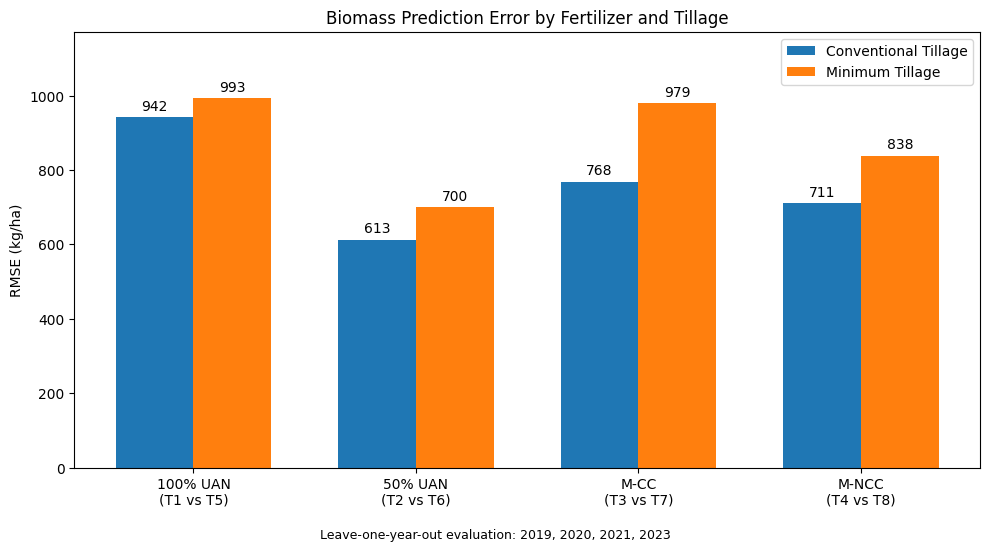

Saved: Meeting9_Management_RMSE.png


In [139]:

# Meeting 9 - Step 21
# Final Graph: Prediction Error by Fertilizer and Tillage

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses m from Step 17B
summary = (
    m.groupby(['fert', 'tillage'])['res']
    .apply(lambda x: np.sqrt(np.mean(x ** 2)))
    .unstack()
)

order = ['100%UAN', '50%UAN', 'M-CC', 'M-NCC']
summary = summary.reindex(order)

x = np.arange(len(summary))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5.5))

bars1 = ax.bar(
    x - width/2,
    summary['Conventional'],
    width,
    label='Conventional Tillage'
)

bars2 = ax.bar(
    x + width/2,
    summary['Minimum'],
    width,
    label='Minimum Tillage'
)

ax.set_xticks(x)
ax.set_xticklabels([
    '100% UAN\n(T1 vs T5)',
    '50% UAN\n(T2 vs T6)',
    'M-CC\n(T3 vs T7)',
    'M-NCC\n(T4 vs T8)'
])

ax.set_ylabel('RMSE (kg/ha)')
ax.set_title(
    'Biomass Prediction Error by Fertilizer and Tillage'
)

ax.bar_label(bars1, fmt='%.0f', padding=3)
ax.bar_label(bars2, fmt='%.0f', padding=3)

ax.legend()
ax.set_ylim(0, summary.max().max() * 1.18)

fig.text(
    0.5, 0.01,
    'Leave-one-year-out evaluation: 2019, 2020, 2021, 2023',
    ha='center',
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    'Meeting9_Management_RMSE.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Saved: Meeting9_Management_RMSE.png")


In [140]:
# Meeting 9 - Step 22
# Baseline vs baseline + tillage / fertilizer, leave-one-year-out (2019, 2020, 2021, 2023)
# 2022 stays in training and is never a test year
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

target = 'dssat_biomass_kg_ha'
base_feats = s2_bands + ['dap']

if 'all_years' not in globals():
    all_years = pd.concat([train_2023, test_2023], ignore_index=True)

d = all_years.copy()
d['trt_num'] = d['treatment'].astype(str).str.extract(r'(\d+)$')[0].astype(int)

# Management variables from Karthik's table
d['min_till'] = (d['trt_num'] >= 5).astype(int)          # 1 = minimum tillage (T5-T8)
fert_names = {1: '100%UAN', 2: '50%UAN', 3: 'M-CC', 4: 'M-NCC'}
d['fert'] = ((d['trt_num'] - 1) % 4 + 1).map(fert_names)
fert_dummies = pd.get_dummies(d['fert'], prefix='fert', drop_first=True).astype(int)
d = pd.concat([d, fert_dummies], axis=1)
fert_cols = list(fert_dummies.columns)

variants = {
    'Baseline': base_feats,
    '22A + tillage': base_feats + ['min_till'],
    '22B + fertilizer': base_feats + fert_cols,
    '22C + both': base_feats + ['min_till'] + fert_cols,
}

test_years = [2019, 2020, 2021, 2023]
parts = []
for name, feats in variants.items():
    for ty in test_years:
        tr = d[d['year'] != ty]
        te = d[d['year'] == ty].copy()
        model = LinearRegression().fit(tr[feats], tr[target])
        te['pred'] = np.maximum(model.predict(te[feats]), 0)
        te['res'] = te['pred'] - te[target]
        te['variant'] = name
        te['test_year'] = ty
        parts.append(te[['variant', 'test_year', 'trt_num', target, 'pred', 'res']])

r22 = pd.concat(parts, ignore_index=True)
rmse = lambda x: np.sqrt((x ** 2).mean())

def overall(df):
    big = df[df[target] > 500]
    within = (np.abs(big['pred'] - big[target]) / big[target] <= 0.10).mean() * 100
    return pd.Series({
        'RMSE': rmse(df['res']),
        'R2': r2_score(df[target], df['pred']),
        'Mean residual': df['res'].mean(),
        '% within 10% (>500)': within,
        'T5 RMSE': rmse(df.loc[df.trt_num == 5, 'res']),
        'T7 RMSE': rmse(df.loc[df.trt_num == 7, 'res']),
    })

pooled = pd.DataFrame({k: overall(v) for k, v in r22.groupby('variant')}).T.loc[list(variants)]
by_year = r22.groupby(['variant', 'test_year'])['res'].apply(rmse).unstack().loc[list(variants)]

base_year = by_year.loc['Baseline']
pooled['RMSE change %'] = 100 * (pooled['RMSE'] / pooled.loc['Baseline', 'RMSE'] - 1)
pooled['Years better than baseline'] = [(by_year.loc[v] < base_year).sum() for v in pooled.index]

print("POOLED OVER 2019, 2020, 2021, 2023:")
print(pooled.round(2).to_string())
print("\nRMSE BY TEST YEAR:")
print(by_year.round(1).to_string())
print("\n2023 only (baseline to beat: 694.235):")
print(by_year[2023].round(3).to_string())

POOLED OVER 2019, 2020, 2021, 2023:
                    RMSE    R2  Mean residual  % within 10% (>500)  T5 RMSE  T7 RMSE  RMSE change %  Years better than baseline
Baseline          828.76  0.88         -99.90                27.75   992.84   979.42           0.00                           0
22A + tillage     827.64  0.88        -101.27                27.59   991.98   966.00          -0.14                           4
22B + fertilizer  834.77  0.88         -92.78                27.84  1018.22   970.04           0.73                           0
22C + both        833.78  0.88         -94.19                27.62  1015.32   960.14           0.61                           0

RMSE BY TEST YEAR:
test_year          2019   2020    2021   2023
variant                                      
Baseline          937.5  591.4  1019.1  694.2
22A + tillage     935.3  590.2  1018.5  693.9
22B + fertilizer  952.3  592.4  1023.2  696.2
22C + both        950.0  591.8  1022.7  695.6

2023 only (baseline to beat

In [141]:
# Meeting 9 - Step 24
# Baseline vs baseline + weather features, leave-one-year-out (2019, 2020, 2021, 2023)
# 2022 stays in training and is never a test year
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

target = 'dssat_biomass_kg_ha'
base_feats = s2_bands + ['dap']
wx = ['dssat_wx_solar_rad', 'dssat_wx_tmax_c', 'dssat_wx_tmin_c']

if 'all_years' not in globals():
    all_years = pd.concat([train_2023, test_2023], ignore_index=True)

d = all_years.copy()
d['trt_num'] = d['treatment'].astype(str).str.extract(r'(\d+)$')[0].astype(int)

# 7-day trailing mean of each weather variable within each simulation run
d = d.sort_values(['run_id', 'dap']).reset_index(drop=True)
for c in wx:
    d[c + '_7d'] = d.groupby('run_id')[c].transform(lambda s: s.rolling(7, min_periods=1).mean())
wx7 = [c + '_7d' for c in wx]

print("Missing values per weather column:")
print(d[wx].isna().sum().to_string())
print("Rows flagged weather missing:", int(d['flag_weather_missing'].sum()))

# Identical rows for every variant
d = d.dropna(subset=wx + wx7).copy()
print("Rows used:", len(d), "\n")

variants = {
    'Baseline': base_feats,
    '+ solar radiation': base_feats + ['dssat_wx_solar_rad'],
    '+ Tmax': base_feats + ['dssat_wx_tmax_c'],
    '+ Tmin': base_feats + ['dssat_wx_tmin_c'],
    '+ all 3 daily': base_feats + wx,
    '+ all 3, 7-day mean': base_feats + wx7,
}

test_years = [2019, 2020, 2021, 2023]
parts = []
for name, feats in variants.items():
    for ty in test_years:
        tr = d[d['year'] != ty]
        te = d[d['year'] == ty].copy()
        model = LinearRegression().fit(tr[feats], tr[target])
        te['pred'] = np.maximum(model.predict(te[feats]), 0)
        te['res'] = te['pred'] - te[target]
        te['variant'] = name
        te['test_year'] = ty
        parts.append(te[['variant', 'test_year', 'trt_num', target, 'pred', 'res']])

r24 = pd.concat(parts, ignore_index=True)
rmse = lambda x: np.sqrt((x ** 2).mean())

def overall(df):
    big = df[df[target] > 500]
    within = (np.abs(big['pred'] - big[target]) / big[target] <= 0.10).mean() * 100
    return pd.Series({
        'RMSE': rmse(df['res']),
        'R2': r2_score(df[target], df['pred']),
        'Mean residual': df['res'].mean(),
        '% within 10% (>500)': within,
        'T5 RMSE': rmse(df.loc[df.trt_num == 5, 'res']),
        'T7 RMSE': rmse(df.loc[df.trt_num == 7, 'res']),
    })

order = list(variants)
pooled = pd.DataFrame({k: overall(v) for k, v in r24.groupby('variant')}).T.loc[order]
by_year = r24.groupby(['variant', 'test_year'])['res'].apply(rmse).unstack().loc[order]

base_year = by_year.loc['Baseline']
pooled['RMSE change %'] = 100 * (pooled['RMSE'] / pooled.loc['Baseline', 'RMSE'] - 1)
pooled['Years better'] = [(by_year.loc[v] < base_year).sum() for v in pooled.index]

print("POOLED OVER 2019, 2020, 2021, 2023:")
print(pooled.round(2).to_string())
print("\nRMSE BY TEST YEAR:")
print(by_year.round(1).to_string())
print("\n2023 only (original baseline to beat: 694.235):")
print(by_year[2023].round(3).to_string())

Missing values per weather column:
dssat_wx_solar_rad    1360
dssat_wx_tmax_c       1360
dssat_wx_tmin_c       1360
Rows flagged weather missing: 1360
Rows used: 3905 

POOLED OVER 2019, 2020, 2021, 2023:
                       RMSE    R2  Mean residual  % within 10% (>500)  T5 RMSE  T7 RMSE  RMSE change %  Years better
Baseline             704.09  0.91           6.58                28.24   747.40   892.25           0.00             0
+ solar radiation    709.41  0.91           9.65                27.74   757.62   890.07           0.76             1
+ Tmax               696.43  0.91          30.16                28.89   731.67   890.13          -1.09             2
+ Tmin               687.73  0.91          18.46                29.64   720.95   878.28          -2.32             4
+ all 3 daily        682.22  0.91          32.35                29.64   717.76   863.04          -3.11             4
+ all 3, 7-day mean  671.92  0.92          64.77                32.35   706.02   832.07      

In [142]:
miss = all_years[all_years['flag_weather_missing'] == 1]
print(miss.groupby('year').size().to_string())
print(miss.groupby('dssat_stage_code').size().to_string())
print(miss.groupby('treatment').size().to_string())

year
2019    272
2020    272
2021    272
2022    272
2023    272
dssat_stage_code
7      28
8    1332
treatment
1    170
2    170
3    170
4    170
5    170
6    170
7    170
8    170


In [143]:
# Meeting 9 - Step 24B
# Baseline vs baseline + weather, with end-of-season weather carried forward
# Leave-one-year-out on 2019, 2020, 2021, 2023; 2022 stays in training
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

target = 'dssat_biomass_kg_ha'
base_feats = s2_bands + ['dap']
wx = ['dssat_wx_solar_rad', 'dssat_wx_tmax_c', 'dssat_wx_tmin_c']

if 'all_years' not in globals():
    all_years = pd.concat([train_2023, test_2023], ignore_index=True)

d = all_years.copy()
d['trt_num'] = d['treatment'].astype(str).str.extract(r'(\d+)$')[0].astype(int)
d = d.sort_values(['run_id', 'dap']).reset_index(drop=True)

# Assumption: weather after maturity equals the last recorded day of the run
for c in wx:
    d[c] = d.groupby('run_id')[c].ffill()

# 7-day trailing mean within each run
for c in wx:
    d[c + '_7d'] = d.groupby('run_id')[c].transform(lambda s: s.rolling(7, min_periods=1).mean())
wx7 = [c + '_7d' for c in wx]

print("Weather still missing after carry-forward:")
print(d[wx].isna().sum().to_string())
d = d.dropna(subset=wx + wx7).copy()
print("Rows used:", len(d), "(should be close to 5265)\n")

variants = {
    'Baseline': base_feats,
    '+ Tmin': base_feats + ['dssat_wx_tmin_c'],
    '+ all 3 daily': base_feats + wx,
    '+ all 3, 7-day mean': base_feats + wx7,
}

parts = []
for name, feats in variants.items():
    for ty in [2019, 2020, 2021, 2023]:
        tr = d[d['year'] != ty]
        te = d[d['year'] == ty].copy()
        model = LinearRegression().fit(tr[feats], tr[target])
        te['pred'] = np.maximum(model.predict(te[feats]), 0)
        te['res'] = te['pred'] - te[target]
        te['variant'] = name
        te['test_year'] = ty
        parts.append(te[['variant', 'test_year', 'trt_num', 'dssat_stage_code', target, 'pred', 'res']])

r24b = pd.concat(parts, ignore_index=True)
rmse = lambda x: np.sqrt((x ** 2).mean())

def overall(df):
    big = df[df[target] > 500]
    within = (np.abs(big['pred'] - big[target]) / big[target] <= 0.10).mean() * 100
    return pd.Series({
        'RMSE': rmse(df['res']),
        'R2': r2_score(df[target], df['pred']),
        'Mean residual': df['res'].mean(),
        '% within 10% (>500)': within,
        'T5 RMSE': rmse(df.loc[df.trt_num == 5, 'res']),
        'T7 RMSE': rmse(df.loc[df.trt_num == 7, 'res']),
    })

order = list(variants)
pooled = pd.DataFrame({k: overall(v) for k, v in r24b.groupby('variant')}).T.loc[order]
by_year = r24b.groupby(['variant', 'test_year'])['res'].apply(rmse).unstack().loc[order]
base_year = by_year.loc['Baseline']
pooled['RMSE change %'] = 100 * (pooled['RMSE'] / pooled.loc['Baseline', 'RMSE'] - 1)
pooled['Years better'] = [(by_year.loc[v] < base_year).sum() for v in pooled.index]

print("POOLED OVER 2019, 2020, 2021, 2023:")
print(pooled.round(2).to_string())
print("\nRMSE BY TEST YEAR:")
print(by_year.round(1).to_string())

r8 = r24b[r24b['dssat_stage_code'] == 8]
print("\nR8 ONLY, RMSE:")
print(r8.groupby('variant')['res'].apply(rmse).loc[order].round(1).to_string())

Weather still missing after carry-forward:
dssat_wx_solar_rad    0
dssat_wx_tmax_c       0
dssat_wx_tmin_c       0
Rows used: 5265 (should be close to 5265)

POOLED OVER 2019, 2020, 2021, 2023:
                       RMSE    R2  Mean residual  % within 10% (>500)  T5 RMSE  T7 RMSE  RMSE change %  Years better
Baseline             828.76  0.88         -99.90                27.75   992.84   979.42           0.00             0
+ Tmin               814.84  0.88         -80.73                28.91   966.64   969.40          -1.68             3
+ all 3 daily        829.69  0.88         -78.06                28.10   991.99   967.03           0.11             1
+ all 3, 7-day mean  834.06  0.88         -75.61                28.65   984.49   976.53           0.64             1

RMSE BY TEST YEAR:
test_year             2019   2020    2021   2023
variant                                         
Baseline             937.5  591.4  1019.1  694.2
+ Tmin               944.1  587.6   991.4  661.9
+ all

In [144]:

# Meeting 9 - Step 24C
# Verify Tmin improvement on identical evaluation rows

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

target = 'dssat_biomass_kg_ha'
base = s2_bands + ['dap']
tmin = 'dssat_wx_tmin_c'
years = [2019, 2020, 2021, 2023]

v = all_years.copy()
v = v.sort_values(['run_id', 'dap']).reset_index(drop=True)

# Preserve whether the original temperature was missing
v['tmin_was_missing'] = v[tmin].isna()

# Last-observed temperature, using only earlier rows in each run
v['tmin_last_observed'] = (
    v.groupby('run_id')[tmin].ffill()
)

assert v['tmin_last_observed'].notna().all()
assert len(v) == 5265

outputs = []

for year in years:
    train = v[v['year'] != year].copy()
    test = v[v['year'] == year].copy()

    # Median computed exclusively on training data
    training_median = train[tmin].median()

    train['tmin_median'] = train[tmin].fillna(training_median)
    test['tmin_median'] = test[tmin].fillna(training_median)

    variants = {
        'Baseline': base,
        'Tmin last-observed': base + ['tmin_last_observed'],
        'Tmin median-imputed': base + ['tmin_median']
    }

    for name, features in variants.items():
        model = LinearRegression()
        model.fit(train[features], train[target])

        pred = np.maximum(
            model.predict(test[features]), 0
        )

        outputs.append(pd.DataFrame({
            'Model': name,
            'Year': year,
            'Missing': test['tmin_was_missing'].to_numpy(),
            'Actual': test[target].to_numpy(),
            'Residual': pred - test[target].to_numpy()
        }))

r24c = pd.concat(outputs, ignore_index=True)

def calculate_rmse(x):
    return np.sqrt(np.mean(x ** 2))

overall = (
    r24c.groupby('Model')['Residual']
    .apply(calculate_rmse)
)

print("OVERALL POOLED RMSE:")
print(overall.round(3).to_string())

print("\nRMSE BY YEAR:")
print(
    r24c.groupby(['Model', 'Year'])['Residual']
    .apply(calculate_rmse)
    .unstack()
    .round(2)
    .to_string()
)

print("\nRMSE BY ORIGINAL WEATHER AVAILABILITY:")
availability = (
    r24c.groupby(['Model', 'Missing'])['Residual']
    .apply(calculate_rmse)
    .unstack()
)

availability.columns = [
    'Weather observed' if not x else 'Weather missing'
    for x in availability.columns
]

print(availability.round(2).to_string())

print("\nCHANGE VS BASELINE BY AVAILABILITY:")
print(
    availability.subtract(
        availability.loc['Baseline'], axis='columns'
    ).round(2).to_string()
)

baseline_2023 = calculate_rmse(
    r24c.loc[
        (r24c['Model'] == 'Baseline') &
        (r24c['Year'] == 2023),
        'Residual'
    ]
)

assert abs(baseline_2023 - 694.235) < 0.02, (
    f"Baseline mismatch: {baseline_2023:.3f}"
)

print("\nBaseline verified:", round(baseline_2023, 3))


OVERALL POOLED RMSE:
Model
Baseline               828.762
Tmin last-observed     814.835
Tmin median-imputed    826.636

RMSE BY YEAR:
Year                   2019    2020     2021    2023
Model                                               
Baseline             937.50  591.44  1019.12  694.23
Tmin last-observed   944.15  587.64   991.45  661.93
Tmin median-imputed  936.80  589.73  1014.81  692.80

RMSE BY ORIGINAL WEATHER AVAILABILITY:
                     Weather observed  Weather missing
Model                                                 
Baseline                       805.28           892.55
Tmin last-observed             798.06           861.02
Tmin median-imputed            803.70           889.00

CHANGE VS BASELINE BY AVAILABILITY:
                     Weather observed  Weather missing
Model                                                 
Baseline                         0.00             0.00
Tmin last-observed              -7.21           -31.53
Tmin median-imputed         

In [145]:

# Meeting 9 - Step 24D
# Is the improvement from temperature or missingness?

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

target = 'dssat_biomass_kg_ha'
base = s2_bands + ['dap']
tmin = 'dssat_wx_tmin_c'

d = all_years.copy()
d = d.sort_values(['run_id', 'dap']).reset_index(drop=True)

d['tmin_missing'] = d[tmin].isna().astype(int)
d['tmin_last'] = d.groupby('run_id')[tmin].ffill()

d['trt_num'] = (
    d['treatment'].astype(str)
    .str.extract(r'(\d+)$')[0].astype(int)
)

assert len(d) == 5265
assert d['tmin_last'].notna().all()
assert d[base + [target]].notna().all().all()

variants = {
    'Baseline': base,
    '+ missing indicator': base + ['tmin_missing'],
    '+ last-observed Tmin': base + ['tmin_last'],
    '+ Tmin and indicator': base + ['tmin_last', 'tmin_missing']
}

parts = []

for name, feats in variants.items():
    for ty in [2019, 2020, 2021, 2023]:

        train = d[d['year'] != ty]
        test = d[d['year'] == ty]

        model = LinearRegression().fit(
            train[feats], train[target]
        )

        pred = np.maximum(
            model.predict(test[feats]), 0
        )

        out = pd.DataFrame({
            'Model': name,
            'Year': ty,
            'Treatment': test['trt_num'].to_numpy(),
            'Missing': test['tmin_missing'].to_numpy(),
            'Actual': test[target].to_numpy(),
            'Pred': pred
        })

        out['Residual'] = out['Pred'] - out['Actual']
        parts.append(out)

r24d = pd.concat(parts, ignore_index=True)

def rmse(x):
    return np.sqrt(np.mean(np.asarray(x) ** 2))

rows = []

for name in variants:
    g = r24d[r24d['Model'] == name]
    eligible = g['Actual'] > 500

    rows.append({
        'Model': name,
        'RMSE': rmse(g['Residual']),
        'R2': r2_score(g['Actual'], g['Pred']),
        'Mean residual': g['Residual'].mean(),
        'Within 10% (>500)': (
            100 * (
                np.abs(g.loc[eligible, 'Residual'])
                <= 0.10 * g.loc[eligible, 'Actual']
            ).mean()
        ),
        'T5 RMSE': rmse(
            g.loc[g['Treatment'] == 5, 'Residual']
        ),
        'T7 RMSE': rmse(
            g.loc[g['Treatment'] == 7, 'Residual']
        )
    })

summary = pd.DataFrame(rows).set_index('Model')

print("POOLED RESULTS:")
print(summary.round(3).to_string())

print("\nRMSE BY YEAR:")
print(
    r24d.groupby(['Model', 'Year'])['Residual']
    .apply(rmse)
    .unstack()
    .reindex(variants)
    .round(2)
    .to_string()
)

print("\nRMSE BY WEATHER AVAILABILITY:")
print(
    r24d.groupby(['Model', 'Missing'])['Residual']
    .apply(rmse)
    .unstack()
    .reindex(variants)
    .rename(columns={
        0: 'Weather observed',
        1: 'Weather missing'
    })
    .round(2)
    .to_string()
)

baseline = rmse(
    r24d.loc[
        (r24d['Model'] == 'Baseline') &
        (r24d['Year'] == 2023),
        'Residual'
    ]
)

assert abs(baseline - 694.235) < 0.02
print("\nBaseline reproduced:", round(baseline, 3))


POOLED RESULTS:
                         RMSE     R2  Mean residual  Within 10% (>500)   T5 RMSE  T7 RMSE
Model                                                                                    
Baseline              828.762  0.877        -99.898             27.747   992.837  979.420
+ missing indicator   815.257  0.881        -98.475             28.947  1004.187  939.089
+ last-observed Tmin  814.835  0.881        -80.728             28.914   966.637  969.400
+ Tmin and indicator  797.801  0.886        -80.252             30.535   974.179  925.648

RMSE BY YEAR:
Year                    2019    2020     2021    2023
Model                                                
Baseline              937.50  591.44  1019.12  694.23
+ missing indicator   920.54  569.85  1007.13  688.43
+ last-observed Tmin  944.15  587.64   991.45  661.93
+ Tmin and indicator  928.23  564.46   974.03  647.27

RMSE BY WEATHER AVAILABILITY:
Missing               Weather observed  Weather missing
Model             

In [146]:

# Meeting 9 - Step 24E
# Nonlinear DAP and temperature interaction
# Objective: improve RMSE without a missingness indicator

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

target = 'dssat_biomass_kg_ha'
base = s2_bands + ['dap']

d = all_years.copy()
d = d.sort_values(['run_id', 'dap']).reset_index(drop=True)

# Validate run identity before carrying weather forward
assert (
    d.groupby('run_id')['year'].nunique().max() == 1
), "A run_id spans multiple years; check grouping."

d['tmin_missing'] = d['dssat_wx_tmin_c'].isna().astype(int)

d['tmin_last'] = (
    d.groupby('run_id')['dssat_wx_tmin_c'].ffill()
)

# Nonlinear growth and weather interaction
d['dap_squared'] = d['dap'] ** 2
d['dap_x_tmin'] = d['dap'] * d['tmin_last']

assert len(d) == 5265
assert d[['tmin_last', 'dap_squared', 'dap_x_tmin']].notna().all().all()

d['trt_num'] = (
    d['treatment'].astype(str)
    .str.extract(r'(\d+)$')[0].astype(int)
)

variants = {
    'Baseline': base,
    '+ DAP squared': base + ['dap_squared'],
    '+ Tmin': base + ['tmin_last'],
    '+ Tmin + DAP squared':
        base + ['tmin_last', 'dap_squared'],
    '+ Tmin + DAP interaction':
        base + ['tmin_last', 'dap_x_tmin'],
    '+ Tmin + both nonlinear terms':
        base + ['tmin_last', 'dap_squared', 'dap_x_tmin'],
    '24D best (reference)':
        base + ['tmin_last', 'tmin_missing']
}

parts = []

for name, feats in variants.items():
    for year in [2019, 2020, 2021, 2023]:
        train = d[d['year'] != year]
        test = d[d['year'] == year]

        model = LinearRegression()
        model.fit(train[feats], train[target])

        pred = np.clip(
            model.predict(test[feats]), 0, None
        )

        out = pd.DataFrame({
            'Model': name,
            'Year': year,
            'Treatment': test['trt_num'].to_numpy(),
            'Missing': test['tmin_missing'].to_numpy(),
            'Actual': test[target].to_numpy(),
            'Pred': pred
        })

        out['Residual'] = out['Pred'] - out['Actual']
        parts.append(out)

r24e = pd.concat(parts, ignore_index=True)

def rmse(x):
    return np.sqrt(np.mean(np.asarray(x) ** 2))

rows = []

for name in variants:
    g = r24e[r24e['Model'] == name]
    eligible = g['Actual'] > 500

    rows.append({
        'Model': name,
        'RMSE': rmse(g['Residual']),
        'R2': r2_score(g['Actual'], g['Pred']),
        'Within 10% (>500)': 100 * (
            np.abs(g.loc[eligible, 'Residual'])
            <= 0.10 * g.loc[eligible, 'Actual']
        ).mean(),
        'T5 RMSE': rmse(
            g.loc[g['Treatment'] == 5, 'Residual']
        ),
        'T7 RMSE': rmse(
            g.loc[g['Treatment'] == 7, 'Residual']
        )
    })

summary = pd.DataFrame(rows).set_index('Model')

by_year = (
    r24e.groupby(['Model', 'Year'])['Residual']
    .apply(rmse)
    .unstack()
    .reindex(variants)
)

summary['Years better'] = [
    int((by_year.loc[name] < by_year.loc['Baseline']).sum())
    for name in summary.index
]

print("POOLED PERFORMANCE:")
print(summary.round(3).to_string())

print("\nRMSE BY YEAR:")
print(by_year.round(2).to_string())

print("\nRMSE BY WEATHER AVAILABILITY:")
print(
    r24e.groupby(['Model', 'Missing'])['Residual']
    .apply(rmse)
    .unstack()
    .reindex(variants)
    .rename(columns={
        0: 'Weather observed',
        1: 'Weather missing'
    })
    .round(2)
    .to_string()
)

print("\n2023 RMSE:")
print(by_year[2023].round(3).to_string())

assert abs(by_year.loc['Baseline', 2023] - 694.235) < 0.02

print("\nBaseline verified.")


POOLED PERFORMANCE:
                                  RMSE     R2  Within 10% (>500)   T5 RMSE  T7 RMSE  Years better
Model                                                                                            
Baseline                       828.762  0.877             27.747   992.837  979.420             0
+ DAP squared                  820.060  0.880             28.460  1004.992  962.972             4
+ Tmin                         814.835  0.881             28.914   966.637  969.400             3
+ Tmin + DAP squared           798.540  0.886             31.475   970.775  948.365             3
+ Tmin + DAP interaction       799.343  0.886             32.609   939.279  967.810             3
+ Tmin + both nonlinear terms  798.373  0.886             32.447   965.674  951.168             3
24D best (reference)           797.801  0.886             30.535   974.179  925.648             4

RMSE BY YEAR:
Year                             2019    2020     2021    2023
Model               

In [147]:

# Meeting 9 - Step 24F
# Stress-test leading nonlinear models on held-out 2022
# Train on 2019, 2020, 2021, 2023; test on 2022

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

target = 'dssat_biomass_kg_ha'
base = s2_bands + ['dap']

d = all_years.copy()
d = d.sort_values(['run_id', 'dap']).reset_index(drop=True)

d['tmin_missing'] = d['dssat_wx_tmin_c'].isna().astype(int)
d['tmin_last'] = d.groupby('run_id')['dssat_wx_tmin_c'].ffill()
d['dap_squared'] = d['dap'] ** 2
d['dap_x_tmin'] = d['dap'] * d['tmin_last']

d['trt_num'] = (
    d['treatment'].astype(str)
    .str.extract(r'(\d+)$')[0].astype(int)
)

assert len(d) == 5265
assert d[['tmin_last', 'dap_squared', 'dap_x_tmin']].notna().all().all()

variants = {
    'Baseline': base,
    'Tmin + DAP squared':
        base + ['tmin_last', 'dap_squared'],
    'Tmin + DAP interaction':
        base + ['tmin_last', 'dap_x_tmin'],
    'Tmin + both nonlinear terms':
        base + ['tmin_last', 'dap_squared', 'dap_x_tmin'],
    'Tmin + missing indicator (reference)':
        base + ['tmin_last', 'tmin_missing']
}

train = d[d['year'] != 2022]
test = d[d['year'] == 2022].copy()

results = []
predictions = []

for name, feats in variants.items():
    model = LinearRegression()
    model.fit(train[feats], train[target])

    pred = np.clip(model.predict(test[feats]), 0, None)
    actual = test[target].to_numpy()
    residual = pred - actual
    eligible = actual > 500

    results.append({
        'Model': name,
        'RMSE': np.sqrt(np.mean(residual ** 2)),
        'R2': r2_score(actual, pred),
        'Mean residual': residual.mean(),
        'Within 10% (>500)': 100 * np.mean(
            np.abs(residual[eligible]) <= 0.10 * actual[eligible]
        ),
        'T5 RMSE': np.sqrt(np.mean(
            residual[test['trt_num'].to_numpy() == 5] ** 2
        )),
        'T7 RMSE': np.sqrt(np.mean(
            residual[test['trt_num'].to_numpy() == 7] ** 2
        ))
    })

    predictions.append(pd.DataFrame({
        'Model': name,
        'Stage': test['dssat_stage_code'].to_numpy(),
        'Residual': residual
    }))

summary = pd.DataFrame(results).set_index('Model')

summary['RMSE change %'] = (
    100 * (
        summary['RMSE'] / summary.loc['Baseline', 'RMSE'] - 1
    )
)

print("2022 HELD-OUT STRESS TEST:")
print(summary.round(3).to_string())

p = pd.concat(predictions, ignore_index=True)

print("\n2022 RMSE BY GROWTH STAGE:")
print(
    p.groupby(['Model', 'Stage'])['Residual']
    .apply(lambda x: np.sqrt(np.mean(x ** 2)))
    .unstack()
    .reindex(variants)
    .round(1)
    .to_string()
)

print("\nTraining rows:", len(train))
print("2022 test rows:", len(test))


2022 HELD-OUT STRESS TEST:
                                         RMSE     R2  Mean residual  Within 10% (>500)   T5 RMSE  T7 RMSE  RMSE change %
Model                                                                                                                   
Baseline                              977.722  0.226        521.789             17.203   950.253  957.125          0.000
Tmin + DAP squared                    994.909  0.199        574.248             14.233  1063.747  882.924          1.758
Tmin + DAP interaction                986.054  0.213        505.289             19.431   991.467  975.100          0.852
Tmin + both nonlinear terms           995.745  0.198        571.506             13.243  1065.765  900.784          1.843
Tmin + missing indicator (reference)  992.640  0.203        553.990             15.223  1101.953  899.201          1.526

2022 RMSE BY GROWTH STAGE:
Stage                                     0      1      3      5      7       8
Model             

Stage column: dssat_stage_name
Stage order (by median DAP): ['Vegetative, before first flower', 'R1 first flower', 'R3 first boll', 'R5 boll filling', 'R7 physiological maturity begins', 'R8 harvest maturity']

REFERENCE MEAN BIOMASS (kg/ha), mean of yearly means:
dssat_stage_name  Vegetative, before first flower  R1 first flower  R3 first boll  R5 boll filling  R7 physiological maturity begins  R8 harvest maturity
trt_num                                                                                                                                                  
1                                            76.0            516.0          882.0           3290.0                            5817.0               5674.0
2                                            76.0            519.0          887.0           3117.0                            4432.0               3992.0
3                                           231.0           1394.0         2098.0           4740.0                     

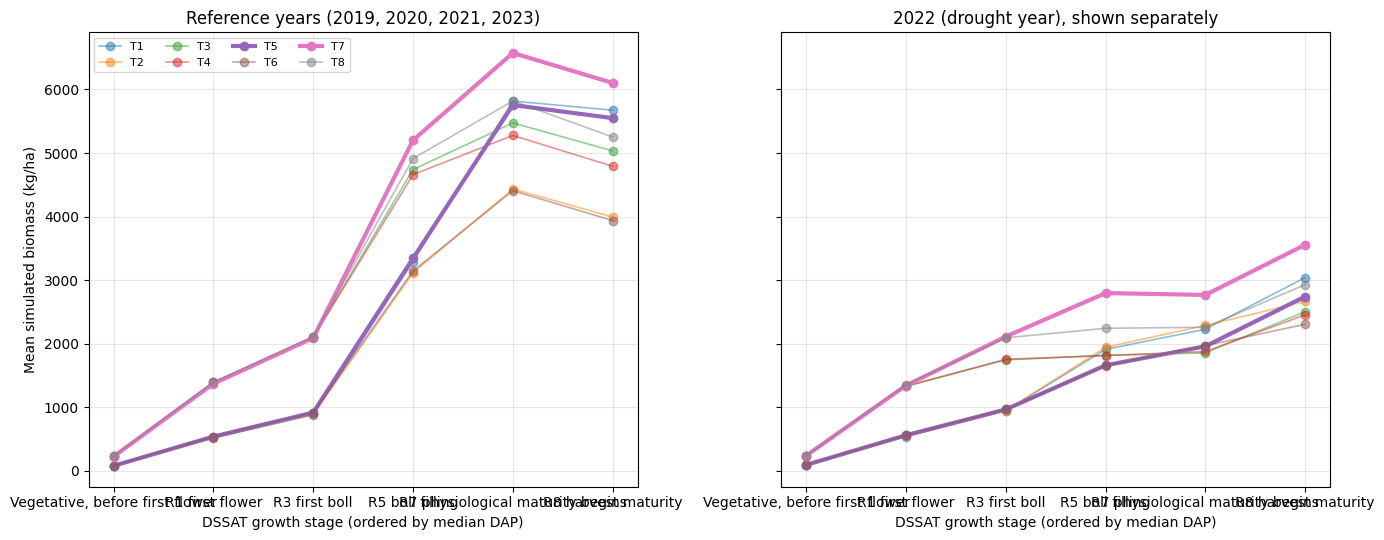

In [148]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

target = 'dssat_biomass_kg_ha'
reference_years = [2019, 2020, 2021, 2023]

d = all_years.copy()
d['trt_num'] = d['treatment'].astype(str).str.extract(r'(\d+)$')[0].astype(int)

stage_col = 'dssat_stage_name' if 'dssat_stage_name' in d.columns else 'dssat_stage_code'
stage_order = (d.groupby(stage_col)['dap'].median()
                 .sort_values().index.tolist())
print("Stage column:", stage_col)
print("Stage order (by median DAP):", stage_order)

# Mean and count per year x treatment x stage
yr = (d.groupby(['year', 'trt_num', stage_col])[target]
        .agg(['mean', 'count']).reset_index())

# ---------- REFERENCE VIEW: 2019, 2020, 2021, 2023 ----------
ref = yr[yr['year'].isin(reference_years)]
ref_mean = (ref.groupby(['trt_num', stage_col])['mean'].mean()
              .unstack().reindex(columns=stage_order))   # mean of yearly means
ref_obs = (ref.groupby(['trt_num', stage_col])['count'].sum()
             .unstack().reindex(columns=stage_order))

print("\nREFERENCE MEAN BIOMASS (kg/ha), mean of yearly means:")
print(ref_mean.round(0).to_string())
print("\nREFERENCE TOTAL OBSERVATIONS:")
print(ref_obs.to_string())
print("\nREFERENCE CHANGE FROM PREVIOUS STAGE:")
print(ref_mean.diff(axis=1).round(0).to_string())

# ---------- HOW THIN ARE THE STAGES PER TREATMENT-YEAR? ----------
per_ty = (ref.pivot_table(index=['year', 'trt_num'], columns=stage_col,
                          values='count').reindex(columns=stage_order))
print("\nOBSERVATIONS PER TREATMENT-YEAR (min / median / max):")
print(pd.DataFrame({'min': per_ty.min(), 'median': per_ty.median(),
                    'max': per_ty.max()}).to_string())
thin = [s for s in stage_order if per_ty[s].median() <= 10]
print("\nThin stages (median <= 10 per treatment-year):", thin)
if thin:
    print(per_ty[thin].to_string())

# ---------- 2022 SEPARATELY ----------
y22 = yr[yr['year'] == 2022]
m22 = y22.pivot(index='trt_num', columns=stage_col, values='mean').reindex(columns=stage_order)
c22 = y22.pivot(index='trt_num', columns=stage_col, values='count').reindex(columns=stage_order)
print("\n2022 MEAN BIOMASS (kg/ha):")
print(m22.round(0).to_string())
print("\n2022 OBSERVATIONS:")
print(c22.to_string())
print("\n2022 CHANGE FROM PREVIOUS STAGE:")
print(m22.diff(axis=1).round(0).to_string())

# ---------- PLOT: two panels ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, tbl, title in [(axes[0], ref_mean, 'Reference years (2019, 2020, 2021, 2023)'),
                       (axes[1], m22, '2022 (drought year), shown separately')]:
    for t in tbl.index:
        hl = t in (5, 7)
        ax.plot(stage_order, tbl.loc[t], marker='o',
                lw=3 if hl else 1.2, alpha=1 if hl else 0.5, label=f'T{t}')
    ax.set_title(title)
    ax.set_xlabel('DSSAT growth stage (ordered by median DAP)')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Mean simulated biomass (kg/ha)')
axes[0].legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig('Task1_biomass_by_stage.png', dpi=200)
plt.show()

In [149]:
print([k for k in globals() if 'pred' in k.lower() or 'loo' in k.lower()])

['y_pred', 'rf_pred', 'selected_pred', 'year_linear_pred', 'year_rf_pred', 'high_pred', 'lr_3_pred', 'rf_3_pred', 'pred', 'pred_s2_full', 'pred_s2_reduced', 'predictions', 'year_linear_pred_clipped', 'low_pred_before', 'low_pred_after', 'prediction_vars', 'pred_s2_dap', 'pred_s2_dap_clipped', 'pred_2022', 'pred_2022_clipped', 'pred_stage_2022', 'pred_stage_2022_clipped', 'pred_soil_2022', 'pred_soil_2022_clipped', 'baseline_pred', 'stage_pred', 'soil_pred', 'pred_base_2023', 'pred_stage_2023', 'pred_soil_2023', 'raw_predictions', 'clipped_predictions', 'log_predictions', 'gamma_predictions', 'lr_predictions', 'nn_raw_predictions', 'nn_predictions', 'nn_pred_2022_check', 'baseline_predictions', 'pred_normal_2023', 'pred_existing_2023', 'specific_pred', 'ridge_pred']


In [150]:
import numpy as np, pandas as pd
from sklearn.linear_model import LinearRegression

target = 'dssat_biomass_kg_ha'
feats = s2_bands + ['dap']
held_out_years = [2019, 2020, 2021, 2023]   # 2022 stays in training every fold

d = all_years.copy().reset_index(drop=True)
d['trt_num'] = d['treatment'].astype(str).str.extract(r'(\d+)$')[0].astype(int)
d['stage'] = d['dssat_stage_name'].map(lambda s: 'Veg' if s.startswith('Veg') else s.split(' ')[0])

# ---- Rebuild official baseline predictions (clipped Linear Regression) ----
parts = []
for y in held_out_years:
    tr, te = d[d['year'] != y], d[d['year'] == y].copy()
    m = LinearRegression().fit(tr[feats], tr[target])
    te['pred'] = np.clip(m.predict(te[feats]), 0, None)
    te['resid'] = te['pred'] - te[target]
    parts.append(te)
loo = pd.concat(parts, ignore_index=True)

# ---- SELF-CHECK: must match the verified record ----
rmse = lambda r: np.sqrt(np.mean(np.asarray(r) ** 2))
print("CHECK pooled RMSE (expect 828.762):", round(rmse(loo['resid']), 3), "| rows (expect 4201):", len(loo))
print("CHECK by year (expect 937.5, 591.4, 1019.1, 694.2):",
      {y: round(rmse(loo.loc[loo.year == y, 'resid']), 1) for y in held_out_years})

# ---- Groups of interest ----
def grp(r):
    if r.trt_num == 5 and r.stage == 'R8': return 'T5-R8'
    if r.trt_num == 7 and r.stage == 'R5': return 'T7-R5'
    if r.trt_num not in (5, 7) and r.stage == 'R8': return 'Other6-R8'
    if r.trt_num not in (5, 7) and r.stage == 'R5': return 'Other6-R5'
    return None
loo['grp'] = loo.apply(grp, axis=1)
g = loo.dropna(subset=['grp'])

out = (g.groupby(['grp', 'year'])
         .agg(n=(target, 'size'), actual_mean=(target, 'mean'),
              pred_mean=('pred', 'mean'), mean_resid=('resid', 'mean'),
              rmse=('resid', rmse))
         .round(1))
print("\nACTUAL vs PREDICTED by group and held-out year (kg/ha):")
print(out.to_string())

pooled = (g.groupby('grp').agg(n=(target, 'size'), mean_resid=('resid', 'mean'),
                               rmse=('resid', rmse)).round(1))
print("\nPOOLED over the four held-out years:")
print(pooled.to_string())

# Share of each treatment's squared error from its focus stage (verify ~69% and ~66% were 2023 figures)
for t, s in [(5, 'R8'), (7, 'R5')]:
    x = loo[(loo.trt_num == t) & (loo.year == 2023)]
    share = (x.loc[x.stage == s, 'resid'] ** 2).sum() / (x['resid'] ** 2).sum()
    print(f"2023 T{t}-{s} share of T{t} squared error: {100*share:.1f}%")

# 2022 reference for the same groups (actual biomass only, 2022 was not held out here)
r22 = d[(d.year == 2022)].copy()
r22['grp'] = r22.apply(grp, axis=1)
print("\n2022 ACTUAL mean biomass for same groups (context only):")
print(r22.dropna(subset=['grp']).groupby('grp')[target].mean().round(1).to_string())

CHECK pooled RMSE (expect 828.762): 828.762 | rows (expect 4201): 4201
CHECK by year (expect 937.5, 591.4, 1019.1, 694.2): {2019: np.float64(937.5), 2020: np.float64(591.4), 2021: np.float64(1019.1), 2023: np.float64(694.2)}

ACTUAL vs PREDICTED by group and held-out year (kg/ha):
                  n  actual_mean  pred_mean  mean_resid    rmse
grp       year                                                 
Other6-R5 2019  214       3977.1     3928.6       -48.5   944.1
          2020  202       3842.0     3980.7       138.7   732.7
          2021  220       4487.5     3980.5      -507.1  1206.7
          2023  199       3563.9     3780.6       216.7   669.8
Other6-R8 2019  200       5061.9     4534.2      -527.7   924.0
          2020  206       4470.6     4433.0       -37.6   514.3
          2021  188       5621.7     4837.7      -784.0   907.0
          2023  221       3973.8     4683.6       709.9   797.8
T5-R8     2019   33       6065.8     4523.7     -1542.1  1592.2
          2020

In [151]:
rmse = lambda r: np.sqrt(np.mean(np.asarray(r) ** 2))
order = ['Veg', 'R1', 'R3', 'R5', 'R7', 'R8']

# Error by stage, pooled over the four held-out years
st = (loo.groupby('stage').agg(n=(target, 'size'), actual_mean=(target, 'mean'),
        mean_resid=('resid', 'mean'), rmse=('resid', rmse)).reindex(order).round(1))
st['share_of_sq_error_%'] = (100 * loo.groupby('stage')['resid'].apply(lambda x: (x**2).sum())
                             / (loo['resid']**2).sum()).reindex(order).round(1)
print("ERROR BY STAGE (pooled, 4 held-out years):")
print(st.to_string())

# R1/R3 by year, with counts, so thin groups are visible
e = loo[loo.stage.isin(['R1', 'R3'])]
print("\nR1/R3 BY STAGE x YEAR:")
print(e.groupby(['stage', 'year']).agg(n=(target, 'size'), actual_mean=(target, 'mean'),
        pred_mean=('pred', 'mean'), mean_resid=('resid', 'mean'),
        rmse=('resid', rmse)).round(1).to_string())

# R1/R3 by treatment, pooled
print("\nR1/R3 BY TREATMENT (pooled):")
print(e.groupby(['stage', 'trt_num']).agg(n=(target, 'size'), mean_resid=('resid', 'mean'),
        rmse=('resid', rmse)).round(1).unstack(0).to_string())

ERROR BY STAGE (pooled, 4 held-out years):
          n  actual_mean  mean_resid    rmse  share_of_sq_error_%
stage                                                            
Veg    1168        153.6        50.7   274.5                  3.1
R1      200        966.0       464.7   653.2                  3.0
R3      153       1491.9       828.6  1051.9                  5.9
R5     1116       4055.7      -114.9  1002.1                 38.8
R7      480       5444.1      -770.1  1114.4                 20.7
R8     1084       5003.7      -185.2   872.8                 28.6

R1/R3 BY STAGE x YEAR:
             n  actual_mean  pred_mean  mean_resid    rmse
stage year                                                
R1    2019  48        857.5     1429.3       571.8   686.5
      2020  56       1146.0     1422.7       276.7   599.1
      2021  48        995.2     1506.0       510.7   702.3
      2023  48        835.2     1366.0       530.8   628.2
R3    2019  40       1343.8     2158.4       814.6 

In [152]:
print(s2_bands)
print(all_years.columns.tolist()[:15])
print(all_years.shape)

['S2_B1_CoastalAerosol', 'S2_B2_Blue', 'S2_B3_Green', 'S2_B4_Red', 'S2_B5_RedEdge1', 'S2_B6_RedEdge2', 'S2_B7_RedEdge3', 'S2_B8_NIR', 'S2_B8A_NIR_Narrow', 'S2_B9_WaterVapor', 'S2_B11_SWIR1', 'S2_B12_SWIR2']
['run_id', 'treatment', 'year', 'calendar_date', 'doy', 'dap', 'dssat_stage_code', 'dssat_stage_name', 'dssat_biomass_kg_ha', 'HLS_Blue', 'HLS_Green', 'HLS_Red', 'HLS_NIR', 'HLS_SWIR1', 'HLS_SWIR2']
(5265, 37)


In [153]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

target = 'dssat_biomass_kg_ha'
tr = df_clean[df_clean['year'] < 2023]
te = df_clean[df_clean['year'] == 2023]
sets = {'DAP only': ['dap'],
        '12 S2 bands only': s2_bands,
        '12 S2 bands + DAP': s2_bands + ['dap']}
for name, f in sets.items():
    p = np.maximum(LinearRegression().fit(tr[f], tr[target]).predict(te[f]), 0)
    print(f"{name:20s} RMSE {np.sqrt(np.mean((p - te[target])**2)):7.1f}   R2 {r2_score(te[target], p):.3f}")

DAP only             RMSE  1129.6   R2 0.675
12 S2 bands only     RMSE  1034.4   R2 0.728
12 S2 bands + DAP    RMSE   694.2   R2 0.877
